# EBB-Net: Next-Week Engagement-Decline Prediction on OULAD
**End-to-end pipeline** — data staging, preprocessing, feature engineering, target engineering, EDA, leakage checks, model training (EBB-Net, ablations A1–A5, SOTA models MLP / GRU / TCN), evaluation, calibration and explainability.

**Task.** From a 6-week history ending at week *t*, predict whether the student's behaviour in week *t+1* is more than 10% below their own recent baseline:
`D(t+1) = mean over {total_clicks, active_days, unique_sites} of log((1 + c(t+1)) / (1 + median of c over weeks t-4..t))`, `y = 1 ⇔ D(t+1) < log(0.90)`.

**How to run:** (1) Runtime ▸ Change runtime type ▸ GPU. (2) Set `DATASET_PATH` in the next cell. (3) Runtime ▸ Run all (approve the Google Drive prompt once).
All outputs are written to `EBB-Net_Outputs`, placed next to the dataset. After a disconnect, run all again: finished stages are skipped and unfinished training resumes from the last saved epoch.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Configuration

In [2]:
# Paste the Google Drive path of the OULAD dataset: a .zip file, or a folder containing the 7 CSV files
DATASET_PATH = "/content/drive/MyDrive/hari/EBB-NET-REWORK/oulad.zip"
QUICK_TEST = False   # True runs a tiny smoke test (subsampled data, 2 epochs)

In [3]:
# Install dependencies and import libraries
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "-q", "install", "shap", "lime", "torchinfo", "tabulate"], check=False)
import os, re, gc, json, math, time, random, shutil, pickle, zipfile, hashlib, warnings
from pathlib import Path
from copy import deepcopy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             balanced_accuracy_score, brier_score_loss, accuracy_score, log_loss, precision_recall_curve, roc_curve)
try:
    from IPython.display import display
except Exception:
    display = print
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120); pd.set_option("display.width", 170)
plt.rcParams.update({"font.size": 18, "axes.titlesize": 18, "axes.labelsize": 18, "xtick.labelsize": 16, "ytick.labelsize": 16,
                     "legend.fontsize": 16, "figure.dpi": 100, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("torch", torch.__version__, "| device:", DEVICE, "| AMP:", USE_AMP)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))
else: print("WARNING: no GPU found. Runtime > Change runtime type > GPU (CPU training is very slow).")

torch 2.11.0+cu130 | device: cuda | AMP: True
GPU: Tesla T4


In [4]:
# Mount Drive, set the output folder next to the dataset, restore earlier progress, stage the raw CSVs
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Google Drive not mounted:", type(e).__name__)

OUT_NAME = "EBB-Net_Outputs" + ("_QUICK" if QUICK_TEST else "")
LOCAL_OUT = Path("/content") / OUT_NAME; LOCAL_OUT.mkdir(parents=True, exist_ok=True)
RUN_ROOT, PREP_DIR = LOCAL_OUT, LOCAL_OUT / "prepared_data"
RAW_DIR = Path("/content/oulad_raw")
OULAD_FILES = ["courses", "assessments", "vle", "studentInfo", "studentRegistration", "studentAssessment", "studentVle"]

_src = str(DATASET_PATH).strip()
if _src.startswith("http"):
    SRC, DRIVE_OUT = None, Path("/content/drive/MyDrive/hari/EBB-NET-REWORK") / OUT_NAME      # a share link has no parent folder: outputs go to MyDrive
else:
    SRC = Path(_src).expanduser()
    assert SRC.exists(), f"DATASET_PATH not found: {SRC}"
    DRIVE_OUT = SRC.parent / OUT_NAME
try:
    DRIVE_OUT.mkdir(parents=True, exist_ok=True); BACKUP = True
except Exception as e:
    BACKUP = False; print("Drive output folder not writable, results stay in", LOCAL_OUT, "|", e)

def sync(src, dst, exclude=()):
    # copy new or changed files from src to dst (atomic per file); returns the number of files copied
    src, dst, n = Path(src), Path(dst), 0
    for p in src.rglob("*"):
        if not p.is_file() or p.name in exclude or p.suffix == ".tmp": continue
        q = dst / p.relative_to(src)
        if q.exists() and q.stat().st_size == p.stat().st_size and q.stat().st_mtime >= p.stat().st_mtime - 2: continue
        q.parent.mkdir(parents=True, exist_ok=True)
        tmp = q.with_name(q.name + ".tmp"); shutil.copy2(p, tmp); os.replace(tmp, q); n += 1
    return n

def push(path=None, exclude=()):
    # back up a local output folder to the Drive output folder (safe to call often)
    if not BACKUP: return
    p = Path(path) if path else LOCAL_OUT
    try: sync(p, DRIVE_OUT / p.relative_to(LOCAL_OUT), exclude)
    except Exception as e: print("Drive sync warning:", e)

if BACKUP and any(DRIVE_OUT.iterdir()):
    print("Restoring previous progress from", DRIVE_OUT, "..."); print("files restored:", sync(DRIVE_OUT, LOCAL_OUT))
RUN_PREP = not (PREP_DIR / "PREP_DONE.json").exists()

def stage_dataset():
    if all((RAW_DIR / f"{n}.csv").exists() for n in OULAD_FILES): print("raw CSVs already staged"); return
    RAW_DIR.mkdir(parents=True, exist_ok=True); src = SRC
    if src is None:
        import gdown
        src = Path("/content/dataset_download"); src.mkdir(exist_ok=True)
        try: gdown.download_folder(url=_src, output=str(src), quiet=True, use_cookies=False)
        except Exception: gdown.download(url=_src, output=str(src / "dataset.zip"), quiet=True, fuzzy=True)
    want = {n.lower(): n for n in OULAD_FILES}; found = {}
    if src.is_dir():
        for c in sorted(src.rglob("*.csv")):
            if c.stem.lower() in want and "__MACOSX" not in str(c) and want[c.stem.lower()] not in found:
                found[want[c.stem.lower()]] = c; shutil.copy(c, RAW_DIR / f"{want[c.stem.lower()]}.csv")
    if len(found) < len(OULAD_FILES):
        zips = [src] if src.is_file() else sorted(src.rglob("*.zip"))
        for z in zips:
            lz = Path("/content/dataset_local.zip"); print("copying", z.name, "to local disk ...")
            shutil.copy(z, lz)
            with zipfile.ZipFile(lz) as zf:
                for m in tqdm(zf.namelist(), desc="extracting"):
                    stem = Path(m).stem.lower()
                    if m.lower().endswith(".csv") and stem in want and "__MACOSX" not in m and want[stem] not in found:
                        with zf.open(m) as fi, open(RAW_DIR / f"{want[stem]}.csv", "wb") as fo: shutil.copyfileobj(fi, fo)
                        found[want[stem]] = m
            lz.unlink()
    missing = [n for n in OULAD_FILES if n not in found]
    assert not missing, f"missing OULAD files in {_src}: {missing}"
    print("staged", len(found), "CSV files in", RAW_DIR)

if RUN_PREP: stage_dataset()
else: print("Prepared data found in the output folder: preprocessing is skipped.")
print("Outputs:", DRIVE_OUT if BACKUP else LOCAL_OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Restoring previous progress from /content/drive/MyDrive/hari/EBB-NET-REWORK/EBB-Net_Outputs ...
files restored: 1331
Prepared data found in the output folder: preprocessing is skipped.
Outputs: /content/drive/MyDrive/hari/EBB-NET-REWORK/EBB-Net_Outputs


In [5]:
# Settings: data preparation, task, experiment, optimisation, architecture, tuning, plots
# ---- data preparation
SEED = 42
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}
SPLIT_UNIT = "enrollment"      # "student" | "student_presentation" | "enrollment"
STRATIFY = True                # stratify by module-presentation x withdrawn
SEQ_LEN = 6                    # weeks of history per sample
MIN_HISTORY = 3                # minimum observed weeks before a prediction is made
BASE_COMPONENTS = ["total_clicks", "active_days", "unique_sites"]
BASELINE_K_MAX = 4             # baseline = median over the available weeks among t-4..t
DECLINE_FRACTION = 0.10
LOG_THRESHOLD = math.log(1 - DECLINE_FRACTION)
MIN_BASELINE_CLICKS = 1
REQUIRE_POSITIVE_BASELINE = True
ENGAGEMENT_WEIGHTS = {"total_clicks": 1/3, "active_days": 1/3, "unique_sites": 1/3}
MIN_REF_SIZE = 30
TOP_K_ACTIVITY_TYPES = 6
DEADLINE_CAP_WEEKS = 12
SAVE_WEEKLY_PANEL = False      # also save the unscaled weekly panel (large file)
assert abs(sum(ENGAGEMENT_WEIGHTS.values()) - 1) < 1e-9 and abs(sum(SPLIT_FRACTIONS.values()) - 1) < 1e-9

# ---- task
DELTA_SET = (0.05, 0.10, 0.15, 0.20)   # reported decline fractions (0.10 is the training target)
N_ORD_THR = 24                          # train-quantile thresholds of the auxiliary ordinal head
REG_CLIP = 3.0                          # |D| clip for the auxiliary regression target

# ---- experiment
SEEDS = list(range(42, 52))   # 10 seeds (was [42, 43, 44]): meets the reviewer’s “≥10 seeds” requirement
PROPOSED = "EBB-Net"
ABLATIONS = ["A1_no_group_tokens", "A2_no_film", "A3_no_temporal_tcn", "A4_binary_only", "A5_no_delta_regression"]
SOTA = ["MLP", "GRU", "TCN"]

# ---- optimisation (shared by every model)
BATCH_SIZE = 512
EVAL_BATCH_SIZE = 4096
MAX_EPOCHS = 25
EARLY_STOP_PATIENCE = 6
SELECT_METRIC = "pr_auc"        # validation metric for checkpoint selection and early stopping
WARMUP_STEPS = 1500
MIN_LR = 1e-5
TRAIN_EVAL_ROWS = 100_000       # fixed train subsample scored every epoch
GRAD_CLIP = 1.0
EMA_DECAY = 0.999
HP_DEFAULT = dict(lr=4e-4, wd=1e-3, dropout=0.10, static_feat_drop=0.10, dyn_feat_drop=0.05, w_ord=0.25, w_multi=0.10, w_reg=0.10)
HP_DEFAULT_SOTA = dict(lr=5e-4, wd=1e-2, dropout=0.10)

# ---- architecture
D_MODEL, STATIC_HEADS, STATIC_BLOCKS, STATIC_FFN = 64, 4, 2, 128
GROUP_HEADS, GROUP_FFN = 4, 128
TCN_KERNEL, TCN_DILATIONS = 3, (1, 2)
FUSION_HIDDEN, FILM_RANK = 128, 16

# ---- hyper-parameter tuning (random search on validation PR-AUC; the test set is never used)
TUNE = True
USE_TUNED_FILE = True
TUNE_TRIALS, TUNE_TRIALS_SOTA = 10, 5
TUNE_EPOCHS, TUNE_PATIENCE, TUNE_SEED = 8, 4, 1234
SEARCH_SPACE = dict(lr=("log", 2.5e-4, 8e-4), wd=("log", 1e-4, 1e-2), dropout=("choice", [0.05, 0.10, 0.15, 0.20]),
                    static_feat_drop=("choice", [0.05, 0.10, 0.15]), dyn_feat_drop=("choice", [0.0, 0.05, 0.10]),
                    w_ord=("choice", [0.1, 0.25, 0.5]), w_multi=("choice", [0.0, 0.1, 0.25]), w_reg=("choice", [0.05, 0.1, 0.25]))
SEARCH_SPACE_SOTA = dict(lr=("log", 3e-4, 1e-3), wd=("log", 1e-4, 1e-2), dropout=("choice", [0.0, 0.10, 0.20, 0.30]))

# ---- plots
PLOT_FONTSIZE, PLOT_FIGSIZE, PLOT_DPI = 22, (8, 7), 300

if QUICK_TEST:
    MAX_EPOCHS, EARLY_STOP_PATIENCE, SEEDS = 2, 2, SEEDS[:2]
    ABLATIONS = ABLATIONS[:2]
    TUNE_TRIALS, TUNE_TRIALS_SOTA, TUNE_EPOCHS, TUNE_PATIENCE = 2, 2, 1, 1
print("run root :", RUN_ROOT, "| seeds:", SEEDS, "| batch:", BATCH_SIZE, "| max epochs:", MAX_EPOCHS)

run root : /content/EBB-Net_Outputs | seeds: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] | batch: 512 | max epochs: 25


# Preprocessing

In [6]:
if RUN_PREP:
    # Load the seven OULAD tables (missing values are written as "?") and validate the columns
    def _read(name, **kw):
        p = RAW_DIR / f"{name}.csv"
        if not p.exists(): raise FileNotFoundError(p)
        return pd.read_csv(p, na_values=["?"], **kw)

    courses = _read("courses"); assessments = _read("assessments"); vle = _read("vle")
    sinfo = _read("studentInfo"); sreg = _read("studentRegistration"); sass = _read("studentAssessment")
    svle = _read("studentVle", dtype={"id_student": "int64", "id_site": "int64", "sum_click": "int32"})
    if "date" not in svle.columns and "day" in svle.columns: svle = svle.rename(columns={"day": "date"})
    REQUIRED = {
        "courses": (courses, ["code_module", "code_presentation", "module_presentation_length"]),
        "assessments": (assessments, ["code_module", "code_presentation", "id_assessment", "assessment_type", "date", "weight"]),
        "vle": (vle, ["id_site", "code_module", "code_presentation", "activity_type"]),
        "studentInfo": (sinfo, ["code_module", "code_presentation", "id_student", "gender", "region", "highest_education", "imd_band",
                                "age_band", "num_of_prev_attempts", "studied_credits", "disability", "final_result"]),
        "studentRegistration": (sreg, ["code_module", "code_presentation", "id_student", "date_registration", "date_unregistration"]),
        "studentAssessment": (sass, ["id_assessment", "id_student", "date_submitted", "is_banked", "score"]),
        "studentVle": (svle, ["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"]),
    }
    for name, (df, cols) in REQUIRED.items():
        miss = [c for c in cols if c not in df.columns]; assert not miss, f"{name}: missing columns {miss}"
        print(f"{name:<20s} rows={len(df):>10,d}  cols={df.shape[1]}")
else:
    print('Preprocessing skipped: prepared data restored from the output folder.')

Preprocessing skipped: prepared data restored from the output folder.


In [7]:
if RUN_PREP:
    # Integer keys (module-presentation, enrollment) and a raw-data audit
    mods, press = sorted(courses["code_module"].unique()), sorted(courses["code_presentation"].unique())
    mod_code, pres_code = {m: i for i, m in enumerate(mods)}, {p: i for i, p in enumerate(press)}
    def add_mp_key(df):
        m, p = df["code_module"].map(mod_code), df["code_presentation"].map(pres_code)
        assert m.notna().all() and p.notna().all(), "module/presentation not present in courses.csv"
        df["mp_key"] = m.astype("int64") * 100 + p.astype("int64"); return df
    def add_enr_key(df):
        df["enr_key"] = df["id_student"].astype("int64") * 10_000 + df["mp_key"]; return df
    for _df in (courses, assessments, vle, sinfo, sreg, svle): add_mp_key(_df)
    for _df in (sinfo, sreg, svle): add_enr_key(_df)
    courses["n_weeks"] = np.ceil(courses["module_presentation_length"] / 7).astype(int)
    display(courses[["code_module", "code_presentation", "module_presentation_length", "n_weeks"]])
    print(pd.Series({
        "duplicate enrollments (registration)": int(sreg.duplicated("enr_key").sum()),
        "withdrawn (date_unregistration present)": int(sreg["date_unregistration"].notna().sum()),
        "missing date_registration": int(sreg["date_registration"].isna().sum()),
        "studentVle rows with sum_click <= 0": int((svle["sum_click"] <= 0).sum()),
        "studentVle rows before course start (date < 0)": int((svle["date"] < 0).sum()),
        "assessments without due date": int(assessments["date"].isna().sum()),
        "banked assessment rows": int((sass["is_banked"] == 1).sum()),
        "missing imd_band": int(sinfo["imd_band"].isna().sum())}).to_string())

In [8]:
if RUN_PREP:
    # Enrollment table and valid observation window (registration, withdrawal, course end)
    reg = sreg.drop_duplicates("enr_key", keep="first")
    enr = reg.merge(courses[["mp_key", "module_presentation_length", "n_weeks"]], on="mp_key", how="left")
    info_cols = ["enr_key", "gender", "region", "highest_education", "imd_band", "age_band", "num_of_prev_attempts", "studied_credits",
                 "disability", "final_result"]
    enr = enr.merge(sinfo.drop_duplicates("enr_key")[info_cols], on="enr_key", how="left")
    d_reg, d_unreg = enr["date_registration"], enr["date_unregistration"]
    enr["first_week"] = np.where(d_reg.isna(), np.nan, np.maximum(1, np.floor(d_reg / 7) + 1))
    enr["last_week"] = np.where(d_unreg.isna(), enr["n_weeks"], np.minimum(enr["n_weeks"], np.floor(d_unreg / 7)))
    enr["withdrew"] = d_unreg.notna()
    enr["unreg_week"] = np.where(d_unreg.notna(), np.floor(d_unreg / 7) + 1, np.nan)
    enr["n_valid_weeks"] = enr["last_week"] - enr["first_week"] + 1
    missing_reg = d_reg.isna()
    no_full_week = ~missing_reg & (enr["n_valid_weeks"] < 1)
    too_short = ~missing_reg & (enr["n_valid_weeks"] >= 1) & (enr["n_valid_weeks"] < MIN_HISTORY + 1)
    keep = ~missing_reg & (enr["n_valid_weeks"] >= MIN_HISTORY + 1)
    print(pd.Series({"total enrollments": len(enr), "dropped: registration date missing": int(missing_reg.sum()),
                     "dropped: no complete observed week": int(no_full_week.sum()),
                     f"dropped: fewer than {MIN_HISTORY + 1} observed weeks": int(too_short.sum()), "kept": int(keep.sum())}).to_string())
    enr = enr[keep].reset_index(drop=True)
    for c in ("first_week", "last_week", "n_valid_weeks"): enr[c] = enr[c].astype(int)
    enr["enr_id"] = np.arange(len(enr))
    print("kept enrollments:", len(enr), "| students:", enr["id_student"].nunique(), "| withdrawn:", int(enr["withdrew"].sum()))
    print(enr["n_valid_weeks"].describe().round(1).to_string())
    outcomes = enr[["enr_id", "id_student", "code_module", "code_presentation", "final_result"]].copy()   # description only, never a feature

In [9]:
if RUN_PREP:
    # Split before anything is fitted: every enrollment belongs to exactly one of train / val / test
    unit_cols = {"student": ["id_student"], "student_presentation": ["id_student", "code_presentation"], "enrollment": ["enr_id"]}[SPLIT_UNIT]
    enr["unit_id"] = enr[unit_cols].astype(str).agg("|".join, axis=1)
    units = enr.groupby("unit_id").agg(mp_key=("mp_key", "first"), withdrew=("withdrew", "max")).reset_index()
    units["stratum"] = (units["mp_key"].astype(str) + "|" + units["withdrew"].astype(int).astype(str)) if STRATIFY else "all"
    rng = np.random.RandomState(SEED); split_of_unit = {}
    for _, g in units.groupby("stratum"):
        ids = np.array(sorted(g["unit_id"])); rng.shuffle(ids)
        n = len(ids); n_tr = int(round(SPLIT_FRACTIONS["train"] * n)); n_va = int(round(SPLIT_FRACTIONS["val"] * n))
        for u in ids[:n_tr]: split_of_unit[u] = "train"
        for u in ids[n_tr:n_tr + n_va]: split_of_unit[u] = "val"
        for u in ids[n_tr + n_va:]: split_of_unit[u] = "test"
    enr["split"] = enr["unit_id"].map(split_of_unit)
    outcomes["split"] = enr["split"].values
    assert enr.groupby("unit_id")["split"].nunique().eq(1).all() and enr.groupby("enr_id")["split"].nunique().eq(1).all()
    print(f"split unit: {SPLIT_UNIT} | stratified: {STRATIFY}")
    display(pd.DataFrame({"students": enr.groupby("split")["id_student"].nunique(), "enrollments": enr.groupby("split").size(),
                          "withdrawn_share": enr.groupby("split")["withdrew"].mean().round(3)}).loc[["train", "val", "test"]])

In [10]:
if RUN_PREP:
    # Weekly grid: one row per enrollment and observable week
    nw = enr["n_valid_weeks"].values
    grid = pd.DataFrame({"enr_id": np.repeat(enr["enr_id"].values, nw)})
    offset = np.arange(nw.sum()) - np.repeat(np.cumsum(nw) - nw, nw)
    grid["week"] = np.repeat(enr["first_week"].values, nw) + offset
    eid = grid["enr_id"].values
    grid["mp_key"] = enr["mp_key"].values[eid]; grid["split"] = enr["split"].values[eid]
    length = enr["module_presentation_length"].values[eid]; grid["n_weeks"] = enr["n_weeks"].values[eid]
    grid["days_in_week"] = np.minimum(7 * grid["week"].values, length) - 7 * (grid["week"].values - 1)
    grid["week_end_day"] = np.minimum(7 * grid["week"].values, length) - 1
    grid["first_week"] = enr["first_week"].values[eid]
    assert (grid["week"] >= 1).all() and (grid["week"] <= grid["n_weeks"]).all()
    print("weekly grid rows:", len(grid), "| enrollments:", grid["enr_id"].nunique())

# Feature Engineering

In [11]:
if RUN_PREP:
    # VLE behaviour features: weekly clicks, active days, sites, activity types
    key2id = pd.Series(enr["enr_id"].values, index=enr["enr_key"].values)
    svle["enr_id"] = svle["enr_key"].map(key2id)
    n_all = len(svle); svle = svle[svle["enr_id"].notna()].copy(); svle["enr_id"] = svle["enr_id"].astype("int64")
    print(f"studentVle rows: {n_all:,} -> {len(svle):,} (kept enrollments only)")
    svle = svle.drop(columns=["code_module", "code_presentation", "enr_key"])
    svle = svle[svle["sum_click"] > 0]
    e = svle["enr_id"].values
    week_raw = np.floor_divide(svle["date"].values, 7) + 1
    before_reg = svle["date"].values < enr["date_registration"].values[e]
    after_end = week_raw > enr["last_week"].values[e]
    print(f"clicks before registration dropped: {int(before_reg.sum()):,} | in/after withdrawal week or after course end dropped: {int(after_end.sum()):,}")
    ok = ~before_reg & ~after_end
    svle = svle[ok].copy(); svle["week"] = week_raw[ok]
    vle["site_key"] = vle["mp_key"].astype("int64") * 10_000_000 + vle["id_site"].astype("int64")
    site2type = vle.drop_duplicates("site_key").set_index("site_key")["activity_type"]
    svle["site_key"] = svle["mp_key"].astype("int64") * 10_000_000 + svle["id_site"].astype("int64")
    svle["activity_type"] = svle["site_key"].map(site2type).fillna("unknown")
    svle = svle.drop(columns=["site_key", "mp_key"])
    pre = (svle[svle["week"] <= 0].groupby("enr_id").agg(precourse_clicks=("sum_click", "sum"), precourse_active_days=("date", "nunique")))
    course = svle[svle["week"] >= 1]
    daily = course.groupby(["enr_id", "week", "date"], sort=False)["sum_click"].sum().reset_index()
    w_day = (daily.groupby(["enr_id", "week"]).agg(total_clicks=("sum_click", "sum"), active_days=("date", "count"),
             max_daily_clicks=("sum_click", "max"), last_active_day=("date", "max")).reset_index())
    w_site = (course.groupby(["enr_id", "week"]).agg(unique_sites=("id_site", "nunique"), unique_activity_types=("activity_type", "nunique")).reset_index())
    tc = course.groupby(["enr_id", "week", "activity_type"])["sum_click"].sum().unstack(fill_value=0)
    dom = (tc.max(axis=1) / tc.sum(axis=1)).rename("dominant_activity_ratio").reset_index()
    train_mask_tc = (enr["split"].values[tc.index.get_level_values(0)] == "train")
    top_types = list(tc[train_mask_tc].sum().sort_values(ascending=False).index[:TOP_K_ACTIVITY_TYPES])
    print("top activity types (train click volume):", top_types)
    tc_top = tc[top_types].copy(); tc_top["other"] = tc.drop(columns=top_types).sum(axis=1)
    def _safe(s): return re.sub(r"[^0-9a-zA-Z]+", "_", str(s)).strip("_").lower()
    tc_top.columns = [f"clicks_{_safe(c)}" for c in tc_top.columns]
    TYPE_COLS = list(tc_top.columns); tc_top = tc_top.reset_index()
    panel = (grid.merge(w_day, on=["enr_id", "week"], how="left").merge(w_site, on=["enr_id", "week"], how="left")
                 .merge(dom, on=["enr_id", "week"], how="left").merge(tc_top, on=["enr_id", "week"], how="left"))
    COUNT_COLS = ["total_clicks", "active_days", "max_daily_clicks", "unique_sites", "unique_activity_types"] + TYPE_COLS
    panel[COUNT_COLS] = panel[COUNT_COLS].fillna(0)
    panel["dominant_activity_ratio"] = panel["dominant_activity_ratio"].fillna(0.0)
    panel["inactive_days"] = np.maximum(panel["days_in_week"] - panel["active_days"], 0)
    panel["avg_clicks_per_active_day"] = np.where(panel["active_days"] > 0, panel["total_clicks"] / panel["active_days"].clip(lower=1), 0.0)
    panel = panel.merge(pre.reset_index(), on="enr_id", how="left")
    panel[["precourse_clicks", "precourse_active_days"]] = panel[["precourse_clicks", "precourse_active_days"]].fillna(0)
    panel = panel.sort_values(["enr_id", "week"]).reset_index(drop=True)
    del svle, course, daily, tc; gc.collect()
    print("panel shape:", panel.shape, "| share of student-weeks with zero clicks:", round((panel["total_clicks"] == 0).mean(), 3))

In [12]:
if RUN_PREP:
    # Assessment features (past-only, scores lagged one week) and calendar features from the published schedule
    A = assessments.copy()
    A["due_week"] = np.where(A["date"].notna(), np.floor(A["date"] / 7) + 1, np.nan)
    ea = enr[["enr_id", "id_student", "mp_key", "first_week"]].merge(
        A[["mp_key", "id_assessment", "assessment_type", "date", "due_week"]], on="mp_key", how="inner")
    ea["enr_key"] = ea["id_student"].astype("int64") * 10_000 + ea["mp_key"]
    sa = sass.merge(A[["id_assessment", "mp_key"]], on="id_assessment", how="inner")
    sa["enr_key"] = sa["id_student"].astype("int64") * 10_000 + sa["mp_key"]
    sa = sa.drop_duplicates(["enr_key", "id_assessment"], keep="first")
    ea = ea.merge(sa[["enr_key", "id_assessment", "date_submitted", "is_banked", "score"]], on=["enr_key", "id_assessment"], how="left")
    ea["is_banked"] = ea["is_banked"].fillna(0)
    ea["submitted"] = ea["date_submitted"].notna() & (ea["is_banked"] == 0)
    ea["sub_week"] = np.where(ea["submitted"], np.floor(ea["date_submitted"] / 7) + 1, np.nan)
    ea["in_scope"] = ea["due_week"].notna() & (ea["due_week"] >= ea["first_week"])
    ea["late"] = ea["submitted"] & ea["date"].notna() & (ea["date_submitted"] > ea["date"])
    pkeys = panel[["enr_id", "week"]]
    def weekly_cum(ev, week_col, val_col=None, cumulative=True):
        ev = ev.dropna(subset=[week_col]); w = ev[week_col].astype(int).values
        if cumulative: w = np.maximum(w, enr["first_week"].values[ev["enr_id"].values])
        d = pd.DataFrame({"enr_id": ev["enr_id"].values, "week": w, "v": 1.0 if val_col is None else ev[val_col].values})
        s = d.groupby(["enr_id", "week"], as_index=False)["v"].sum()
        v = pkeys.merge(s, on=["enr_id", "week"], how="left")["v"].fillna(0.0).values
        if cumulative: v = pd.Series(v).groupby(pkeys["enr_id"].values).cumsum().values
        return v
    ea_due, ea_sub = ea[ea["in_scope"]], ea[ea["submitted"]]
    ea_sod = ea[ea["submitted"] & ea["in_scope"]].copy(); ea_sod["both_week"] = np.maximum(ea_sod["due_week"], ea_sod["sub_week"])
    ea_late = ea[ea["late"]]
    ea_scr = ea[ea["submitted"] & ea["score"].notna()].copy(); ea_scr["score_week"] = np.maximum(ea_scr["sub_week"] + 1, ea_scr["first_week"])
    panel["assessments_due_so_far"] = weekly_cum(ea_due, "due_week")
    panel["assessments_submitted_this_week"] = weekly_cum(ea_sub, "sub_week", cumulative=False)
    panel["assessments_submitted_so_far"] = weekly_cum(ea_sub, "sub_week")
    sub_of_due = weekly_cum(ea_sod, "both_week")
    panel["late_submissions_so_far"] = weekly_cum(ea_late, "sub_week")
    panel["overdue_unsubmitted"] = np.maximum(panel["assessments_due_so_far"] - sub_of_due, 0)
    panel["no_due_yet"] = (panel["assessments_due_so_far"] == 0).astype(float)
    panel["submission_rate_due"] = np.where(panel["assessments_due_so_far"] > 0, sub_of_due / np.maximum(panel["assessments_due_so_far"], 1), 0.0)
    sc_cnt, sc_sum = weekly_cum(ea_scr, "score_week"), weekly_cum(ea_scr, "score_week", val_col="score")
    panel["has_score_so_far"] = (sc_cnt > 0).astype(float)
    panel["mean_score_so_far"] = np.where(sc_cnt > 0, sc_sum / np.maximum(sc_cnt, 1), np.nan)
    last = (ea_scr.sort_values(["enr_id", "score_week", "date_submitted", "id_assessment"]).drop_duplicates(["enr_id", "score_week"], keep="last")
            [["enr_id", "score_week", "score"]].rename(columns={"score_week": "week", "score": "_last"}))
    panel = panel.merge(last, on=["enr_id", "week"], how="left")
    panel["last_score"] = panel.groupby("enr_id")["_last"].ffill()
    panel = panel.drop(columns="_last")
    panel["last_minus_mean_score"] = panel["last_score"] - panel["mean_score_so_far"]
    panel = panel.sort_values(["enr_id", "week"]).reset_index(drop=True)
    sched = A.dropna(subset=["due_week"]).copy(); sched["due_week"] = sched["due_week"].astype(int)
    cnt = sched.groupby(["mp_key", "due_week"]).size().rename("n").reset_index()
    this_w = cnt.rename(columns={"due_week": "week", "n": "n_due_this_week"})
    next_w = cnt.assign(week=cnt["due_week"] - 1).rename(columns={"n": "n_due_next_week"})[["mp_key", "week", "n_due_next_week"]]
    panel = panel.merge(this_w, on=["mp_key", "week"], how="left").merge(next_w, on=["mp_key", "week"], how="left")
    panel[["n_due_this_week", "n_due_next_week"]] = panel[["n_due_this_week", "n_due_next_week"]].fillna(0)
    w2n = np.full(len(panel), float(DEADLINE_CAP_WEEKS))
    for mp, idx in panel.groupby("mp_key").indices.items():
        dw = np.sort(sched.loc[sched["mp_key"] == mp, "due_week"].unique())
        if len(dw) == 0: continue
        t = panel["week"].values[idx]; j = np.searchsorted(dw, t, side="right")
        w2n[idx] = np.minimum(np.where(j < len(dw), dw[np.minimum(j, len(dw) - 1)] - t, DEADLINE_CAP_WEEKS), DEADLINE_CAP_WEEKS)
    panel["weeks_to_next_deadline"] = w2n
    panel["weeks_remaining"] = panel["n_weeks"] - panel["week"]
    panel["progress"] = panel["week"] / panel["n_weeks"]
    assert (panel.groupby("enr_id")["week"].diff().dropna() == 1).all(), "weeks must be contiguous within an enrollment"
    print("panel shape:", panel.shape)

In [13]:
if RUN_PREP:
    # Static student-context features (ordinal encodings, one-hot categoricals)
    EDU_ORDER = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2, "HE Qualification": 3, "Post Graduate Qualification": 4}
    AGE_ORDER = {"0-35": 0, "35-55": 1, "55<=": 2}
    st = pd.DataFrame({"enr_id": enr["enr_id"].values})
    st["edu_level"] = enr["highest_education"].map(EDU_ORDER)
    st["age_level"] = enr["age_band"].map(AGE_ORDER)
    imd = pd.to_numeric(enr["imd_band"].astype("string").str.extract(r"^\s*(\d+)")[0], errors="coerce")
    st["imd_decile"] = np.floor(imd / 10)
    st["imd_missing"] = st["imd_decile"].isna().astype(float)
    st["studied_credits"] = enr["studied_credits"].astype(float)
    st["num_of_prev_attempts"] = enr["num_of_prev_attempts"].astype(float)
    st["days_registered_before_start"] = np.maximum(-enr["date_registration"].values, 0)
    st["late_registrant"] = (enr["date_registration"].values > 0).astype(float)
    print("unmapped ordinal values:", {"highest_education": int(st["edu_level"].isna().sum()), "age_band": int(st["age_level"].isna().sum())})
    cat = pd.DataFrame({"gender": enr["gender"], "region": enr["region"], "disability": enr["disability"],
                        "module": enr["code_module"], "semester": enr["code_presentation"].str[-1]})
    onehot = pd.get_dummies(cat, prefix_sep="=", dtype=float)
    onehot.columns = [re.sub(r"[^0-9a-zA-Z=_]+", "_", c) for c in onehot.columns]
    static = pd.concat([st, onehot.reset_index(drop=True)], axis=1)
    STATIC_CONT = ["edu_level", "age_level", "imd_decile", "studied_credits", "num_of_prev_attempts", "days_registered_before_start"]
    STATIC_BIN = ["imd_missing", "late_registrant"] + list(onehot.columns)
    print("static feature matrix:", static.shape)

In [14]:
if RUN_PREP:
    # Engagement index E (input feature only): mean percentile rank among TRAIN students of the same module-presentation and week
    COMPONENTS = list(ENGAGEMENT_WEIGHTS)
    panel = panel.reset_index(drop=True)
    train_rows = panel[panel["split"] == "train"]
    reference = {}
    for (mp, wk), g in train_rows.groupby(["mp_key", "week"]):
        if len(g) >= MIN_REF_SIZE:
            for c in COMPONENTS: reference[(int(mp), int(wk), c)] = np.sort(g[c].values.astype("float64"))
    def ecdf_midrank(sorted_ref, x):
        lo, hi = np.searchsorted(sorted_ref, x, side="left"), np.searchsorted(sorted_ref, x, side="right")
        return (lo + hi) / (2.0 * len(sorted_ref))
    def engagement_from_reference(df, reference):
        pct = {c: np.full(len(df), np.nan) for c in COMPONENTS}
        for (mp, wk), idx in df.groupby(["mp_key", "week"]).indices.items():
            for c in COMPONENTS:
                r = reference.get((int(mp), int(wk), c))
                if r is not None: pct[c][idx] = ecdf_midrank(r, df[c].values[idx].astype("float64"))
        return pct, sum(ENGAGEMENT_WEIGHTS[c] * pct[c] for c in COMPONENTS)
    pct, E = engagement_from_reference(panel, reference)
    for c in COMPONENTS: panel[f"pct_{c}"] = pct[c]
    panel["engagement_index"] = E
    print("reference distributions:", len(reference), "| student-weeks with undefined E:", int(panel["engagement_index"].isna().sum()))
    PREP_DIR.mkdir(parents=True, exist_ok=True)
    with open(PREP_DIR / "engagement_reference.pkl", "wb") as f:
        pickle.dump({"reference": reference, "weights": ENGAGEMENT_WEIGHTS}, f)

In [15]:
if RUN_PREP:
    # Temporal-dynamics and personal-baseline features (causal: week t uses weeks <= t only)
    TEMP_BASE = ["total_clicks", "active_days", "unique_sites", "engagement_index"]
    EPS = {"total_clicks": 1.0, "active_days": 0.5, "unique_sites": 1.0, "engagement_index": 0.05}
    def history_features(p):
        out = {}; e = p["enr_id"].values; g = p.groupby("enr_id", sort=False)
        pos = g.cumcount().values + 1; out["weeks_observed"] = pos.astype(float)
        act = (p["total_clicks"].values > 0).astype(float)
        ac = pd.Series(act).groupby(e).cumsum().values
        out["weeks_active_so_far"] = ac; out["frac_weeks_active_so_far"] = ac / pos
        out["active_weeks_in_window"] = ac - pd.Series(ac).groupby(e).shift(SEQ_LEN).fillna(0).values
        streak = pd.Series(np.arange(len(p))).groupby([e, ac]).cumcount().values + (ac == 0)
        out["consecutive_inactive_weeks"] = np.where(act > 0, 0, streak).astype(float)
        out["cum_clicks"] = g["total_clicks"].cumsum().values
        lad = p["last_active_day"].groupby(e).ffill().values; started = 7.0 * (p["first_week"].values - 1)
        out["days_since_last_activity"] = np.where(np.isnan(lad), p["week_end_day"].values - started + 1, p["week_end_day"].values - lad)
        for c in TEMP_BASE:
            x = p[c].values.astype("float64"); s1, s2 = g[c].shift(1).values, g[c].shift(2).values
            out[f"{c}_delta1"] = np.where(np.isnan(s1), 0.0, x - s1)
            out[f"{c}_pct_change"] = np.where(np.isnan(s1), 0.0, (x - s1) / (np.abs(s1) + EPS[c]))
            st3 = np.column_stack([x, s1, s2])
            out[f"{c}_roll3_mean"], out[f"{c}_roll3_std"] = np.nanmean(st3, axis=1), np.nanstd(st3, axis=1)
            first = np.where(~np.isnan(s2), s2, np.where(~np.isnan(s1), s1, x)); steps = np.where(~np.isnan(s2), 2.0, 1.0)
            out[f"{c}_trend3"] = (x - first) / steps
            cs, cs2 = pd.Series(x).groupby(e).cumsum().values, pd.Series(x ** 2).groupby(e).cumsum().values
            n_p = pos - 1; mean_p = (cs - x) / np.maximum(n_p, 1)
            std_p = np.sqrt(np.clip((cs2 - x ** 2) / np.maximum(n_p, 1) - mean_p ** 2, 0, None))
            out[f"{c}_personal_z"] = np.clip(np.where(n_p < 2, 0.0, (x - mean_p) / (std_p + EPS[c])), -5, 5)
            peak = g[c].cummax().values; out[f"{c}_ratio_to_peak"] = np.where(peak > 0, x / np.maximum(peak, 1e-12), 1.0)
        for c in ("total_clicks", "engagement_index"):
            d1 = pd.Series(out[f"{c}_delta1"]); out[f"{c}_delta2"] = (d1 - d1.groupby(e).shift(1)).fillna(0.0).values
        r_cur = []
        for c in BASE_COMPONENTS:
            x = p[c].values.astype("float64")
            B = np.nanmedian(np.column_stack([x] + [g[c].shift(k).values for k in range(1, BASELINE_K_MAX + 1)]), axis=1)
            out[f"B_{c}"], out[f"logB_{c}"] = B, np.log1p(B)
            out[f"r_cur_{c}"] = np.log((1 + x) / (1 + B)); r_cur.append(out[f"r_cur_{c}"])
        out["D_cur"] = np.mean(r_cur, axis=0)
        return pd.DataFrame(out, index=p.index)
    hist = history_features(panel)
    panel = pd.concat([panel, hist], axis=1)
    print("added", hist.shape[1], "causal temporal and baseline features ->", panel.shape)

# Target Engineering

In [16]:
if RUN_PREP:
    # Target: next-week decline versus the personal baseline, and sample eligibility
    g = panel.groupby("enr_id", sort=False); rn = {}
    for c in BASE_COMPONENTS:
        rn[c] = np.log((1 + g[c].shift(-1).values.astype("float64")) / (1 + panel[f"B_{c}"].values))
        panel[f"r_{c}_next"] = rn[c]
    panel["D_next"] = np.mean([rn[c] for c in BASE_COMPONENTS], axis=0)
    panel["week_next"] = g["week"].shift(-1)
    has_next = panel["week_next"].notna()
    assert ((panel.loc[has_next, "week_next"] - panel.loc[has_next, "week"]) == 1).all()
    lab_ok = has_next & np.isfinite(panel["D_next"])
    panel["y"] = np.where(lab_ok, (panel["D_next"] < LOG_THRESHOLD).astype(float), np.nan)
    c_hist = panel["weeks_observed"] >= MIN_HISTORY
    c_base = (panel["B_total_clicks"] >= MIN_BASELINE_CLICKS) if REQUIRE_POSITIVE_BASELINE else True
    panel["eligible"] = lab_ok & c_hist & c_base
    print(pd.Series({"observable student-weeks": len(panel), "with a next observable week": int(has_next.sum()),
                     f"+ weeks_observed >= {MIN_HISTORY}": int((lab_ok & c_hist).sum()),
                     f"+ baseline clicks >= {MIN_BASELINE_CLICKS} (final samples)": int(panel["eligible"].sum())}).to_string())
    samples = panel[panel["eligible"]].copy(); samples["y"] = samples["y"].astype(int)
    display(samples.groupby("split")["y"].agg(n="size", positives="sum", rate="mean").round(4).loc[["train", "val", "test"]])

In [17]:
if RUN_PREP:
    # Feature registry (name, group, transform) and train-only imputation and scaling
    REGISTRY = []
    def reg_add(cols, group, kind):
        for c in cols: REGISTRY.append((c, group, kind))
    reg_add(["total_clicks", "max_daily_clicks", "avg_clicks_per_active_day", "cum_clicks"], "vle_volume", "log")
    reg_add(["active_days", "inactive_days", "weeks_active_so_far", "frac_weeks_active_so_far", "active_weeks_in_window"], "vle_frequency", "raw")
    reg_add(["consecutive_inactive_weeks", "days_since_last_activity"], "inactivity", "log")
    reg_add(["unique_sites"], "vle_diversity", "log")
    reg_add(["unique_activity_types", "dominant_activity_ratio"], "vle_diversity", "raw")
    reg_add(TYPE_COLS, "vle_activity_type", "log")
    reg_add(["precourse_clicks", "precourse_active_days"], "precourse", "log")
    reg_add(["assessments_due_so_far", "assessments_submitted_this_week", "assessments_submitted_so_far", "late_submissions_so_far",
             "overdue_unsubmitted", "submission_rate_due"], "assessment_behaviour", "raw")
    reg_add(["no_due_yet"], "assessment_behaviour", "binary")
    reg_add(["has_score_so_far"], "assessment_performance", "binary")
    reg_add(["mean_score_so_far", "last_score", "last_minus_mean_score"], "assessment_performance", "raw")
    reg_add([f"pct_{c}" for c in COMPONENTS] + ["engagement_index"], "relative_engagement", "raw")
    for c in TEMP_BASE:
        is_e = (c == "engagement_index")
        reg_add([f"{c}_delta1", f"{c}_pct_change", f"{c}_trend3"], "temporal_trend", "raw" if is_e else "slog")
        reg_add([f"{c}_roll3_mean", f"{c}_roll3_std"], "temporal_trend", "raw" if is_e else "log")
        reg_add([f"{c}_personal_z", f"{c}_ratio_to_peak"], "personal_baseline", "raw")
    reg_add(["total_clicks_delta2"], "temporal_trend", "slog"); reg_add(["engagement_index_delta2"], "temporal_trend", "raw")
    reg_add(["week", "weeks_observed", "weeks_remaining", "progress"], "progress", "raw")
    reg_add(["n_due_this_week", "n_due_next_week", "weeks_to_next_deadline"], "calendar", "raw")
    reg_add([f"r_cur_{c}" for c in BASE_COMPONENTS] + ["D_cur"] + [f"logB_{c}" for c in BASE_COMPONENTS], "baseline_dev", "raw")
    DYN_FEATURES = [r[0] for r in REGISTRY]
    assert len(DYN_FEATURES) == len(set(DYN_FEATURES)), "duplicate feature names"
    assert not [c for c in DYN_FEATURES if c not in panel.columns]
    forbidden = re.compile(r"(final_result|_next$|^y$|unreg|withdraw|^split$|id_student|enr_id)")
    assert not any(forbidden.search(c) for c in DYN_FEATURES + list(static.columns.drop("enr_id"))), "forbidden column in features"
    STATIC_FEATURES = STATIC_CONT + STATIC_BIN
    STATIC_REG = [(c, "context", "log" if c in ("studied_credits", "num_of_prev_attempts") else "raw") for c in STATIC_CONT] + [(c, "context", "binary") for c in STATIC_BIN]
    def apply_transform(df, registry):
        out = {}
        for name, _, kind in registry:
            v = df[name].astype("float64")
            if kind == "log": v = np.log1p(np.maximum(v, 0))
            elif kind == "slog": v = np.sign(v) * np.log1p(np.abs(v))
            out[name] = v.values
        return pd.DataFrame(out, index=df.index)
    def fit_prep(raw_df, registry, train_mask):
        tf = apply_transform(raw_df, registry); params = {}
        for name, _, kind in registry:
            col = tf.loc[train_mask, name]; med = float(col.median()) if col.notna().any() else 0.0; col = col.fillna(med)
            if kind == "binary": params[name] = {"median": med, "mean": 0.0, "std": 1.0, "kind": kind}
            else:
                sd = float(col.std(ddof=0)); params[name] = {"median": med, "mean": float(col.mean()), "std": sd if sd > 1e-8 else 1.0, "kind": kind}
        return params
    def transform_prep(raw_df, registry, params):
        tf = apply_transform(raw_df, registry); out = np.empty((len(tf), len(registry)), dtype="float32")
        for j, (name, _, kind) in enumerate(registry):
            p = params[name]; v = tf[name].fillna(p["median"]).values
            out[:, j] = v if kind == "binary" else (v - p["mean"]) / p["std"]
        return out
    train_panel_mask = (panel["split"] == "train").values
    dyn_params = fit_prep(panel, REGISTRY, train_panel_mask); F_panel = transform_prep(panel, REGISTRY, dyn_params)
    stat_params = fit_prep(static, STATIC_REG, (enr["split"] == "train").values); S_all = transform_prep(static, STATIC_REG, stat_params)
    print("dynamic features:", len(DYN_FEATURES), "| static features:", len(STATIC_FEATURES),
          "| non-finite values:", int((~np.isfinite(F_panel)).sum() + (~np.isfinite(S_all)).sum()))
    display(pd.DataFrame(REGISTRY, columns=["feature", "group", "transform"]).groupby("group").size().rename("n_features").to_frame())

In [18]:
if RUN_PREP:
    # Sliding-window sequences and saving of train / val / test
    L = SEQ_LEN
    pos_in_enr = panel["weeks_observed"].values.astype(int) - 1
    enr_of_row, week_of_row = panel["enr_id"].values, panel["week"].values
    n_dyn = len(DYN_FEATURES)
    meta_cols = ["enr_id", "week", "y", "engagement_index", "D_next", "r_total_clicks_next", "r_active_days_next", "r_unique_sites_next", "weeks_observed", "mp_key"]
    split_meta = {}
    for sp in ["train", "val", "test"]:
        rows = np.flatnonzero(panel["eligible"].values & (panel["split"].values == sp))
        d = PREP_DIR / sp; d.mkdir(parents=True, exist_ok=True); N = len(rows)
        start = rows - pos_in_enr[rows]
        idx = rows[:, None] + np.arange(-L + 1, 1)[None, :]
        valid = idx >= start[:, None]; idx_c = np.clip(idx, 0, None)
        assert (enr_of_row[idx_c][valid] == np.repeat(enr_of_row[rows], valid.sum(1))).all()
        assert (week_of_row[idx_c][valid] == (week_of_row[rows][:, None] + np.arange(-L + 1, 1)[None, :])[valid]).all()
        Xs = np.lib.format.open_memmap(d / "X_seq.npy", mode="w+", dtype="float32", shape=(N, L, n_dyn))
        for a in range(0, N, 50_000):
            b = min(a + 50_000, N); Xs[a:b] = F_panel[idx_c[a:b]] * valid[a:b, :, None]
        Xs.flush(); del Xs
        np.save(d / "mask.npy", valid); np.save(d / "X_static.npy", S_all[enr_of_row[rows]])
        y = panel["y"].values[rows].astype("uint8"); np.save(d / "y.npy", y)
        m = panel.iloc[rows][meta_cols].copy()
        for col in ("id_student", "code_module", "code_presentation"): m[col] = enr[col].values[m["enr_id"].values]
        m.rename(columns={"week": "t_week", "engagement_index": "E_t"}).to_csv(d / "meta.csv", index=False)
        split_meta[sp] = {"N": int(N), "positives": int(y.sum()), "pos_rate": float(y.mean()) if N else None}
        print(f"{sp:5s}: X_seq {(N, L, n_dyn)} | positive rate {y.mean():.4f}")

In [19]:
if RUN_PREP:
    # Save feature dictionary, scaler parameters, configuration and (optionally) the weekly panel
    if SAVE_WEEKLY_PANEL:
        panel_cols = list(dict.fromkeys(["enr_id", "week", "split", "mp_key", "engagement_index", "D_next", "B_total_clicks", "B_active_days",
                                         "B_unique_sites", "y", "eligible"] + DYN_FEATURES))
        try: panel[panel_cols].to_parquet(PREP_DIR / "weekly_panel.parquet", index=False)
        except Exception: panel[panel_cols].to_csv(PREP_DIR / "weekly_panel.csv.gz", index=False)
    outcomes.to_csv(PREP_DIR / "outcomes_analysis_only.csv", index=False)
    feat_dict = pd.DataFrame(REGISTRY + STATIC_REG, columns=["feature", "group", "transform"])
    feat_dict["type"] = ["dynamic"] * len(REGISTRY) + ["static"] * len(STATIC_REG)
    feat_dict.to_csv(PREP_DIR / "feature_dictionary.csv", index=False)
    json.dump({"dynamic": DYN_FEATURES, "static": STATIC_FEATURES}, open(PREP_DIR / "feature_names.json", "w"), indent=2)
    json.dump({"dynamic": dyn_params, "static": stat_params, "fit_on": "train enrollments only"}, open(PREP_DIR / "scaler_params.json", "w"), indent=1)
    config = {"SEED": SEED, "SPLIT_FRACTIONS": SPLIT_FRACTIONS, "SPLIT_UNIT": SPLIT_UNIT, "STRATIFY": STRATIFY, "SEQ_LEN": SEQ_LEN, "MIN_HISTORY": MIN_HISTORY,
              "TARGET": "personal_baseline_log_ratio", "BASELINE_K_MAX": BASELINE_K_MAX, "DECLINE_FRACTION": DECLINE_FRACTION, "LOG_THRESHOLD": LOG_THRESHOLD,
              "MIN_BASELINE_CLICKS": MIN_BASELINE_CLICKS, "ENGAGEMENT_WEIGHTS": ENGAGEMENT_WEIGHTS, "MIN_REF_SIZE": MIN_REF_SIZE,
              "TOP_K_ACTIVITY_TYPES": TOP_K_ACTIVITY_TYPES, "top_activity_types": top_types, "DEADLINE_CAP_WEEKS": DEADLINE_CAP_WEEKS,
              "week_rule": "week = floor(day/7)+1 ; n_weeks = ceil(length/7)", "splits": split_meta}
    json.dump(config, open(PREP_DIR / "config.json", "w"), indent=2)
    print("saved:", sorted(p.name for p in PREP_DIR.iterdir()))

# Leakage and Integrity Checks

In [20]:
if RUN_PREP:
    # Automated checks: split isolation, observation window, causality, past-only assessment features, target recomputation, scaler provenance
    LEAK_LOG = []
    def passed(msg): LEAK_LOG.append(msg); print("PASS", msg)
    assert enr.groupby("enr_id")["split"].nunique().eq(1).all() and enr.groupby("unit_id")["split"].nunique().eq(1).all()
    passed(f"1  split isolation at unit level: {SPLIT_UNIT}")
    lastw, firstw = enr["last_week"].values[panel["enr_id"].values], enr["first_week"].values[panel["enr_id"].values]
    assert (panel["week"].values <= lastw).all() and (panel["week"].values >= firstw).all()
    wd = enr["withdrew"].values[panel["enr_id"].values]
    assert (panel["week"].values[wd] < enr["unreg_week"].values[panel["enr_id"].values][wd]).all()
    passed("2  no pre-registration, post-withdrawal or post-course rows")
    sub_ids = rng.choice(panel["enr_id"].unique(), size=min(300, panel["enr_id"].nunique()), replace=False)
    sub = panel[panel["enr_id"].isin(sub_ids)].copy()
    base_cols = [c for c in sub.columns if c not in hist.columns and not c.endswith("_next") and c not in ("y", "eligible")]
    T_cut = int(sub["week"].median()); full_h = history_features(sub[base_cols])
    trunc = sub[sub["week"] <= T_cut][base_cols]; trunc_h = history_features(trunc)
    assert np.allclose(full_h.loc[trunc.index].values, trunc_h.values, atol=1e-9, equal_nan=True), "look-ahead detected in history_features"
    passed(f"3  causal features unchanged when data after week {T_cut} is removed ({trunc_h.shape[1]} features)")
    chk_rows = panel.sample(min(400, len(panel)), random_state=1); bad = 0
    ea_by_enr = {k: v for k, v in ea.groupby("enr_id")}
    for _, r in chk_rows.iterrows():
        d = ea_by_enr.get(r["enr_id"]); t = r["week"]
        if d is None: continue
        if int(d[d["submitted"] & (d["sub_week"] <= t)].shape[0]) != int(r["assessments_submitted_so_far"]): bad += 1; continue
        sc = d[d["submitted"] & d["score"].notna() & (d["sub_week"] <= t - 1)].sort_values(["date_submitted", "id_assessment"])
        exp, got = (sc["score"].iloc[-1] if len(sc) else np.nan), r["last_score"]
        if not ((np.isnan(exp) and np.isnan(got)) or abs(exp - got) < 1e-9): bad += 1
    assert bad == 0, f"{bad} assessment-feature mismatches"
    passed(f"4  assessment features match a manual past-only recomputation on {len(chk_rows)} random rows")
    p2 = panel[panel["eligible"]]
    nxt, same = panel["week"].shift(-1).values[p2.index], panel["enr_id"].shift(-1).values[p2.index] == p2["enr_id"].values
    assert same.all() and (nxt == p2["week"].values + 1).all()
    rows_chk = p2.sample(min(1000, len(p2)), random_state=2); bad = 0
    raw = panel[panel["enr_id"].isin(rows_chk["enr_id"].unique())][["enr_id", "week"] + BASE_COMPONENTS]
    raw_by_enr = {k: v.set_index("week")[BASE_COMPONENTS] for k, v in raw.groupby("enr_id")}
    for _, r in rows_chk.iterrows():
        d = raw_by_enr[r["enr_id"]]; t = int(r["week"]); past = d.loc[max(int(d.index.min()), t - BASELINE_K_MAX):t]
        D_chk = float(np.mean([np.log((1 + d.loc[t + 1, c]) / (1 + np.median(past[c].values))) for c in BASE_COMPONENTS]))
        if abs(D_chk - r["D_next"]) > 1e-9 or int(D_chk < LOG_THRESHOLD) != int(r["y"]): bad += 1
    assert bad == 0, f"{bad} target mismatches"
    passed(f"5  target recomputed independently on {len(rows_chk)} random samples")
    assert not any(forbidden.search(c) for c in DYN_FEATURES + STATIC_FEATURES)
    for sp in ["train", "val", "test"]:
        m_, mk = pd.read_csv(PREP_DIR / sp / "meta.csv"), np.load(PREP_DIR / sp / "mask.npy")
        assert (m_["weeks_observed"].values >= MIN_HISTORY).all() and mk[:, -1].all()
        assert (mk.sum(1) == np.minimum(m_["weeks_observed"].values, SEQ_LEN)).all()
    passed("6  no forbidden inputs; every window ends at week t")
    tr_tf = apply_transform(panel[train_panel_mask], REGISTRY)
    for name, _, kind in REGISTRY[:10]:
        if kind != "binary": assert abs(tr_tf[name].fillna(dyn_params[name]["median"]).mean() - dyn_params[name]["mean"]) < 1e-6
    assert all(k[0] in set(train_rows["mp_key"].astype(int)) for k in list(reference)[:50])
    passed("7  scaler statistics and engagement reference were fitted on train data only")
    ts = panel[panel["eligible"] & (panel["split"] == "train")]; ts = ts.sample(min(100_000, len(ts)), random_state=3)
    aucs = {f: roc_auc_score(ts["y"].astype(int), ts[f].fillna(0)) for f in DYN_FEATURES}
    top_f = max(aucs, key=lambda f: max(aucs[f], 1 - aucs[f])); top_auc = max(aucs[top_f], 1 - aucs[top_f])
    assert top_auc < 0.97, f"leak suspected: {top_f} alone reaches AUC {top_auc:.3f}"
    passed(f"8  no single feature determines the label (maximum single-feature AUC {top_auc:.3f}: {top_f})")
    (PREP_DIR / "leakage_checks.txt").write_text("\n".join(LEAK_LOG))

In [21]:
if RUN_PREP:
    # Mark preprocessing as complete and back up the prepared data to Drive (marker is written last)
    json.dump({"completed": time.strftime("%Y-%m-%d %H:%M:%S"), "splits": split_meta}, open(PREP_DIR / "PREP_DONE.json", "w"))
    if BACKUP:
        push(PREP_DIR, exclude=("PREP_DONE.json",)); shutil.copy2(PREP_DIR / "PREP_DONE.json", DRIVE_OUT / "prepared_data" / "PREP_DONE.json")
        print("prepared data backed up to", DRIVE_OUT / "prepared_data")

# Exploratory Data Analysis

In [22]:
if RUN_PREP:
    # EDA helpers and dataset overview: size and class balance per split, feature groups
    EDA_DIR = RUN_ROOT / "eda"; EDA_DIR.mkdir(exist_ok=True)
    def show_save(fig, name):
        fig.tight_layout(); fig.savefig(EDA_DIR / name, bbox_inches="tight"); plt.show(); plt.close(fig)
    samples = panel[panel["eligible"]].copy(); samples["y"] = samples["y"].astype(int)
    eid_ = samples["enr_id"].values
    samples["presentation"] = enr["code_module"].values[eid_] + "_" + enr["code_presentation"].values[eid_]
    samples["final_result"] = enr["final_result"].values[eid_]; samples["withdrew"] = enr["withdrew"].values[eid_]
    summ = samples.groupby("split").agg(students=("enr_id", lambda s: enr.loc[s.unique(), "id_student"].nunique()), enrollments=("enr_id", "nunique"),
                                        samples=("y", "size"), positives=("y", "sum"), decline_rate=("y", "mean")).loc[["train", "val", "test"]]
    display(summ.round(4)); summ.to_csv(EDA_DIR / "split_summary.csv")
    fgrp = pd.DataFrame(REGISTRY + STATIC_REG, columns=["feature", "group", "transform"]).groupby("group").size().rename("n_features").to_frame()
    display(fgrp); fgrp.to_csv(EDA_DIR / "feature_groups.csv")
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    summ["samples"].plot.bar(ax=ax[0], color="#4c78a8"); ax[0].set_title("Samples per split")
    summ["decline_rate"].plot.bar(ax=ax[1], color="#e45756"); ax[1].set_title("Decline rate (y = 1)"); ax[1].set_ylim(0, min(1, summ["decline_rate"].max() * 1.3))
    for a_ in ax: a_.set_xlabel(""); a_.tick_params(axis="x", rotation=0)
    show_save(fig, "split_overview.png")
    print(f"overall decline rate {samples['y'].mean():.3f} (negative : positive = {(1 - samples['y'].mean()) / max(samples['y'].mean(), 1e-9):.2f} : 1)")
else:
    print('EDA skipped: the prepared data was restored from an earlier run (figures are in the eda folder of the output directory).')

EDA skipped: the prepared data was restored from an earlier run (figures are in the eda folder of the output directory).


In [23]:
if RUN_PREP:
    # Target stability across presentations and observation weeks
    by_pres = samples.groupby("presentation")["y"].agg(["size", "mean"]).rename(columns={"size": "samples", "mean": "decline_rate"})
    by_week = samples.groupby("week")["y"].agg(["size", "mean"]).rename(columns={"size": "samples", "mean": "decline_rate"})
    fig, ax = plt.subplots(1, 2, figsize=(18, 7))
    by_pres["decline_rate"].plot.bar(ax=ax[0], color="#72b7b2"); ax[0].set_title("Decline rate by presentation"); ax[0].set_xlabel("")
    ax[1].plot(by_week.index, by_week["decline_rate"], marker="o", ms=4, color="#e45756"); ax[1].set_title("Decline rate by observation week t"); ax[1].set_xlabel("Week t")
    for a_ in ax: a_.axhline(samples["y"].mean(), color="k", ls="--", lw=1); a_.set_ylabel("Decline rate")
    show_save(fig, "target_stability.png")
    sp_x = pd.crosstab(samples["presentation"].str[:3], samples["split"], values=samples["y"], aggfunc="mean").round(3)[["train", "val", "test"]]
    print("decline rate by module and split:"); display(sp_x); sp_x.to_csv(EDA_DIR / "decline_rate_module_split.csv")

In [24]:
if RUN_PREP:
    # Distribution of the change score D and its three components
    Dn = samples["D_next"].clip(-3, 3); rc_ = ["r_total_clicks_next", "r_active_days_next", "r_unique_sites_next"]
    fig, ax = plt.subplots(1, 2, figsize=(18, 7))
    ax[0].hist(Dn, bins=80, color="#4c78a8"); ax[0].axvline(LOG_THRESHOLD, color="r", ls="--", label=f"log(0.90) = {LOG_THRESHOLD:.3f}")
    ax[0].set_title("Change score D(t+1), clipped to [-3, 3]"); ax[0].set_xlabel("D"); ax[0].set_ylabel("Samples"); ax[0].legend(frameon=False)
    ax[1].bar(["Clicks", "Active days", "Sites"], [(samples[c] < LOG_THRESHOLD).mean() for c in rc_], color=["#4c78a8", "#f58518", "#54a24b"])
    ax[1].set_title("Share of samples below the decision line\nper component"); ax[1].set_ylabel("Share")
    show_save(fig, "change_score.png")
    print("correlation between the three next-week log-ratios:"); display(samples[rc_].corr().round(3))
    print(f"median D {samples['D_next'].median():.3f} | share with D < 0: {(samples['D_next'] < 0).mean():.3f} | share of positives: {samples['y'].mean():.3f}")

In [25]:
if RUN_PREP:
    # Behavioural profile: weekly click distribution, and decline rate by inactivity, deadline proximity and final result
    fig, ax = plt.subplots(1, 2, figsize=(18, 7))
    ax[0].hist(np.log1p(panel["total_clicks"]), bins=60, color="#4c78a8"); ax[0].set_title("Weekly clicks per student (log scale)"); ax[0].set_xlabel("log(1 + clicks)"); ax[0].set_ylabel("Student-weeks")
    wk_med = panel.groupby("week")["total_clicks"].median(); ax[1].plot(wk_med.index, wk_med.values, marker="o", ms=4, color="#f58518")
    ax[1].set_title("Median weekly clicks by course week"); ax[1].set_xlabel("Week"); ax[1].set_ylabel("Clicks")
    show_save(fig, "weekly_behaviour.png")
    fig, ax = plt.subplots(1, 3, figsize=(24, 7))
    fr = samples.groupby("final_result")["y"].mean(); fr.plot.bar(ax=ax[0], color="#b279a2"); ax[0].set_title("By final result"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=30)
    ci = samples.groupby(samples["consecutive_inactive_weeks"].clip(upper=5))["y"].mean(); ax[1].bar(ci.index.astype(int).astype(str), ci.values, color="#54a24b"); ax[1].set_title("By consecutive inactive weeks"); ax[1].set_xlabel("Weeks (5 = 5+)")
    dl = samples.groupby(samples["weeks_to_next_deadline"].clip(upper=8))["y"].mean(); ax[2].plot(dl.index, dl.values, marker="o", color="#f58518"); ax[2].set_title("By weeks to next deadline"); ax[2].set_xlabel("Weeks (8 = 8+)")
    for a_ in ax: a_.set_ylabel("Decline rate")
    show_save(fig, "decline_by_context.png")
    print(f"samples from students who eventually withdrew: {samples['withdrew'].mean():.3f} | their decline rate {samples.loc[samples['withdrew'], 'y'].mean():.3f} vs {samples.loc[~samples['withdrew'], 'y'].mean():.3f} for the rest")

In [26]:
if RUN_PREP:
    # Release preprocessing memory
    for _v in ["panel", "samples", "hist", "grid", "ea", "ea_by_enr", "F_panel", "S_all", "sa", "sass", "svle", "sub", "full_h", "trunc", "trunc_h", "raw", "raw_by_enr", "train_rows", "tr_tf", "ts"]:
        globals().pop(_v, None)
    gc.collect(); push(RUN_ROOT / "eda"); print("preprocessing complete")

# Model Defining

In [27]:
# Load the prepared data, validate it, derive ordinal thresholds from train rows, and move everything to the GPU once
for name in ["feature_names.json", "feature_dictionary.csv", "config.json"]: assert (PREP_DIR / name).exists(), f"Missing {PREP_DIR / name}"
for split in ["train", "val", "test"]:
    for name in ["X_seq.npy", "mask.npy", "X_static.npy", "y.npy", "meta.csv"]: assert (PREP_DIR / split / name).exists(), f"Missing {split}/{name}"
feature_names = json.load(open(PREP_DIR / "feature_names.json")); feature_dict = pd.read_csv(PREP_DIR / "feature_dictionary.csv")
prep_config = json.load(open(PREP_DIR / "config.json"))
assert int(prep_config["SEQ_LEN"]) == SEQ_LEN and abs(float(prep_config["LOG_THRESHOLD"]) - LOG_THRESHOLD) < 1e-9
DYN_FEATURES, STATIC_FEATURES = list(feature_names["dynamic"]), list(feature_names["static"])
print(f"dynamic features: {len(DYN_FEATURES)} | static features: {len(STATIC_FEATURES)} | decline = D_next < log({1 - DECLINE_FRACTION:.2f}) = {LOG_THRESHOLD:.5f}")

DATA, T = {}, {}
quick_n = {"train": 20000, "val": 5000, "test": 5000}
for s in ["train", "val", "test"]:
    d = PREP_DIR / s
    X, M, S, y = np.load(d / "X_seq.npy"), np.load(d / "mask.npy"), np.load(d / "X_static.npy"), np.load(d / "y.npy")
    meta = pd.read_csv(d / "meta.csv", float_precision="round_trip")
    if QUICK_TEST:
        n = min(quick_n[s], len(y)); X, M, S, y, meta = X[:n], M[:n], S[:n], y[:n], meta.iloc[:n].reset_index(drop=True)
    assert X.shape[1:] == (SEQ_LEN, len(DYN_FEATURES)) and S.shape[1] == len(STATIC_FEATURES), f"shape mismatch in {s}"
    assert len(X) == len(S) == len(M) == len(y) == len(meta) and np.isfinite(X).all() and np.isfinite(S).all()
    Dv = meta["D_next"].to_numpy(np.float64); assert np.isfinite(Dv).all()
    bad = ((Dv < LOG_THRESHOLD).astype(np.uint8) != y.astype(np.uint8)) & (np.abs(Dv - LOG_THRESHOLD) > 1e-9)
    assert not bad.any() and M[:, -1].all(), f"label or mask inconsistency in {s}"
    DATA[s] = {"meta": meta, "y": y.astype(np.uint8), "delta": Dv.astype(np.float32)}
    T[s] = {"X": torch.from_numpy(X.astype(np.float32, copy=False)).to(DEVICE), "M": torch.from_numpy(M.astype(bool)).to(DEVICE),
            "S": torch.from_numpy(S.astype(np.float32, copy=False)).to(DEVICE), "y": torch.from_numpy(y.astype(np.float32)).to(DEVICE),
            "de": torch.from_numpy(Dv.astype(np.float32)).to(DEVICE)}
    del X, M, S
_rs = np.random.RandomState(123); _n = len(DATA["train"]["y"])
TRAIN_SUB_IX = np.sort(_rs.choice(_n, min(TRAIN_EVAL_ROWS, _n), replace=False))   # fixed train subsample scored every epoch
DATA["train_sub"] = {"meta": DATA["train"]["meta"].iloc[TRAIN_SUB_IX].reset_index(drop=True), "y": DATA["train"]["y"][TRAIN_SUB_IX], "delta": DATA["train"]["delta"][TRAIN_SUB_IX]}
_it = torch.as_tensor(TRAIN_SUB_IX, device=DEVICE); T["train_sub"] = {k: v[_it] for k, v in T["train"].items()}
enr_sets = [set(DATA[s]["meta"]["enr_id"]) for s in ["train", "val", "test"]]
assert enr_sets[0].isdisjoint(enr_sets[1]) and enr_sets[0].isdisjoint(enr_sets[2]) and enr_sets[1].isdisjoint(enr_sets[2]), "an enrollment appears in two splits"
st_sets = [set(DATA[s]["meta"]["id_student"]) for s in ["train", "val", "test"]]
print("enrollment-level split isolation and label reconstruction: PASSED | students present in more than one split:",
      {"train&val": len(st_sets[0] & st_sets[1]), "train&test": len(st_sets[0] & st_sets[2]), "val&test": len(st_sets[1] & st_sets[2])})
display(pd.DataFrame({s: {"rows": len(DATA[s]["y"]), "enrollments": DATA[s]["meta"]["enr_id"].nunique(), "students": DATA[s]["meta"]["id_student"].nunique(),
                          "positive rate": float(DATA[s]["y"].mean())} for s in ["train", "val", "test"]}).T)

# ordinal thresholds on the change score D (train rows only); the decision line and the DELTA_SET lines are always included
D_TR = DATA["train"]["delta"].astype(np.float64)
PROTECTED = np.array(sorted({LOG_THRESHOLD, *[math.log(1 - f) for f in DELTA_SET]}))
q_thr = np.quantile(D_TR, np.linspace(0.04, 0.96, N_ORD_THR))
q_thr = q_thr[np.min(np.abs(q_thr[:, None] - PROTECTED[None, :]), axis=1) > 0.01]
ORD_THR = np.unique(np.concatenate([q_thr, PROTECTED])); ORD_THR = ORD_THR[np.concatenate([[True], np.diff(ORD_THR) > 1e-4])]
for p_ in PROTECTED: assert np.min(np.abs(ORD_THR - p_)) < 1e-12, "a protected threshold was dropped"
PRIMARY_K = int(np.argmin(np.abs(ORD_THR - LOG_THRESHOLD)))
DELTA_KS = [int(np.argmin(np.abs(ORD_THR - math.log(1 - f)))) for f in DELTA_SET]
_bin = np.searchsorted(ORD_THR, D_TR, side="right")
_edges = np.concatenate([[ORD_THR[0] - 1.0], ORD_THR, [ORD_THR[-1] + 1.0]])
BIN_CENTERS = np.array([np.clip(D_TR[_bin == j], -REG_CLIP, REG_CLIP).mean() if (_bin == j).any() else 0.5 * (_edges[j] + _edges[j + 1]) for j in range(len(ORD_THR) + 1)])
THR_T = torch.tensor(ORD_THR, dtype=torch.float32, device=DEVICE)
print(f"ordinal thresholds: {len(ORD_THR)} | primary index {PRIMARY_K} | delta indices {DELTA_KS}")

dynamic features: 82 | static features: 34 | decline = D_next < log(0.90) = -0.10536
enrollment-level split isolation and label reconstruction: PASSED | students present in more than one split: {'train&val': 527, 'train&test': 481, 'val&test': 104}


,rows,enrollments,students,positive rate
train,401202.0,18048.0,16846.0,0.555232
val,86973.0,3859.0,3813.0,0.552482
test,86286.0,3875.0,3816.0,0.555710


ordinal thresholds: 27 | primary index 15 | delta indices [16, 15, 14, 12]


In [28]:
# Feature groups from the feature dictionary (one token per group in EBB-Net)
gmap = dict(zip(feature_dict["feature"], feature_dict["group"]))
assert set(DYN_FEATURES).issubset(gmap), "some dynamic features are missing in feature_dictionary.csv"
GROUP_NAMES = sorted({gmap[f] for f in DYN_FEATURES})
GROUP_IDX_FULL = [[i for i, f in enumerate(DYN_FEATURES) if gmap[f] == g] for g in GROUP_NAMES]
display(pd.DataFrame({"group": GROUP_NAMES, "n_features": [len(g) for g in GROUP_IDX_FULL]}))

,group,n_features
0,assessment_behaviour,7
1,assessment_performance,4
2,baseline_dev,7
3,calendar,3
4,inactivity,2
5,personal_baseline,8
6,precourse,2
7,progress,4
8,relative_engagement,4
9,temporal_trend,22


In [29]:
# Evaluation metrics; balanced accuracy is used only to choose the decision threshold on validation
METRICS = ["pr_auc", "roc_auc", "f1", "precision", "recall", "accuracy", "brier", "ece", "logloss"]
NICE = {"pr_auc": "PR-AUC", "roc_auc": "ROC-AUC", "f1": "F1", "precision": "Precision", "recall": "Recall", "accuracy": "Accuracy",
        "brier": "Brier", "ece": "ECE", "logloss": "LogLoss", "loss": "Loss"}
LOWER_BETTER = {"brier", "ece", "logloss", "loss"}

def ece_score(y, p, n_bins=15):
    y, p = np.asarray(y, float), np.asarray(p, float)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    cnt = np.bincount(b, minlength=n_bins).astype(float); sp = np.bincount(b, weights=p, minlength=n_bins); sy = np.bincount(b, weights=y, minlength=n_bins)
    ok = cnt > 0
    return float((cnt[ok] / len(y) * np.abs(sy[ok] / cnt[ok] - sp[ok] / cnt[ok])).sum())

def binary_metrics(y, p, thr=0.5):
    y = np.asarray(y).astype(int); p = np.asarray(p).astype(float); pred = (p >= thr).astype(int)
    return {"pr_auc": float(average_precision_score(y, p)), "roc_auc": float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else float("nan"),
            "f1": float(f1_score(y, pred, zero_division=0)), "precision": float(precision_score(y, pred, zero_division=0)),
            "recall": float(recall_score(y, pred, zero_division=0)), "accuracy": float(accuracy_score(y, pred)),
            "brier": float(brier_score_loss(y, p)), "ece": ece_score(y, p), "logloss": float(log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1]))}

def find_threshold(y, p):
    # decision threshold maximising balanced accuracy on VALIDATION (the only use of this metric)
    grid = np.linspace(0.05, 0.95, 181); y = np.asarray(y).astype(bool)
    pred = np.asarray(p)[:, None] >= grid[None, :]
    tp = (pred & y[:, None]).sum(0); fp = pred.sum(0) - tp; tn = (~y).sum() - fp
    return float(grid[int(np.argmax(0.5 * (tp / max(y.sum(), 1) + tn / max((~y).sum(), 1))))])

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True; torch.backends.cudnn.deterministic = False

In [30]:
# EBB-Net architecture: group tokens, context-FiLM, causal TCN, attention pooling, binary head with auxiliary ordinal and regression heads
class NumericalFeatureTokenizer(nn.Module):
    def __init__(self, n_features, d_model):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, d_model) * 0.02); self.bias = nn.Parameter(torch.zeros(n_features, d_model))
    def forward(self, x): return x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)

class FTStaticEncoder(nn.Module):
    def __init__(self, n_features, d_model=64, heads=4, blocks=2, ffn=128, dropout=0.1):
        super().__init__()
        self.tokenizer = NumericalFeatureTokenizer(n_features, d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=heads, dim_feedforward=ffn, dropout=dropout, activation="gelu", batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=blocks, enable_nested_tensor=False); self.norm = nn.LayerNorm(d_model)
    def forward(self, x): return self.norm(self.transformer(self.tokenizer(x)).mean(dim=1))

class Chomp1d(nn.Module):
    def __init__(self, chomp): super().__init__(); self.chomp = chomp
    def forward(self, x): return x[:, :, :-self.chomp] if self.chomp else x

class ChannelLayerNorm(nn.Module):
    def __init__(self, channels): super().__init__(); self.ln = nn.LayerNorm(channels)
    def forward(self, x): return self.ln(x.transpose(1, 2)).transpose(1, 2)

class TemporalBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel, dilation, dropout):
        super().__init__(); pad = (kernel - 1) * dilation
        self.net = nn.Sequential(nn.Conv1d(in_ch, out_ch, kernel, padding=pad, dilation=dilation), Chomp1d(pad), nn.GELU(), nn.Dropout(dropout),
                                 nn.Conv1d(out_ch, out_ch, kernel, padding=pad, dilation=dilation), Chomp1d(pad), nn.GELU(), nn.Dropout(dropout))
        self.res = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity(); self.norm = ChannelLayerNorm(out_ch)
    def forward(self, x): return self.norm(self.net(x) + self.res(x))

class CausalTCN(nn.Module):
    def __init__(self, in_features, channels=64, kernel=3, dilations=(1, 2), dropout=0.1):
        super().__init__(); blocks, c = [], in_features
        for d in dilations: blocks.append(TemporalBlock(c, channels, kernel, d, dropout)); c = channels
        self.blocks = nn.ModuleList(blocks)
    def forward(self, x, mask):
        z = (x * mask.unsqueeze(-1).to(x.dtype)).transpose(1, 2)
        for b in self.blocks: z = b(z)
        return z.transpose(1, 2)

class PerWeekMLP(nn.Module):
    def __init__(self, d, dropout): super().__init__(); self.net = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Dropout(dropout))
    def forward(self, x, mask): return self.net(x * mask.unsqueeze(-1).to(x.dtype))

class MaskedAttentionPool(nn.Module):
    def __init__(self, d): super().__init__(); self.score = nn.Linear(d, 1)
    def forward(self, x, mask):
        w = torch.softmax(self.score(x).squeeze(-1).float().masked_fill(~mask, -1e4), dim=1).to(x.dtype)
        return (x * w.unsqueeze(-1)).sum(dim=1), w

class FiLM(nn.Module):
    def __init__(self, d_model, n_tokens, rank=16, dropout=0.0):
        super().__init__(); self.n_tokens, self.d_model = n_tokens, d_model
        self.down = nn.Sequential(nn.Linear(d_model, rank), nn.GELU(), nn.Dropout(dropout)); self.lin = nn.Linear(rank, 2 * n_tokens * d_model)
        nn.init.zeros_(self.lin.weight); nn.init.zeros_(self.lin.bias)
    def forward(self, s):
        g, b = self.lin(self.down(s)).view(s.size(0), 2, self.n_tokens, self.d_model).unbind(1); return g, b

class GroupTokenEncoder(nn.Module):
    def __init__(self, group_indices, d_model, heads, ffn, dropout):
        super().__init__(); self.n_groups = len(group_indices)
        self.proj = nn.ModuleList([nn.Linear(len(g), d_model) for g in group_indices])
        for k, g in enumerate(group_indices): self.register_buffer(f"idx{k}", torch.tensor(list(g), dtype=torch.long))
        self.group_emb = nn.Parameter(torch.zeros(self.n_groups, d_model)); nn.init.normal_(self.group_emb, std=0.02)
        self.mixer = nn.TransformerEncoderLayer(d_model=d_model, nhead=heads, dim_feedforward=ffn, dropout=dropout, activation="gelu", batch_first=True, norm_first=True)
        self.score = nn.Linear(d_model, 1); self.out_norm = nn.LayerNorm(d_model)
    def forward(self, x, film=None):
        B, T_, _ = x.shape
        toks = torch.stack([p(x.index_select(-1, getattr(self, f"idx{k}"))) for k, p in enumerate(self.proj)], dim=2) + self.group_emb
        if film is not None:
            g, b = film; toks = toks * (1 + g.unsqueeze(1)) + b.unsqueeze(1)
        z = self.mixer(toks.reshape(B * T_, self.n_groups, -1))
        w = torch.softmax(self.score(z).squeeze(-1).float(), dim=-1).to(z.dtype)
        return self.out_norm((z * w.unsqueeze(-1)).sum(1).view(B, T_, -1)), w.view(B, T_, self.n_groups)

class FlatWeekEncoder(nn.Module):
    def __init__(self, all_idx, d_model, dropout):
        super().__init__(); self.register_buffer("idx_all", torch.tensor(list(all_idx), dtype=torch.long))
        self.net = nn.Sequential(nn.Linear(len(all_idx), d_model), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_model, d_model)); self.out_norm = nn.LayerNorm(d_model)
    def forward(self, x, film=None):
        h = self.net(x.index_select(-1, self.idx_all))
        if film is not None:
            g, b = film; h = h * (1 + g[:, 0].unsqueeze(1)) + b[:, 0].unsqueeze(1)
        return self.out_norm(h), None

class EBBNet(nn.Module):
    # P(decline) = sigmoid(binary-head logit); the ordinal and regression heads are auxiliary and only shape the shared trunk
    def __init__(self, cfg):
        super().__init__(); self.cfg = cfg
        D, H, drop = cfg["d_model"], cfg["fusion_hidden"], cfg["dropout"]
        self.n_thr, self.primary_k = len(cfg["ord_thresholds"]), cfg["primary_k"]
        self.use_ordinal, self.use_reg = cfg["use_ordinal"], cfg["use_reg"]
        gi = [g for g in cfg["group_indices"] if len(g) > 0]
        self.static_enc = FTStaticEncoder(cfg["n_static"], D, cfg["static_heads"], cfg["static_blocks"], cfg["static_ffn"], drop)
        if cfg["use_group_tokens"]: self.enc, n_tok = GroupTokenEncoder(gi, D, cfg["group_heads"], cfg["group_ffn"], drop), len(gi)
        else: self.enc, n_tok = FlatWeekEncoder(sorted(i for g in gi for i in g), D, drop), 1
        self.film = FiLM(D, n_tok, cfg.get("film_rank", 16), drop) if cfg["use_film"] else None
        self.static_feat_drop, self.dyn_feat_drop = float(cfg.get("static_feat_drop", 0.0)), float(cfg.get("dyn_feat_drop", 0.0))
        self.temporal = CausalTCN(D, D, cfg["tcn_kernel"], tuple(cfg["tcn_dilations"]), drop) if cfg["temporal"] == "tcn" else PerWeekMLP(D, drop)
        self.pool = MaskedAttentionPool(D)
        self.trunk = nn.Sequential(nn.Linear(3 * D, H), nn.LayerNorm(H), nn.GELU(), nn.Dropout(drop), nn.Linear(H, H), nn.GELU(), nn.Dropout(drop))
        self.bin_head = nn.Linear(H, 1)
        if self.use_ordinal: self.ord_head = nn.Linear(H, self.n_thr)
        if self.use_reg: self.reg_head = nn.Linear(H, 1)
    def ordinal_logits(self, raw):
        base = raw[:, :1]; inc = F.softplus(raw[:, 1:] - 2.0)       # monotone cumulative logits
        return torch.cat([base, base + torch.cumsum(inc, dim=1)], dim=1)
    def forward(self, x_seq, mask, x_static):
        if self.training:
            if self.static_feat_drop > 0: x_static = F.dropout(x_static, self.static_feat_drop, True)
            if self.dyn_feat_drop > 0: x_seq = F.dropout(x_seq, self.dyn_feat_drop, True)
        s = self.static_enc(x_static); film = self.film(s) if self.film is not None else None
        h, ag = self.enc(x_seq, film); h = h * mask.unsqueeze(-1).to(h.dtype)
        z = self.temporal(h, mask); pooled, aw = self.pool(z, mask)
        pos = torch.arange(z.size(1), device=z.device).unsqueeze(0).expand_as(mask)
        last = z[torch.arange(z.size(0), device=z.device), (pos * mask.long()).argmax(1)]
        fused = self.trunk(torch.cat([pooled, last, s], dim=-1))
        out = {"logit": self.bin_head(fused).squeeze(-1), "attn_time": aw, "ord_logits": None, "reg": None, "attn_group": None}
        if ag is not None:
            m = mask.unsqueeze(-1).to(ag.dtype); out["attn_group"] = (ag * m).sum(1) / m.sum(1).clamp(min=1)
        if self.use_ordinal: out["ord_logits"] = self.ordinal_logits(self.ord_head(fused))
        if self.use_reg: out["reg"] = self.reg_head(fused).squeeze(-1)
        return out

def expected_change_from_logits(ord_logits, cfg):
    cdf = torch.sigmoid(ord_logits); pmf = torch.cat([cdf[:, :1], cdf[:, 1:] - cdf[:, :-1], 1 - cdf[:, -1:]], dim=1).clamp(min=0)
    centers = torch.tensor(cfg["bin_centers"], dtype=pmf.dtype, device=ord_logits.device)
    return (pmf * centers).sum(-1) / pmf.sum(-1).clamp(min=1e-8)

In [31]:
# SOTA comparison models: MLP (last week), GRU and TCN over the same inputs
class SotaMLP(nn.Module):
    def __init__(s, nd, ns, h=256, dr=0.1):
        super().__init__(); s.net = nn.Sequential(nn.Linear(nd + ns, h), nn.GELU(), nn.Dropout(dr), nn.Linear(h, h // 2), nn.GELU(), nn.Dropout(dr), nn.Linear(h // 2, 1))
    def forward(s, x, m, st): return {"logit": s.net(torch.cat([x[:, -1], st], -1)).squeeze(-1), "ord_logits": None, "reg": None, "attn_group": None}
class SotaGRU(nn.Module):
    def __init__(s, nd, ns, h=96, dr=0.1):
        super().__init__(); s.gru = nn.GRU(nd, h, batch_first=True); s.st = nn.Sequential(nn.Linear(ns, 64), nn.GELU())
        s.head = nn.Sequential(nn.Linear(h + 64, 128), nn.GELU(), nn.Dropout(dr), nn.Linear(128, 1))
    def forward(s, x, m, st):
        _, h = s.gru(x * m.unsqueeze(-1).to(x.dtype)); return {"logit": s.head(torch.cat([h[-1], s.st(st)], -1)).squeeze(-1), "ord_logits": None, "reg": None, "attn_group": None}
class SotaTCN(nn.Module):
    def __init__(s, nd, ns, c=64, dr=0.1):
        super().__init__(); s.proj = nn.Linear(nd, c); s.tcn = CausalTCN(c, c, 3, (1, 2), dr); s.pool = MaskedAttentionPool(c)
        s.st = nn.Sequential(nn.Linear(ns, 64), nn.GELU()); s.head = nn.Sequential(nn.Linear(c + 64, 128), nn.GELU(), nn.Dropout(dr), nn.Linear(128, 1))
    def forward(s, x, m, st):
        p, _ = s.pool(s.tcn(s.proj(x), m), m); return {"logit": s.head(torch.cat([p, s.st(st)], -1)).squeeze(-1), "ord_logits": None, "reg": None, "attn_group": None}
SOTA_CLASSES = {"MLP": SotaMLP, "GRU": SotaGRU, "TCN": SotaTCN}

In [32]:
# Run registry (legend labels), hyper-parameter lookup, model factory
BASE = dict(kind="ebb", use_group_tokens=True, use_film=True, temporal="tcn", use_ordinal=True, use_reg=True)
RUNS = {
    "EBB-Net":                {**BASE, "label": "EBB-Net", "desc": "Proposed model"},
    "A1_no_group_tokens":     {**BASE, "use_group_tokens": False, "label": "A1", "desc": "w/o group tokens (single MLP over all weekly features)"},
    "A2_no_film":             {**BASE, "use_film": False, "label": "A2", "desc": "w/o context-FiLM"},
    "A3_no_temporal_tcn":     {**BASE, "temporal": "none", "label": "A3", "desc": "w/o temporal TCN (weeks processed independently)"},
    "A4_binary_only":         {**BASE, "use_ordinal": False, "use_reg": False, "label": "A4", "desc": "binary head only (no ordinal or regression head)"},
    "A5_no_delta_regression": {**BASE, "use_reg": False, "label": "A5", "desc": "w/o change-score regression head"},
    "MLP": {"kind": "sota", "label": "MLP", "desc": "MLP on last-week features and static context"},
    "GRU": {"kind": "sota", "label": "GRU", "desc": "GRU over the 6-week sequence"},
    "TCN": {"kind": "sota", "label": "TCN", "desc": "Causal TCN over the 6-week sequence"},
}
TUNED, HP_FILE = {}, RUN_ROOT / "best_hparams.json"
if USE_TUNED_FILE and HP_FILE.exists():
    TUNED = json.load(open(HP_FILE)); print("loaded tuned hyper-parameters:", list(TUNED))
def hp_key(run_name): return "ebb" if RUNS[run_name]["kind"] == "ebb" else run_name
def hp_for(run_name): return {**(HP_DEFAULT if RUNS[run_name]["kind"] == "ebb" else HP_DEFAULT_SOTA), **TUNED.get(hp_key(run_name), {})}

def make_cfg(run_name, hp=None):
    sp = RUNS[run_name]; hp = dict(hp or hp_for(run_name))
    cfg = dict(run_name=run_name, display=sp["label"], kind=sp["kind"], n_dyn=len(DYN_FEATURES), n_static=len(STATIC_FEATURES), seq_len=SEQ_LEN,
               log_threshold=LOG_THRESHOLD, decline_fraction=DECLINE_FRACTION, ord_thresholds=[float(t) for t in ORD_THR], bin_centers=[float(c) for c in BIN_CENTERS],
               reg_scale=REG_CLIP, primary_k=PRIMARY_K, delta_set=list(DELTA_SET), delta_ks=DELTA_KS, dyn_features=DYN_FEATURES, static_features=STATIC_FEATURES,
               use_ordinal=False, use_reg=False)
    if sp["kind"] == "ebb":
        cfg.update(d_model=D_MODEL, static_heads=STATIC_HEADS, static_blocks=STATIC_BLOCKS, static_ffn=STATIC_FFN, group_heads=GROUP_HEADS, group_ffn=GROUP_FFN,
                   tcn_kernel=TCN_KERNEL, tcn_dilations=list(TCN_DILATIONS), fusion_hidden=FUSION_HIDDEN, dropout=hp["dropout"], static_feat_drop=hp["static_feat_drop"],
                   dyn_feat_drop=hp["dyn_feat_drop"], film_rank=FILM_RANK, use_group_tokens=sp["use_group_tokens"], use_film=sp["use_film"], temporal=sp["temporal"],
                   use_ordinal=sp["use_ordinal"], use_reg=sp["use_reg"], group_names=list(GROUP_NAMES), group_indices=[[int(i) for i in g] for g in GROUP_IDX_FULL])
    cfg["train_hparams"] = dict(batch=BATCH_SIZE, ema=EMA_DECAY, warmup=WARMUP_STEPS, grad_clip=GRAD_CLIP, select=SELECT_METRIC, **hp)
    return cfg
def build_from_cfg(cfg):
    if cfg["kind"] == "ebb": return EBBNet(cfg)
    return SOTA_CLASSES[cfg["run_name"]](cfg["n_dyn"], cfg["n_static"], dr=cfg["train_hparams"]["dropout"])
def make_model(run_name, hp=None): cfg = make_cfg(run_name, hp); return build_from_cfg(cfg), cfg
def cfg_hash(cfg): return hashlib.md5(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()
def count_params(m): return sum(p.numel() for p in m.parameters())

loaded tuned hyper-parameters: ['ebb', 'MLP', 'GRU', 'TCN']


In [33]:
# Model summary: layer-wise parameters of EBB-Net and a parameter count for every model
def parameter_table(model):
    rows = [{"component": n, "type": type(c).__name__, "parameters": sum(p.numel() for p in c.parameters())} for n, c in model.named_children() if sum(p.numel() for p in c.parameters())]
    rows += [{"component": n, "type": "Parameter", "parameters": p.numel()} for n, p in model.named_parameters(recurse=False)]
    df = pd.DataFrame(rows); tot = df["parameters"].sum(); df["share_%"] = (100 * df["parameters"] / tot).round(2)
    return pd.concat([df, pd.DataFrame([{"component": "TOTAL", "type": "", "parameters": tot, "share_%": 100.0}])], ignore_index=True)
m0, _ = make_model(PROPOSED)
display(parameter_table(m0))
try:
    from torchinfo import summary
    summary(m0, input_data=(torch.zeros(2, SEQ_LEN, len(DYN_FEATURES)), torch.ones(2, SEQ_LEN, dtype=torch.bool), torch.zeros(2, len(STATIC_FEATURES))),
            depth=3, col_names=("output_size", "num_params"), verbose=1)
except Exception as e: print("torchinfo summary skipped:", type(e).__name__)
(RUN_ROOT / "model_summary.txt").write_text(str(m0)); del m0
param_df = pd.DataFrame([{"model": v["label"], "description": v["desc"], "parameters": count_params(make_model(k)[0])} for k, v in RUNS.items()])
display(param_df); param_df.to_csv(RUN_ROOT / "model_parameters.csv", index=False)

,component,type,parameters,share_%
0,static_enc,FTStaticEncoder,71424,29.94
1,enc,GroupTokenEncoder,40705,17.06
2,film,FiLM,31504,13.21
3,temporal,CausalTCN,49664,20.82
4,pool,MaskedAttentionPool,65,0.03
5,trunk,Sequential,41472,17.38
6,bin_head,Linear,129,0.05
7,ord_head,Linear,3483,1.46
8,reg_head,Linear,129,0.05
9,TOTAL,,238575,100.00


Layer (type:depth-idx)                             Output Shape              Param #
EBBNet                                             [2, 14]                   --
├─FTStaticEncoder: 1-1                             [2, 64]                   --
│    └─NumericalFeatureTokenizer: 2-1              [2, 34, 64]               4,352
│    └─TransformerEncoder: 2-2                     [2, 34, 64]               --
│    │    └─ModuleList: 3-1                        --                        66,944
│    └─LayerNorm: 2-3                              [2, 64]                   128
├─FiLM: 1-2                                        [2, 14, 64]               --
│    └─Sequential: 2-4                             [2, 16]                   --
│    │    └─Linear: 3-2                            [2, 16]                   1,040
│    │    └─GELU: 3-3                              [2, 16]                   --
│    │    └─Dropout: 3-4                           [2, 16]                   --
│    └─Linear: 2-5      

,model,description,parameters
0,EBB-Net,Proposed model,238575
1,A1,w/o group tokens (single MLP over all weekly f...,179182
2,A2,w/o context-FiLM,207071
3,A3,w/o temporal TCN (weeks processed independently),193071
4,A4,binary head only (no ordinal or regression head),234963
5,A5,w/o change-score regression head,238446
6,MLP,MLP on last-week features and static context,62977
7,GRU,GRU over the 6-week sequence,74817
8,TCN,Causal TCN over the 6-week sequence,73922


# Training Engine

In [34]:
# Training utilities: EMA, loss, batching, evaluation pass
class EMA:
    def __init__(self, model, decay):
        self.module = deepcopy(model).eval()
        for p in self.module.parameters(): p.requires_grad_(False)
        self.decay, self.n = decay, 0; self._ep = list(self.module.parameters())
    @torch.no_grad()
    def update(self, model):
        self.n += 1; d = min(self.decay, (1 + self.n) / (10 + self.n))
        torch._foreach_mul_(self._ep, d); torch._foreach_add_(self._ep, [p.detach() for p in model.parameters()], alpha=1 - d)
        for be, b in zip(self.module.buffers(), model.buffers()): be.copy_(b)

def compute_loss(out, y, de, cfg):
    hp = cfg["train_hparams"]
    loss = F.binary_cross_entropy_with_logits(out["logit"].float(), y)
    if cfg["use_ordinal"]:
        ol = out["ord_logits"].float(); tgt = (de.unsqueeze(1) < THR_T.unsqueeze(0)).float(); tgt[:, PRIMARY_K] = y
        loss = loss + hp["w_ord"] * F.binary_cross_entropy_with_logits(ol, tgt)
        if hp["w_multi"] > 0: loss = loss + hp["w_multi"] * F.binary_cross_entropy_with_logits(ol[:, DELTA_KS], tgt[:, DELTA_KS])
    if cfg["use_reg"]:
        loss = loss + hp["w_reg"] * F.smooth_l1_loss(out["reg"].float(), de.clamp(-REG_CLIP, REG_CLIP) / REG_CLIP, beta=0.1)
    return loss

def batches(split, bs, shuffle=False, gen=None):
    d = T[split]; N = len(d["y"]); idx = torch.randperm(N, generator=gen).to(DEVICE) if shuffle else torch.arange(N, device=DEVICE)
    for i in range(0, N, bs):
        b = idx[i:i + bs]; yield d["X"][b], d["M"][b], d["S"][b], d["y"][b], d["de"][b]
def n_batches(split, bs): return math.ceil(len(T[split]["y"]) / bs)

@torch.no_grad()
def eval_pass(model, split, cfg, desc=None):
    model.eval(); L_, P, LG, OL, AG, RG = [], [], [], [], [], []
    it = batches(split, EVAL_BATCH_SIZE)
    if desc: it = tqdm(it, total=n_batches(split, EVAL_BATCH_SIZE), desc=desc, leave=False, ncols=110)
    for x, m, s, y, de in it:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP): out = model(x, m, s)
        L_.append(float(compute_loss(out, y, de, cfg)) * len(y)); LG.append(out["logit"].float().cpu()); P.append(torch.sigmoid(out["logit"].float()).cpu())
        if out.get("ord_logits") is not None: OL.append(out["ord_logits"].float().cpu())
        if out.get("attn_group") is not None: AG.append(out["attn_group"].float().cpu())
        if out.get("reg") is not None: RG.append(out["reg"].float().cpu())
    cat = lambda z: torch.cat(z).numpy() if z else None
    return {"loss": sum(L_) / len(T[split]["y"]), "p": cat(P).astype(np.float64), "logit": cat(LG), "ord_logits": cat(OL), "attn_group": cat(AG), "reg": cat(RG), "y": DATA[split]["y"]}

def train_epoch(model, ema, opt, scaler, cfg, epoch, seed, label, gstep0, max_epochs):
    hp = cfg["train_hparams"]; model.train(); gen = torch.Generator(); gen.manual_seed(seed * 1000 + epoch)
    nb = n_batches("train", BATCH_SIZE); Ls = []
    bar = tqdm(batches("train", BATCH_SIZE, True, gen), total=nb, ncols=110, leave=False, desc=f"TRAIN [{label}] seed {seed} epoch {epoch}/{max_epochs}")
    for j, (x, m, s, y, de) in enumerate(bar):
        gs = gstep0 + j; prog = min(gs / max(1, max_epochs * nb), 1.0)
        lr_t = (MIN_LR + 0.5 * (hp["lr"] - MIN_LR) * (1 + math.cos(math.pi * prog))) * min(1.0, (gs + 1) / WARMUP_STEPS)
        for g in opt.param_groups: g["lr"] = lr_t
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP): out = model(x, m, s)
        loss = compute_loss(out, y, de, cfg)
        scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(opt); scaler.update(); ema.update(model); Ls.append(loss.detach())
        if j % 25 == 0: bar.set_postfix(loss=f"{float(loss):.4f}", lr=f"{opt.param_groups[0]['lr']:.1e}")
    return float(torch.stack(Ls).mean())

def fmt_metrics(tag, loss, m): return f"   {tag:5s} loss {loss:.5f} | " + " | ".join(f"{NICE[k]} {m[k]:.4f}" for k in METRICS)
def save_json(o, p): json.dump(o, open(p, "w"), indent=2, default=str)
def new_scaler():
    try: return torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=USE_AMP)

In [35]:
# Resumable training run: checkpoint every epoch (local + Drive), early stopping, never retrains a completed run
def train_run(run_name, seed, hp=None, root=None, max_epochs=None, patience=None, score_train=True):
    spec = RUNS[run_name]; label = spec["label"]; max_epochs = max_epochs or MAX_EPOCHS; patience = patience or EARLY_STOP_PATIENCE
    run_dir = (Path(root) if root else RUN_ROOT / run_name) / f"seed_{seed}"; run_dir.mkdir(parents=True, exist_ok=True)
    done_p, latest, best = run_dir / "COMPLETED.json", run_dir / "latest.pt", run_dir / "best_model.pt"
    cfg = make_cfg(run_name, hp); ch = cfg_hash(cfg); hp = cfg["train_hparams"]
    if done_p.exists():
        d = json.load(open(done_p))
        if d.get("cfg_hash") != ch:
            print(f"[{label}] seed {seed}: configuration changed since this run was saved -> retraining"); shutil.rmtree(run_dir); run_dir.mkdir(parents=True, exist_ok=True)
        elif d["reason"] == "early_stopping" or d["epochs_run"] >= max_epochs:
            print(f"[{label}] seed {seed}: already completed ({d['reason']} at epoch {d['epochs_run']}, best epoch {d['best_epoch']})"); return run_dir
        else: done_p.unlink()
    seed_everything(seed)
    model = build_from_cfg(cfg).to(DEVICE); ema = EMA(model, EMA_DECAY)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"]); scaler = new_scaler()
    save_json(cfg, run_dir / "model_config.json"); parameter_table(model).to_csv(run_dir / "parameter_counts.csv", index=False)
    history, start_epoch, best_metric, best_thr, bad = [], 1, -np.inf, 0.5, 0
    if latest.exists():
        try:
            ck = torch.load(latest, map_location=DEVICE, weights_only=False); assert ck["cfg_hash"] == ch, "configuration changed"
            model.load_state_dict(ck["model"]); ema.module.load_state_dict(ck["ema"]); ema.n = ck["ema_n"]; opt.load_state_dict(ck["opt"]); scaler.load_state_dict(ck["scaler"])
            history, start_epoch, best_metric, best_thr, bad = ck["history"], ck["epoch"] + 1, ck["best_metric"], ck["best_thr"], ck["bad"]
            print(f"Resuming [{label}] seed {seed} from epoch {start_epoch} (best validation {NICE[SELECT_METRIC]} so far {best_metric:.5f})")
        except Exception as e:
            print(f"Checkpoint not usable ({type(e).__name__}: {str(e)[:100]}) -> starting fresh")
            history, start_epoch, best_metric, bad = [], 1, -np.inf, 0
            model = build_from_cfg(cfg).to(DEVICE); ema = EMA(model, EMA_DECAY); opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"]); scaler = new_scaler()
    nb = n_batches("train", BATCH_SIZE); reason = "max_epochs"; last_epoch = start_epoch - 1
    print(f"\n{'=' * 110}\nTRAINING {label} ({run_name}) | seed {seed} | parameters {count_params(model):,}\n   hp: { {k: hp[k] for k in HP_DEFAULT if k in hp} }\n{'=' * 110}")
    for epoch in range(start_epoch, max_epochs + 1):
        t0 = time.time()
        tr_loss = train_epoch(model, ema, opt, scaler, cfg, epoch, seed, label, (epoch - 1) * nb, max_epochs)
        v = eval_pass(ema.module, "val", cfg, desc=f"VALIDATE [{label}] seed {seed} epoch {epoch}/{max_epochs}")
        thr = find_threshold(v["y"], v["p"]); vm = binary_metrics(v["y"], v["p"], thr)
        if score_train:
            tv = eval_pass(ema.module, "train_sub", cfg, desc=f"SCORE TRAIN [{label}] seed {seed} epoch {epoch}/{max_epochs}"); trm = binary_metrics(tv["y"], tv["p"], thr)
        else: trm = {k: float("nan") for k in METRICS}
        row = {"epoch": epoch, "lr": opt.param_groups[0]["lr"], "threshold": thr, "seconds": time.time() - t0, "train_loss": tr_loss, "val_loss": v["loss"]}
        row.update({"train_" + k: x for k, x in trm.items()}); row.update({"val_" + k: x for k, x in vm.items()})
        history.append(row); pd.DataFrame(history).to_csv(run_dir / "epoch_log.csv", index=False)
        improved = vm[SELECT_METRIC] > best_metric + 1e-6
        if improved:
            best_metric, best_thr, bad = vm[SELECT_METRIC], thr, 0
            torch.save({"epoch": epoch, "model_state_dict": ema.module.state_dict(), "best_metric": best_metric, "best_threshold": best_thr, "config": cfg, "cfg_hash": ch, "seed": seed}, best)
        else: bad += 1
        torch.save({"epoch": epoch, "model": model.state_dict(), "ema": ema.module.state_dict(), "ema_n": ema.n, "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                    "history": history, "best_metric": best_metric, "best_thr": best_thr, "bad": bad, "cfg_hash": ch}, latest)
        tqdm.write(f"[{label}] seed {seed} | epoch {epoch:03d}/{max_epochs} | lr {row['lr']:.2e} | thr {thr:.3f} | {row['seconds']:.1f}s")
        if score_train: tqdm.write(fmt_metrics("TRAIN", tr_loss, trm))
        tqdm.write(fmt_metrics("VALID", v["loss"], vm) + f"  || best {best_metric:.5f} " + ("(new best)" if improved else f"(no improvement {bad}/{patience})"))
        last_epoch = epoch
        if root is None: push(run_dir)
        if bad >= patience:
            reason = "early_stopping"; tqdm.write(f"Early stopping at epoch {epoch} (best validation {NICE[SELECT_METRIC]} {best_metric:.5f})"); break
    ck = torch.load(best, map_location=DEVICE, weights_only=False)
    save_json({"best_epoch": ck["epoch"], "best_val_select_metric": ck["best_metric"], "select_metric": SELECT_METRIC, "threshold": ck["best_threshold"]}, run_dir / "best_summary.json")
    save_json({"cfg_hash": ch, "reason": reason, "epochs_run": last_epoch, "best_epoch": ck["epoch"], "best_val_metric": ck["best_metric"], "max_epochs": max_epochs}, done_p)
    print(f"[{label}] seed {seed} finished ({reason}): best epoch {ck['epoch']}, validation {NICE[SELECT_METRIC]} {ck['best_metric']:.5f}")
    return run_dir

In [36]:
# Evaluation of the best checkpoint on train / validation / test (validation-selected threshold; test is scored once per run)
@torch.no_grad()
def evaluate_run(run_name, seed, force=False):
    run_dir = RUN_ROOT / run_name / f"seed_{seed}"
    if not force and all((run_dir / f"metrics_{s}.json").exists() for s in ["train", "val", "test"]) and (run_dir / "preds_test.npz").exists(): return
    ck = torch.load(run_dir / "best_model.pt", map_location=DEVICE, weights_only=False)
    cfg = ck["config"]; model = build_from_cfg(cfg).to(DEVICE); model.load_state_dict(ck["model_state_dict"]); model.eval(); thr = float(ck["best_threshold"])
    for s in ["train", "val", "test"]:
        r = eval_pass(model, s, cfg, desc=f"evaluating {RUNS[run_name]['label']} seed {seed} [{s}]")
        m = binary_metrics(r["y"], r["p"], thr); m["threshold"] = thr; m["loss"] = r["loss"]; save_json(m, run_dir / f"metrics_{s}.json")
        if s in ("val", "test"):
            extra = {}
            if r["ord_logits"] is not None:
                cdf = 1 / (1 + np.exp(-r["ord_logits"]))
                for d, k in zip(DELTA_SET, DELTA_KS): extra[f"p_drop_{d:.2f}"] = cdf[:, k]
                pm_ = np.concatenate([cdf[:, :1], cdf[:, 1:] - cdf[:, :-1], 1 - cdf[:, -1:]], 1).clip(min=0)
                extra["expected_D"] = (pm_ * BIN_CENTERS[None, :]).sum(1) / np.maximum(pm_.sum(1), 1e-8)
            if r["reg"] is not None: extra["reg_D"] = r["reg"] * REG_CLIP
            np.savez_compressed(run_dir / f"preds_{s}.npz", p=r["p"], y=r["y"], logit=r["logit"], D=DATA[s]["delta"], **extra)
            if s == "test":
                out = DATA["test"]["meta"].copy(); out["y_true"] = r["y"]; out["p_decline"] = r["p"]; out["pred_label"] = (r["p"] >= thr).astype(int)
                out.to_csv(run_dir / "test_predictions.csv", index=False)
    del model; torch.cuda.empty_cache()

def run_model(run_name, seeds=None):
    # train (resumable) and evaluate one model for every seed, then back up to Drive
    for seed in (seeds or SEEDS):
        rd = train_run(run_name, seed); evaluate_run(run_name, seed)
        m = json.load(open(rd / "metrics_test.json"))
        print(f"TEST [{RUNS[run_name]['label']}] seed {seed}: " + " | ".join(f"{NICE[k]} {m[k]:.4f}" for k in METRICS))
        push(RUN_ROOT / run_name); torch.cuda.empty_cache()

In [37]:
# Plot helpers: convergence curves of one model, comparison plots (test metrics, ROC and PR curves) for a group of models
PLOT_METRICS = ["loss"] + METRICS
PLOT_RC = {"font.size": PLOT_FONTSIZE, "axes.titlesize": PLOT_FONTSIZE, "axes.labelsize": PLOT_FONTSIZE, "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18}
RED, BLUE = "#d62728", "#1f77b4"
def tidy(ax): ax.grid(alpha=.25); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

def plot_convergence(run_name):
    # train vs validation curves, one figure per metric, mean +/- sd over seeds
    logs = [pd.read_csv(p) for p in sorted((RUN_ROOT / run_name).glob("seed_*/epoch_log.csv"))]
    if not logs: return
    out = RUN_ROOT / run_name / "plots"; out.mkdir(exist_ok=True); allh = pd.concat(logs)
    with plt.rc_context(PLOT_RC):
        for k in PLOT_METRICS:
            fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
            for tag, lab, col in (("train", "Train", BLUE), ("val", "Validation", RED)):
                g = allh.groupby("epoch")[f"{tag}_{k}"]; mu, sd = g.mean(), g.std().fillna(0)
                ax.plot(mu.index, mu, color=col, lw=2.5, label=lab); ax.fill_between(mu.index, mu - sd, mu + sd, color=col, alpha=.15)
            ax.set_xlabel("Epoch"); ax.set_ylabel(NICE[k]); ax.set_title(f"{RUNS[run_name]['label']}: {NICE[k]}"); ax.legend(frameon=False); tidy(ax)
            fig.tight_layout(); fig.savefig(out / f"{k}_train_vs_val.png", dpi=PLOT_DPI, bbox_inches="tight"); plt.show(); plt.close(fig)

def plot_compare(run_list, tag):
    # one figure per test metric: mean +/- sd over seeds for the proposed model and the compared models
    out = RUN_ROOT / "comparison_plots" / tag; out.mkdir(parents=True, exist_ok=True); n = len(run_list)
    with plt.rc_context(PLOT_RC):
        for k in METRICS:
            fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
            for i, r in enumerate(run_list):
                v = ALL[(ALL.run == r) & (ALL.split == "test")][k].to_numpy()
                if len(v): ax.errorbar(i, v.mean(), yerr=(v.std(ddof=1) if len(v) > 1 else 0), fmt="o", ms=11, capsize=7, lw=2.5, color=RED if r == PROPOSED else BLUE)
            ax.set_xticks(range(n)); ax.set_xticklabels([RUNS[r]["label"] for r in run_list]); ax.set_xlim(-.6, n - .4)
            ax.set_ylabel(NICE[k]); ax.set_title(f"Test {NICE[k]} ({'lower' if k in LOWER_BETTER else 'higher'} is better)", fontsize=PLOT_FONTSIZE - 3); tidy(ax)
            fig.tight_layout(); fig.savefig(out / f"test_{k}.png", dpi=PLOT_DPI, bbox_inches="tight"); plt.show(); plt.close(fig)

def plot_curves(run_list, tag):
    # test-set precision-recall and ROC curves (first available seed of every model)
    out = RUN_ROOT / "comparison_plots" / tag; out.mkdir(parents=True, exist_ok=True)
    with plt.rc_context(PLOT_RC):
        for kind in ("pr", "roc"):
            fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
            for i, r in enumerate(run_list):
                files = sorted((RUN_ROOT / r).glob("seed_*/preds_test.npz"))
                if not files: continue
                d = np.load(files[0]); y, p = d["y"], d["p"]
                if kind == "pr": a, b, _ = precision_recall_curve(y, p); xs, ys = b, a
                else: xs, ys, _ = roc_curve(y, p)
                ax.plot(xs, ys, lw=3.5 if r == PROPOSED else 2, color=RED if r == PROPOSED else None, label=RUNS[r]["label"])
            if kind == "roc": ax.plot([0, 1], [0, 1], color="gray", ls=":", lw=1.5)
            ax.set_xlabel("Recall" if kind == "pr" else "False positive rate"); ax.set_ylabel("Precision" if kind == "pr" else "True positive rate")
            ax.set_title("Test precision-recall curve" if kind == "pr" else "Test ROC curve", fontsize=PLOT_FONTSIZE - 3); ax.legend(frameon=False, loc="best", fontsize=16); tidy(ax)
            fig.tight_layout(); fig.savefig(out / f"test_{kind}_curve.png", dpi=PLOT_DPI, bbox_inches="tight"); plt.show(); plt.close(fig)

# Hyper-parameter Tuning

In [38]:
# Random search on validation PR-AUC (one setting shared by EBB-Net and its ablations; separate small search per SOTA model)
def sample_hp(rng, space, default):
    hp = dict(default)
    for k, spec in space.items(): hp[k] = float(np.exp(rng.uniform(np.log(spec[1]), np.log(spec[2])))) if spec[0] == "log" else spec[1][rng.randint(len(spec[1]))]
    return hp

def tune_family(key, run_name, space, default, n_trials):
    out_dir = RUN_ROOT / "tuning" / key; out_dir.mkdir(parents=True, exist_ok=True)
    rng_t = np.random.RandomState(2024 + sum(map(ord, key)))
    trials = [dict(default)] + [sample_hp(rng_t, space, default) for _ in range(n_trials - 1)]; rows = []
    for i, hp in enumerate(trials):
        print(f"\ntuning [{key}] trial {i + 1}/{len(trials)}: { {k: (round(v, 6) if isinstance(v, float) else v) for k, v in hp.items()} }")
        td = out_dir / f"trial_{i:02d}"
        rd = train_run(run_name, TUNE_SEED, hp=hp, root=td, max_epochs=TUNE_EPOCHS, patience=TUNE_PATIENCE, score_train=False)
        bs = json.load(open(rd / "best_summary.json")); rows.append({"trial": i, **hp, "val_" + SELECT_METRIC: bs["best_val_select_metric"], "best_epoch": bs["best_epoch"]})
        for f in rd.glob("*.pt"): f.unlink()          # keep only the logs of finished trials
        push(td)
    df = pd.DataFrame(rows).sort_values("val_" + SELECT_METRIC, ascending=False); df.to_csv(out_dir / "trials.csv", index=False); display(df.round(5))
    best = {k: df.iloc[0][k] for k in default}
    return {k: (int(v) if isinstance(default[k], int) else float(v)) for k, v in best.items()}

def tune_all(families):
    for key, rn, space, default, n in families:
        if key in TUNED and USE_TUNED_FILE: print(f"[{key}] already tuned: {TUNED[key]}"); continue
        TUNED[key] = tune_family(key, rn, space, default, n); save_json(TUNED, HP_FILE); push(RUN_ROOT / "tuning"); push_file = HP_FILE
        if BACKUP: shutil.copy2(HP_FILE, DRIVE_OUT / HP_FILE.name)
        print(f"[{key}] selected hyper-parameters: {TUNED[key]}")

In [39]:
# Tune EBB-Net (the same setting is used by every ablation)
if TUNE: tune_all([("ebb", PROPOSED, SEARCH_SPACE, HP_DEFAULT, TUNE_TRIALS)])
else: print("TUNE = False: using", "the tuned file" if TUNED else "default hyper-parameters")

[ebb] already tuned: {'lr': 0.0004979155636716203, 'wd': 0.00035138229194933354, 'dropout': 0.05, 'static_feat_drop': 0.15, 'dyn_feat_drop': 0.0, 'w_ord': 0.5, 'w_multi': 0.0, 'w_reg': 0.1}


In [40]:
# Tune the SOTA models (MLP, GRU, TCN)
if TUNE: tune_all([(r, r, SEARCH_SPACE_SOTA, HP_DEFAULT_SOTA, TUNE_TRIALS_SOTA) for r in SOTA])
print("hyper-parameters in use:"); [print(f"  {RUNS[r]['label']:8s}", {k: round(v, 6) if isinstance(v, float) else v for k, v in hp_for(r).items()}) for r in RUNS]

[MLP] already tuned: {'lr': 0.0005, 'wd': 0.01, 'dropout': 0.1}
[GRU] already tuned: {'lr': 0.0007542061845166808, 'wd': 0.005026700546520196, 'dropout': 0.0}
[TCN] already tuned: {'lr': 0.000648033023821283, 'wd': 0.0005832052193987372, 'dropout': 0.0}
hyper-parameters in use:
  EBB-Net  {'lr': 0.000498, 'wd': 0.000351, 'dropout': 0.05, 'static_feat_drop': 0.15, 'dyn_feat_drop': 0.0, 'w_ord': 0.5, 'w_multi': 0.0, 'w_reg': 0.1}
  A1       {'lr': 0.000498, 'wd': 0.000351, 'dropout': 0.05, 'static_feat_drop': 0.15, 'dyn_feat_drop': 0.0, 'w_ord': 0.5, 'w_multi': 0.0, 'w_reg': 0.1}
  A2       {'lr': 0.000498, 'wd': 0.000351, 'dropout': 0.05, 'static_feat_drop': 0.15, 'dyn_feat_drop': 0.0, 'w_ord': 0.5, 'w_multi': 0.0, 'w_reg': 0.1}
  A3       {'lr': 0.000498, 'wd': 0.000351, 'dropout': 0.05, 'static_feat_drop': 0.15, 'dyn_feat_drop': 0.0, 'w_ord': 0.5, 'w_multi': 0.0, 'w_reg': 0.1}
  A4       {'lr': 0.000498, 'wd': 0.000351, 'dropout': 0.05, 'static_feat_drop': 0.15, 'dyn_feat_drop': 0.0, 

[None, None, None, None, None, None, None, None, None]

# Proposed Model Training: EBB-Net

In [41]:
# Train and evaluate EBB-Net (all seeds, resumable)
run_model("EBB-Net")

[EBB-Net] seed 42: already completed (early_stopping at epoch 17, best epoch 11)
TEST [EBB-Net] seed 42: PR-AUC 0.8105 | ROC-AUC 0.7725 | F1 0.7168 | Precision 0.7406 | Recall 0.6945 | Accuracy 0.6950 | Brier 0.1916 | ECE 0.0074 | LogLoss 0.5606
[EBB-Net] seed 43: already completed (early_stopping at epoch 17, best epoch 11)
TEST [EBB-Net] seed 43: PR-AUC 0.8108 | ROC-AUC 0.7728 | F1 0.7205 | Precision 0.7411 | Recall 0.7010 | Accuracy 0.6977 | Brier 0.1916 | ECE 0.0063 | LogLoss 0.5606
[EBB-Net] seed 44: already completed (early_stopping at epoch 17, best epoch 11)
TEST [EBB-Net] seed 44: PR-AUC 0.8107 | ROC-AUC 0.7726 | F1 0.7173 | Precision 0.7416 | Recall 0.6946 | Accuracy 0.6958 | Brier 0.1916 | ECE 0.0067 | LogLoss 0.5605
[EBB-Net] seed 45: already completed (early_stopping at epoch 16, best epoch 10)
TEST [EBB-Net] seed 45: PR-AUC 0.8101 | ROC-AUC 0.7720 | F1 0.7221 | Precision 0.7353 | Recall 0.7094 | Accuracy 0.6966 | Brier 0.1919 | ECE 0.0036 | LogLoss 0.5612
[EBB-Net] seed 4

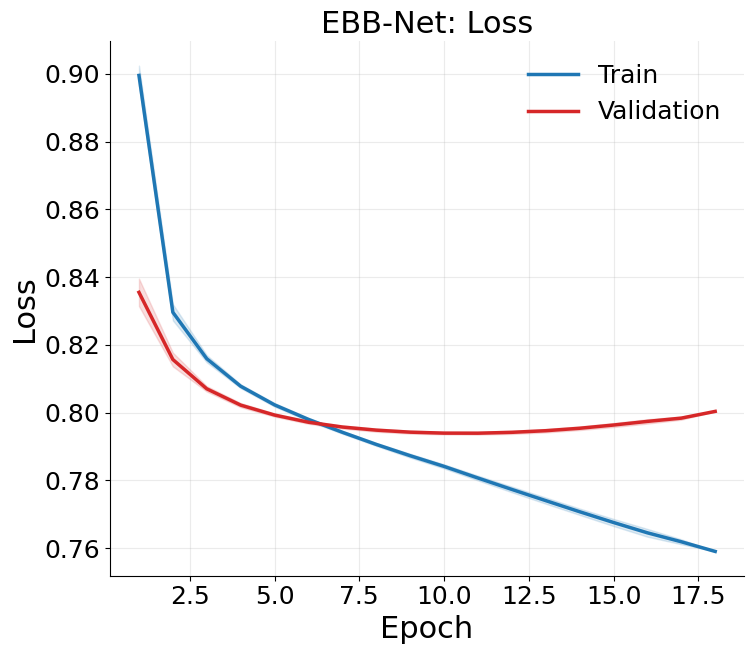

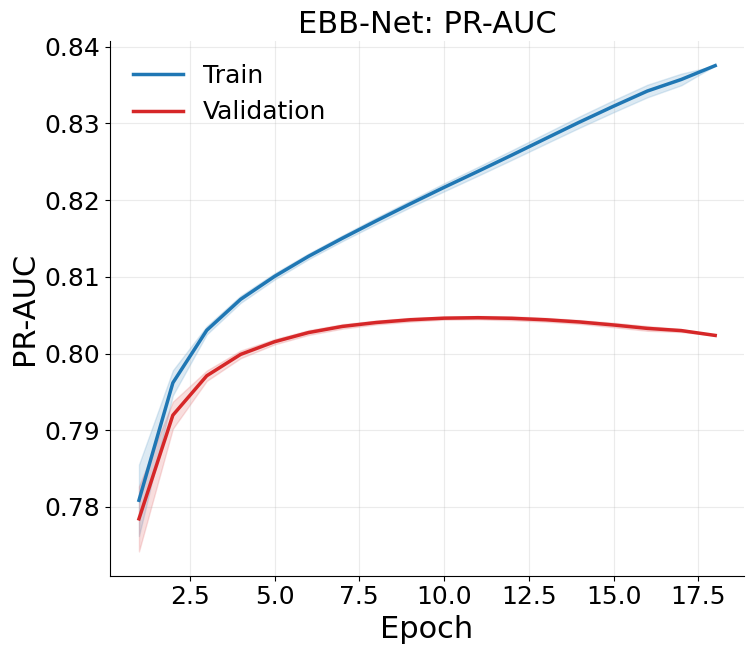

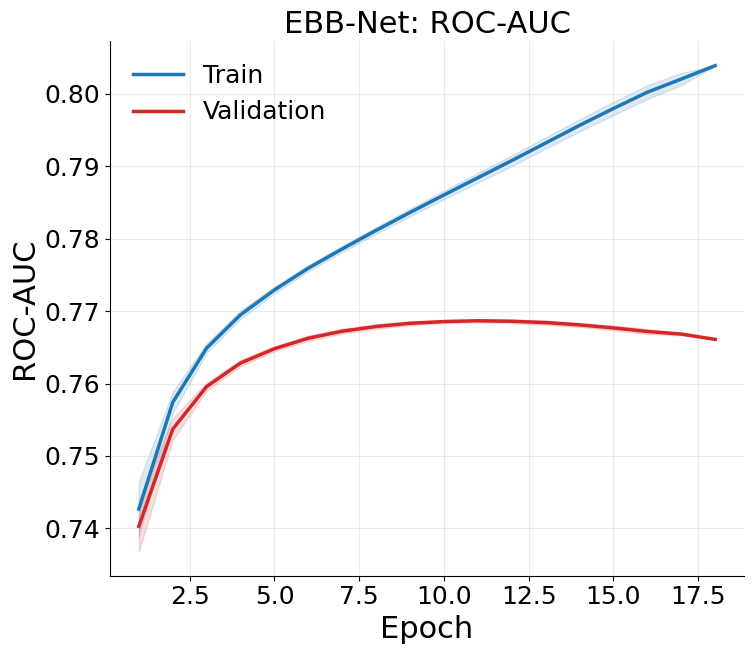

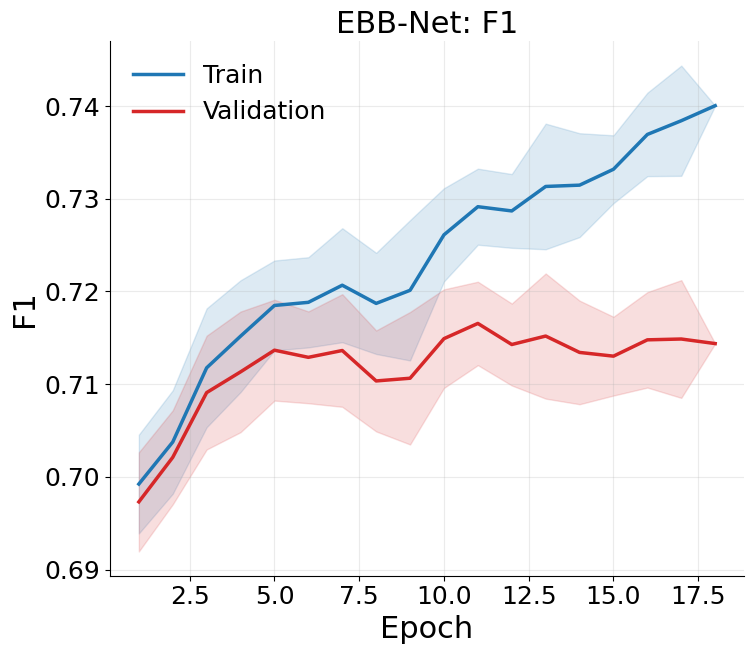

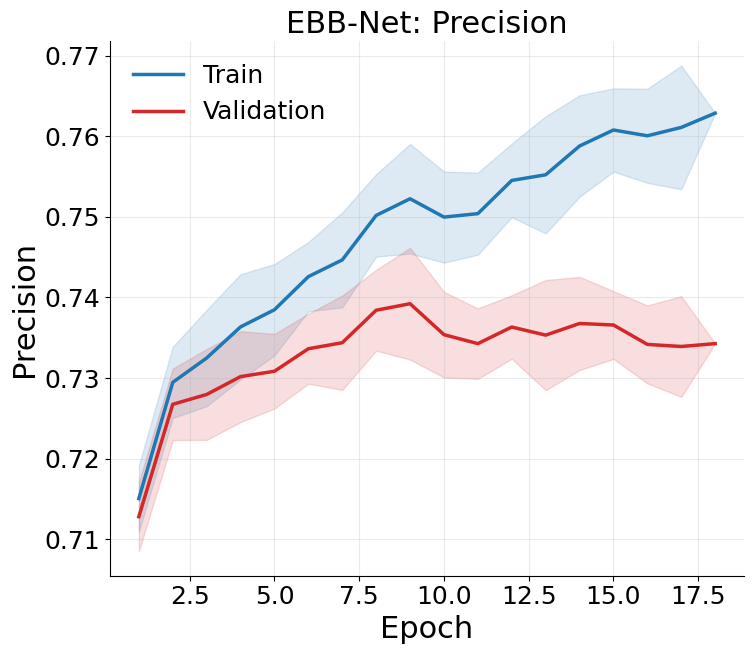

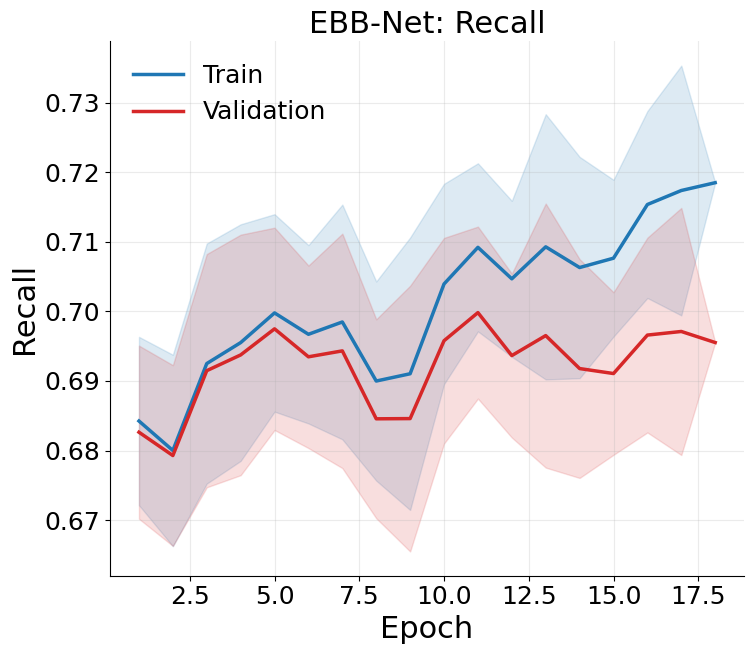

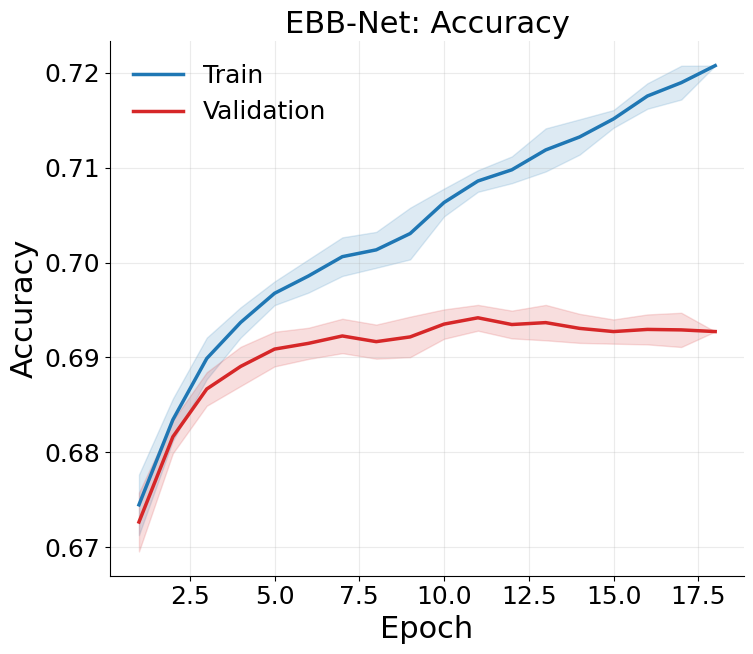

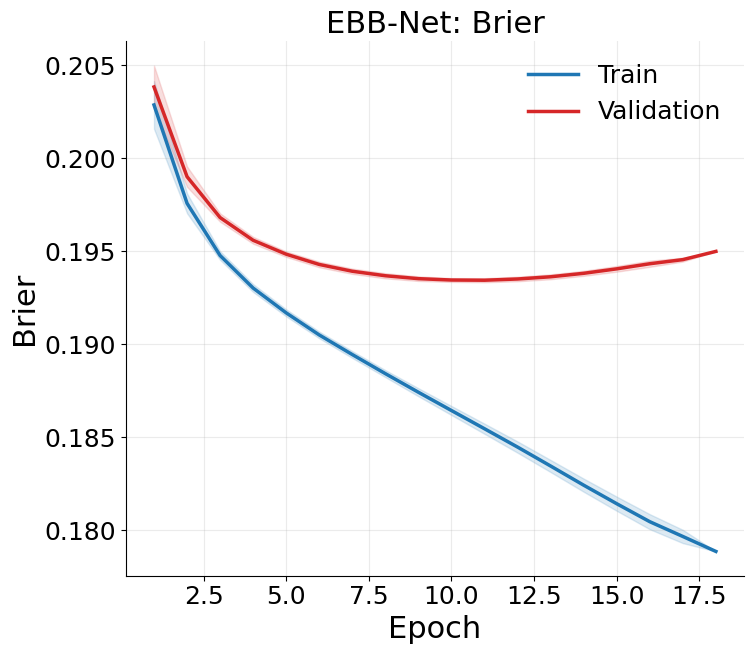

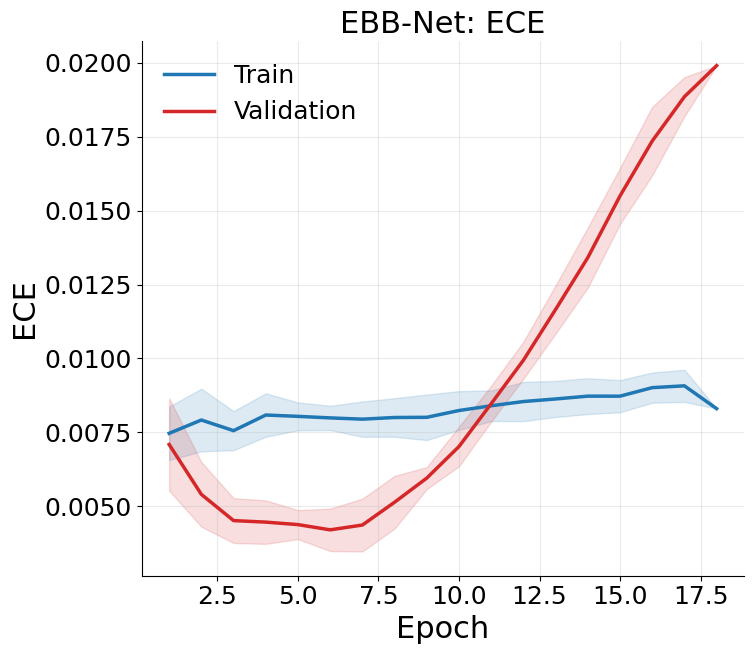

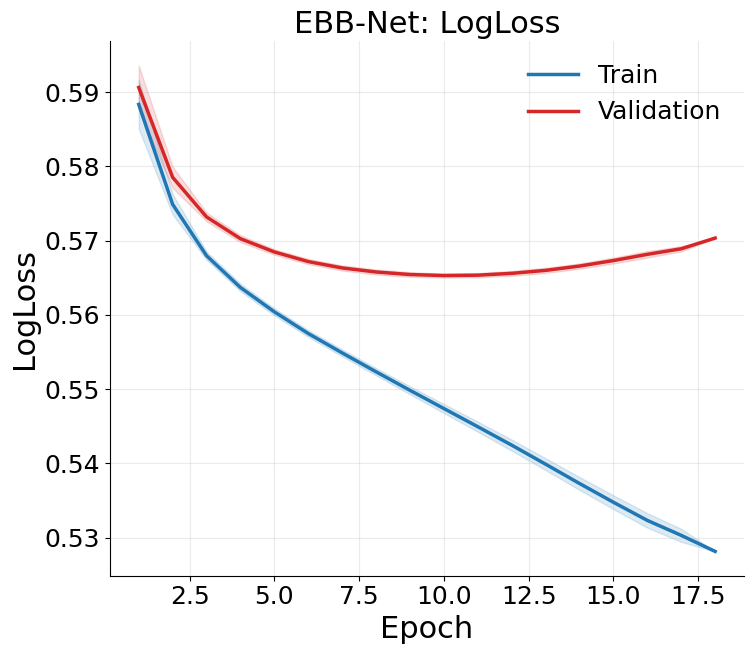

In [42]:
# EBB-Net convergence: training vs validation, one figure per metric
plot_convergence("EBB-Net")

# Ablation Training

In [43]:
# Train and evaluate A1: without group tokens
if "A1_no_group_tokens" in ABLATIONS: run_model("A1_no_group_tokens")

[A1] seed 42: already completed (early_stopping at epoch 20, best epoch 14)
TEST [A1] seed 42: PR-AUC 0.8082 | ROC-AUC 0.7698 | F1 0.7082 | Precision 0.7452 | Recall 0.6747 | Accuracy 0.6910 | Brier 0.1927 | ECE 0.0083 | LogLoss 0.5634
[A1] seed 43: already completed (early_stopping at epoch 20, best epoch 14)
TEST [A1] seed 43: PR-AUC 0.8076 | ROC-AUC 0.7695 | F1 0.7160 | Precision 0.7400 | Recall 0.6936 | Accuracy 0.6943 | Brier 0.1929 | ECE 0.0077 | LogLoss 0.5640
[A1] seed 44: already completed (early_stopping at epoch 20, best epoch 14)
TEST [A1] seed 44: PR-AUC 0.8073 | ROC-AUC 0.7689 | F1 0.7251 | Precision 0.7310 | Recall 0.7192 | Accuracy 0.6969 | Brier 0.1931 | ECE 0.0089 | LogLoss 0.5643
[A1] seed 45: already completed (early_stopping at epoch 19, best epoch 13)
TEST [A1] seed 45: PR-AUC 0.8079 | ROC-AUC 0.7695 | F1 0.7233 | Precision 0.7320 | Recall 0.7148 | Accuracy 0.6960 | Brier 0.1928 | ECE 0.0069 | LogLoss 0.5636
[A1] seed 46: already completed (early_stopping at epoch

In [44]:
# Train and evaluate A2: without context-FiLM
if "A2_no_film" in ABLATIONS: run_model("A2_no_film")

[A2] seed 42: already completed (early_stopping at epoch 17, best epoch 11)
TEST [A2] seed 42: PR-AUC 0.8105 | ROC-AUC 0.7722 | F1 0.7146 | Precision 0.7413 | Recall 0.6897 | Accuracy 0.6938 | Brier 0.1917 | ECE 0.0051 | LogLoss 0.5608
[A2] seed 43: already completed (early_stopping at epoch 17, best epoch 11)
TEST [A2] seed 43: PR-AUC 0.8098 | ROC-AUC 0.7714 | F1 0.7173 | Precision 0.7400 | Recall 0.6959 | Accuracy 0.6952 | Brier 0.1921 | ECE 0.0062 | LogLoss 0.5617
[A2] seed 44: already completed (early_stopping at epoch 17, best epoch 11)
TEST [A2] seed 44: PR-AUC 0.8103 | ROC-AUC 0.7724 | F1 0.7164 | Precision 0.7417 | Recall 0.6928 | Accuracy 0.6952 | Brier 0.1916 | ECE 0.0060 | LogLoss 0.5606
[A2] seed 45: already completed (early_stopping at epoch 17, best epoch 11)
TEST [A2] seed 45: PR-AUC 0.8101 | ROC-AUC 0.7718 | F1 0.7123 | Precision 0.7461 | Recall 0.6814 | Accuracy 0.6941 | Brier 0.1919 | ECE 0.0060 | LogLoss 0.5612
[A2] seed 46: already completed (early_stopping at epoch

In [45]:
# Train and evaluate A3: without temporal TCN
if "A3_no_temporal_tcn" in ABLATIONS: run_model("A3_no_temporal_tcn")

[A3] seed 42: already completed (early_stopping at epoch 25, best epoch 19)
TEST [A3] seed 42: PR-AUC 0.8103 | ROC-AUC 0.7720 | F1 0.7122 | Precision 0.7460 | Recall 0.6813 | Accuracy 0.6940 | Brier 0.1919 | ECE 0.0070 | LogLoss 0.5612
[A3] seed 43: already completed (early_stopping at epoch 25, best epoch 19)
TEST [A3] seed 43: PR-AUC 0.8099 | ROC-AUC 0.7718 | F1 0.7176 | Precision 0.7388 | Recall 0.6976 | Accuracy 0.6949 | Brier 0.1919 | ECE 0.0072 | LogLoss 0.5613
[A3] seed 44: already completed (early_stopping at epoch 21, best epoch 15)
TEST [A3] seed 44: PR-AUC 0.8096 | ROC-AUC 0.7714 | F1 0.7114 | Precision 0.7442 | Recall 0.6814 | Accuracy 0.6928 | Brier 0.1921 | ECE 0.0064 | LogLoss 0.5616
[A3] seed 45: already completed (early_stopping at epoch 23, best epoch 17)
TEST [A3] seed 45: PR-AUC 0.8096 | ROC-AUC 0.7714 | F1 0.7179 | Precision 0.7399 | Recall 0.6972 | Accuracy 0.6955 | Brier 0.1921 | ECE 0.0045 | LogLoss 0.5618
[A3] seed 46: already completed (early_stopping at epoch

In [46]:
# Train and evaluate A4: binary head only
if "A4_binary_only" in ABLATIONS: run_model("A4_binary_only")

[A4] seed 42: already completed (early_stopping at epoch 16, best epoch 10)
TEST [A4] seed 42: PR-AUC 0.8094 | ROC-AUC 0.7716 | F1 0.7156 | Precision 0.7396 | Recall 0.6930 | Accuracy 0.6938 | Brier 0.1920 | ECE 0.0057 | LogLoss 0.5615
[A4] seed 43: already completed (early_stopping at epoch 16, best epoch 10)
TEST [A4] seed 43: PR-AUC 0.8087 | ROC-AUC 0.7707 | F1 0.7180 | Precision 0.7389 | Recall 0.6982 | Accuracy 0.6952 | Brier 0.1923 | ECE 0.0069 | LogLoss 0.5625
[A4] seed 44: already completed (early_stopping at epoch 16, best epoch 10)
TEST [A4] seed 44: PR-AUC 0.8094 | ROC-AUC 0.7712 | F1 0.7249 | Precision 0.7322 | Recall 0.7177 | Accuracy 0.6973 | Brier 0.1921 | ECE 0.0061 | LogLoss 0.5619
[A4] seed 45: already completed (early_stopping at epoch 17, best epoch 11)
TEST [A4] seed 45: PR-AUC 0.8094 | ROC-AUC 0.7711 | F1 0.7195 | Precision 0.7351 | Recall 0.7045 | Accuracy 0.6947 | Brier 0.1922 | ECE 0.0060 | LogLoss 0.5623
[A4] seed 46: already completed (early_stopping at epoch

In [47]:
# Train and evaluate A5: without change-score regression head
if "A5_no_delta_regression" in ABLATIONS: run_model("A5_no_delta_regression")

[A5] seed 42: already completed (early_stopping at epoch 16, best epoch 10)
TEST [A5] seed 42: PR-AUC 0.8105 | ROC-AUC 0.7723 | F1 0.7136 | Precision 0.7431 | Recall 0.6864 | Accuracy 0.6939 | Brier 0.1917 | ECE 0.0057 | LogLoss 0.5606
[A5] seed 43: already completed (early_stopping at epoch 17, best epoch 11)
TEST [A5] seed 43: PR-AUC 0.8105 | ROC-AUC 0.7725 | F1 0.7145 | Precision 0.7461 | Recall 0.6855 | Accuracy 0.6956 | Brier 0.1917 | ECE 0.0056 | LogLoss 0.5609
[A5] seed 44: already completed (early_stopping at epoch 17, best epoch 11)
TEST [A5] seed 44: PR-AUC 0.8107 | ROC-AUC 0.7726 | F1 0.7142 | Precision 0.7433 | Recall 0.6873 | Accuracy 0.6944 | Brier 0.1916 | ECE 0.0066 | LogLoss 0.5606
[A5] seed 45: already completed (early_stopping at epoch 16, best epoch 10)
TEST [A5] seed 45: PR-AUC 0.8099 | ROC-AUC 0.7718 | F1 0.7170 | Precision 0.7412 | Recall 0.6943 | Accuracy 0.6954 | Brier 0.1919 | ECE 0.0044 | LogLoss 0.5614
[A5] seed 46: already completed (early_stopping at epoch

# SOTA Models Training

In [48]:
# Train and evaluate the SOTA model MLP
run_model("MLP")

[MLP] seed 42: already completed (max_epochs at epoch 25, best epoch 25)
TEST [MLP] seed 42: PR-AUC 0.7980 | ROC-AUC 0.7586 | F1 0.7051 | Precision 0.7315 | Recall 0.6805 | Accuracy 0.6837 | Brier 0.1968 | ECE 0.0066 | LogLoss 0.5731
[MLP] seed 43: already completed (max_epochs at epoch 25, best epoch 25)
TEST [MLP] seed 43: PR-AUC 0.7991 | ROC-AUC 0.7600 | F1 0.7100 | Precision 0.7322 | Recall 0.6891 | Accuracy 0.6871 | Brier 0.1963 | ECE 0.0041 | LogLoss 0.5721
[MLP] seed 44: already completed (max_epochs at epoch 25, best epoch 25)
TEST [MLP] seed 44: PR-AUC 0.7978 | ROC-AUC 0.7586 | F1 0.6975 | Precision 0.7394 | Recall 0.6601 | Accuracy 0.6818 | Brier 0.1968 | ECE 0.0050 | LogLoss 0.5733
[MLP] seed 45: already completed (max_epochs at epoch 25, best epoch 25)
TEST [MLP] seed 45: PR-AUC 0.7987 | ROC-AUC 0.7595 | F1 0.7102 | Precision 0.7288 | Recall 0.6926 | Accuracy 0.6860 | Brier 0.1965 | ECE 0.0043 | LogLoss 0.5725
[MLP] seed 46: already completed (max_epochs at epoch 25, best e

In [49]:
# Train and evaluate the SOTA model GRU
run_model("GRU")

[GRU] seed 42: already completed (early_stopping at epoch 18, best epoch 12)
TEST [GRU] seed 42: PR-AUC 0.8051 | ROC-AUC 0.7668 | F1 0.7197 | Precision 0.7327 | Recall 0.7073 | Accuracy 0.6939 | Brier 0.1940 | ECE 0.0106 | LogLoss 0.5667
[GRU] seed 43: already completed (early_stopping at epoch 17, best epoch 11)
TEST [GRU] seed 43: PR-AUC 0.8043 | ROC-AUC 0.7658 | F1 0.7065 | Precision 0.7415 | Recall 0.6747 | Accuracy 0.6885 | Brier 0.1943 | ECE 0.0088 | LogLoss 0.5673
[GRU] seed 44: already completed (early_stopping at epoch 16, best epoch 10)
TEST [GRU] seed 44: PR-AUC 0.8046 | ROC-AUC 0.7659 | F1 0.7100 | Precision 0.7396 | Recall 0.6827 | Accuracy 0.6901 | Brier 0.1942 | ECE 0.0066 | LogLoss 0.5672
[GRU] seed 45: already completed (early_stopping at epoch 16, best epoch 10)
TEST [GRU] seed 45: PR-AUC 0.8035 | ROC-AUC 0.7651 | F1 0.7139 | Precision 0.7333 | Recall 0.6956 | Accuracy 0.6902 | Brier 0.1945 | ECE 0.0061 | LogLoss 0.5681
[GRU] seed 46: already completed (early_stopping

In [50]:
# Train and evaluate the SOTA model TCN
run_model("TCN")

[TCN] seed 42: already completed (early_stopping at epoch 15, best epoch 9)
TEST [TCN] seed 42: PR-AUC 0.8052 | ROC-AUC 0.7667 | F1 0.7108 | Precision 0.7389 | Recall 0.6847 | Accuracy 0.6904 | Brier 0.1939 | ECE 0.0067 | LogLoss 0.5665
[TCN] seed 43: already completed (early_stopping at epoch 15, best epoch 9)
TEST [TCN] seed 43: PR-AUC 0.8050 | ROC-AUC 0.7663 | F1 0.7205 | Precision 0.7313 | Recall 0.7101 | Accuracy 0.6939 | Brier 0.1941 | ECE 0.0063 | LogLoss 0.5667
[TCN] seed 44: already completed (early_stopping at epoch 15, best epoch 9)
TEST [TCN] seed 44: PR-AUC 0.8048 | ROC-AUC 0.7661 | F1 0.7158 | Precision 0.7330 | Recall 0.6993 | Accuracy 0.6913 | Brier 0.1942 | ECE 0.0074 | LogLoss 0.5670
[TCN] seed 45: already completed (early_stopping at epoch 15, best epoch 9)
TEST [TCN] seed 45: PR-AUC 0.8050 | ROC-AUC 0.7665 | F1 0.7202 | Precision 0.7273 | Recall 0.7133 | Accuracy 0.6921 | Brier 0.1940 | ECE 0.0080 | LogLoss 0.5666
[TCN] seed 46: already completed (early_stopping at 

# Non-Sequential Tabular Baselines

In [51]:
# Non-sequential tabular baselines: XGBoost, LightGBM, Random Forest, L2-regularised logistic regression ("ridge" classifier).
# Matched features: the last observed week's dynamic features + the static features -- EXACTLY what the SOTA MLP sees (SotaMLP uses x[:, -1] + static).
# Same enrollment-level train/val/test split, same SEEDS list, same tuning-budget size as the neural SOTA models (TUNE_TRIALS_SOTA trials).
# Writes metrics_{train,val,test}.json into RUN_ROOT/<run_name>/seed_<seed>/ in the same format train_run()/evaluate_run() use,
# so the existing collect() / TABLES / paired-delta-vs-EBB-Net code in the Results section picks these up with no changes.

import subprocess, sys
for _pkg, _imp in [("xgboost", "xgboost"), ("lightgbm", "lightgbm")]:
    try:
        __import__(_imp)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", _pkg], check=False)
import lightgbm as lgb
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

def tabular_xy(split):
    # last-week dynamic features (already train-fitted scaled/imputed by the prep pipeline) + static features
    X = T[split]["X"][:, -1, :].detach().cpu().numpy()
    S = T[split]["S"].detach().cpu().numpy()
    return np.concatenate([X, S], axis=1), DATA[split]["y"].astype(int)

TAB_FEATURE_NAMES = [f"{f} (t)" for f in DYN_FEATURES] + list(STATIC_FEATURES)
Xtr, ytr = tabular_xy("train")
Xv, yv = tabular_xy("val")
Xte, yte = tabular_xy("test")
print(f"tabular baseline matrix: {Xtr.shape[1]} features "
      f"({len(DYN_FEATURES)} last-week dynamic + {len(STATIC_FEATURES)} static) -- matches the SOTA MLP input exactly")

TAB_RUNS = {
    "XGBoost":      dict(label="XGB",   desc="Gradient-boosted trees (XGBoost), matched last-week + static features"),
    "LightGBM":     dict(label="LGBM",  desc="Gradient-boosted trees (LightGBM), matched last-week + static features"),
    "RandomForest": dict(label="RF",    desc="Random forest, matched last-week + static features"),
    "RidgeLogReg":  dict(label="Ridge", desc="L2-regularised logistic regression ('ridge' classifier), matched features"),
}
for _k, _v in TAB_RUNS.items():
    RUNS[_k] = {**_v, "kind": "tabular"}

def fit_predict_xgb(seed, hp):
    m = XGBClassifier(n_estimators=2000, max_depth=hp["max_depth"], learning_rate=hp["lr"],
                       subsample=hp["subsample"], colsample_bytree=hp["colsample"], reg_lambda=hp["reg_lambda"],
                       eval_metric="aucpr", tree_method="hist", random_state=seed, n_jobs=-1, early_stopping_rounds=50)
    m.fit(Xtr, ytr, eval_set=[(Xv, yv)], verbose=False)
    return m, m.predict_proba(Xtr)[:, 1], m.predict_proba(Xv)[:, 1], m.predict_proba(Xte)[:, 1]

def fit_predict_lgbm(seed, hp):
    m = LGBMClassifier(n_estimators=2000, max_depth=hp["max_depth"], learning_rate=hp["lr"],
                        subsample=hp["subsample"], colsample_bytree=hp["colsample"], reg_lambda=hp["reg_lambda"],
                        random_state=seed, n_jobs=-1, verbosity=-1)
    m.fit(Xtr, ytr, eval_set=[(Xv, yv)], eval_metric="average_precision",
          callbacks=[lgb.early_stopping(50, verbose=False)])
    return m, m.predict_proba(Xtr)[:, 1], m.predict_proba(Xv)[:, 1], m.predict_proba(Xte)[:, 1]

def fit_predict_rf(seed, hp):
    m = RandomForestClassifier(n_estimators=hp["n_estimators"], max_depth=hp["max_depth"],
                                min_samples_leaf=hp["min_samples_leaf"], n_jobs=-1, random_state=seed)
    m.fit(Xtr, ytr)
    return m, m.predict_proba(Xtr)[:, 1], m.predict_proba(Xv)[:, 1], m.predict_proba(Xte)[:, 1]

def fit_predict_ridge(seed, hp):
    m = LogisticRegression(penalty="l2", C=hp["C"], max_iter=5000, random_state=seed)
    m.fit(Xtr, ytr)
    return m, m.predict_proba(Xtr)[:, 1], m.predict_proba(Xv)[:, 1], m.predict_proba(Xte)[:, 1]

TAB_SPACE = {
    "XGBoost":      dict(fn=fit_predict_xgb,   space=dict(max_depth=[3, 4, 5, 6, 8], lr=[0.01, 0.02, 0.05, 0.08],
                          subsample=[0.6, 0.8, 1.0], colsample=[0.6, 0.8, 1.0], reg_lambda=[0.1, 1.0, 5.0])),
    "LightGBM":     dict(fn=fit_predict_lgbm,  space=dict(max_depth=[-1, 4, 6, 8], lr=[0.01, 0.02, 0.05, 0.08],
                          subsample=[0.6, 0.8, 1.0], colsample=[0.6, 0.8, 1.0], reg_lambda=[0.1, 1.0, 5.0])),
    "RandomForest": dict(fn=fit_predict_rf,    space=dict(n_estimators=[300, 500, 800], max_depth=[None, 10, 20, 30],
                          min_samples_leaf=[1, 2, 5])),
    "RidgeLogReg":  dict(fn=fit_predict_ridge, space=dict(C=[0.01, 0.03, 0.1, 0.3, 1.0, 3.0])),
}

def sample_tab_hp(rng, space):
    return {k: v[rng.randint(len(v))] for k, v in space.items()}

rng_tab = np.random.RandomState(TUNE_SEED)
TAB_BEST_HP = {}
for name, spec in TAB_SPACE.items():
    best_score, best_hp = -np.inf, None
    for _ in range(TUNE_TRIALS_SOTA):          # identical, stated tuning budget to the neural SOTA baselines
        hp = sample_tab_hp(rng_tab, spec["space"])
        _, _, pv, _ = spec["fn"](TUNE_SEED, hp)
        score = average_precision_score(yv, pv)
        if score > best_score:
            best_score, best_hp = score, hp
    TAB_BEST_HP[name] = best_hp
    print(f"[{TAB_RUNS[name]['label']}] tuned on {TUNE_TRIALS_SOTA} trials -> val PR-AUC {best_score:.4f} | hp {best_hp}")

TAB_TRAIN_TIME_LOG = []
for name, spec in TAB_SPACE.items():
    run_dir_base = RUN_ROOT / name
    for seed in SEEDS:
        run_dir = run_dir_base / f"seed_{seed}"; run_dir.mkdir(parents=True, exist_ok=True)
        if all((run_dir / f"metrics_{s}.json").exists() for s in ["train", "val", "test"]):
            print(f"[{TAB_RUNS[name]['label']}] seed {seed}: already completed"); continue
        t0 = time.time()
        model, ptr, pv, pte = spec["fn"](seed, TAB_BEST_HP[name])
        train_seconds = time.time() - t0
        # inference timing: batched full test pass + single-row latency, for the training/inference-time table
        t_full0 = time.time(); _ = model.predict_proba(Xte); t_full = time.time() - t_full0
        n_single = min(500, len(yte))
        t_s0 = time.time()
        for i in range(n_single):
            _ = model.predict_proba(Xte[i:i + 1])
        t_single = time.time() - t_s0
        thr = find_threshold(yv, pv)
        for split, y_, p_ in [("train", ytr, ptr), ("val", yv, pv), ("test", yte, pte)]:
            m = binary_metrics(y_, p_, thr)
            m["threshold"] = thr
            m["loss"] = float(log_loss(y_, np.clip(p_, 1e-7, 1 - 1e-7), labels=[0, 1]))
            save_json(m, run_dir / f"metrics_{split}.json")
        np.savez_compressed(run_dir / "preds_test.npz", p=pte, y=yte)
        TAB_TRAIN_TIME_LOG.append({
            "run": name, "seed": seed, "train_seconds": train_seconds, "n_train_rows": len(ytr),
            "full_test_pass_seconds": t_full, "rows_per_second_batched": len(yte) / max(t_full, 1e-9),
            "single_sample_ms_mean": 1000 * t_single / n_single, "n_single_samples": n_single,
        })
        print(f"[{TAB_RUNS[name]['label']}] seed {seed}: train {train_seconds:.1f}s | "
              f"test PR-AUC {binary_metrics(yte, pte, thr)['pr_auc']:.4f}")

if TAB_TRAIN_TIME_LOG:
    pd.DataFrame(TAB_TRAIN_TIME_LOG).to_csv(RUN_ROOT / "tabular_baselines_train_time.csv", index=False)
push(RUN_ROOT)


tabular baseline matrix: 116 features (82 last-week dynamic + 34 static) -- matches the SOTA MLP input exactly
[XGB] tuned on 5 trials -> val PR-AUC 0.8007 | hp {'max_depth': 6, 'lr': 0.05, 'subsample': 0.6, 'colsample': 0.6, 'reg_lambda': 5.0}
[LGBM] tuned on 5 trials -> val PR-AUC 0.8009 | hp {'max_depth': 8, 'lr': 0.05, 'subsample': 0.6, 'colsample': 0.8, 'reg_lambda': 5.0}
[RF] tuned on 5 trials -> val PR-AUC 0.7900 | hp {'n_estimators': 500, 'max_depth': None, 'min_samples_leaf': 2}
[Ridge] tuned on 5 trials -> val PR-AUC 0.7453 | hp {'C': 1.0}
[XGB] seed 42: train 155.4s | test PR-AUC 0.8057
[XGB] seed 43: train 120.9s | test PR-AUC 0.8054
[XGB] seed 44: train 167.3s | test PR-AUC 0.8060
[XGB] seed 45: train 127.9s | test PR-AUC 0.8056
[XGB] seed 46: train 154.1s | test PR-AUC 0.8058
[XGB] seed 47: train 151.1s | test PR-AUC 0.8061
[XGB] seed 48: train 146.3s | test PR-AUC 0.8056
[XGB] seed 49: train 151.2s | test PR-AUC 0.8059
[XGB] seed 50: train 143.8s | test PR-AUC 0.8056
[XG

# Results

In [52]:
# Result tables (mean ± sd over seeds) for train, validation and test, and paired differences to EBB-Net
def collect():
    rows = []
    for run_name in RUNS:
        for sd in sorted((RUN_ROOT / run_name).glob("seed_*")):
            if all((sd / f"metrics_{s}.json").exists() for s in ["train", "val", "test"]):
                for s in ["train", "val", "test"]:
                    d = json.load(open(sd / f"metrics_{s}.json")); d.update(run=run_name, model=RUNS[run_name]["label"], seed=int(sd.name.split("_")[1]), split=s); rows.append(d)
    return pd.DataFrame(rows)
def pm(x, nd=4): x = np.asarray(x, float); return f"{x.mean():.{nd}f} ± {(x.std(ddof=1) if len(x) > 1 else 0.0):.{nd}f}"

ALL = collect(); assert len(ALL), "no finished runs found"
ORDER = [r for r in RUNS if r in ALL["run"].unique()]
display(pd.DataFrame([{"Label": RUNS[r]["label"], "Description": RUNS[r]["desc"]} for r in ORDER]).set_index("Label"))
TABLES = {}
for split in ["train", "val", "test"]:
    TABLES[split] = pd.DataFrame([{"Model": RUNS[r]["label"], "Seeds": len(ALL[(ALL.run == r) & (ALL.split == split)]),
                                   **{NICE[k]: pm(ALL[(ALL.run == r) & (ALL.split == split)][k]) for k in METRICS}} for r in ORDER]).set_index("Model")
    print(f"\n{split.upper()} (mean ± sd over seeds)"); display(TABLES[split]); TABLES[split].to_csv(RUN_ROOT / f"table_{split}_mean_sd.csv")
ALL.to_csv(RUN_ROOT / "all_seed_metrics_long.csv", index=False)
with open(RUN_ROOT / "results_tables.md", "w") as f:
    for split, t in TABLES.items(): f.write(f"### {split.upper()}\n\n{t.to_markdown()}\n\n")
if PROPOSED in ORDER:
    base = ALL[(ALL.run == PROPOSED) & (ALL.split == "test")].set_index("seed"); rows = []
    for r in ORDER:
        if r == PROPOSED: continue
        g = ALL[(ALL.run == r) & (ALL.split == "test")].set_index("seed"); common = base.index.intersection(g.index)
        if len(common) == 0: continue
        row = {"Model": RUNS[r]["label"], "paired seeds": len(common)}
        for k in ["pr_auc", "roc_auc", "logloss", "brier"]: row[f"Δ{NICE[k]}"] = pm((g.loc[common, k] - base.loc[common, k]).to_numpy(), 4)
        row["EBB-Net better (PR-AUC)"] = f"{int((base.loc[common, 'pr_auc'] > g.loc[common, 'pr_auc']).sum())}/{len(common)} seeds"; rows.append(row)
    ABL = pd.DataFrame(rows).set_index("Model"); print("\nPaired difference to EBB-Net, seed by seed (TEST): model minus EBB-Net"); display(ABL); ABL.to_csv(RUN_ROOT / "table_paired_delta_vs_EBB-Net.csv")
push(RUN_ROOT)

,Description
Label,
EBB-Net,Proposed model
A1,w/o group tokens (single MLP over all weekly f...
A2,w/o context-FiLM
A3,w/o temporal TCN (weeks processed independently)
A4,binary head only (no ordinal or regression head)
A5,w/o change-score regression head
MLP,MLP on last-week features and static context
GRU,GRU over the 6-week sequence
TCN,Causal TCN over the 6-week sequence



TRAIN (mean ± sd over seeds)


,Seeds,PR-AUC,ROC-AUC,F1,Precision,Recall,Accuracy,Brier,ECE,LogLoss
Model,,,,,,,,,,
EBB-Net,10,0.8241 ± 0.0014,0.7873 ± 0.0015,0.7280 ± 0.0034,0.7519 ± 0.0042,0.7057 ± 0.0098,0.7072 ± 0.0013,0.1858 ± 0.0006,0.0074 ± 0.0003,0.5457 ± 0.0016
A1,10,0.8231 ± 0.0018,0.7862 ± 0.0020,0.7284 ± 0.0060,0.7501 ± 0.0077,0.7082 ± 0.0175,0.7068 ± 0.0021,0.1863 ± 0.0008,0.0081 ± 0.0005,0.5468 ± 0.0020
A2,10,0.8235 ± 0.0005,0.7867 ± 0.0007,0.7250 ± 0.0030,0.7544 ± 0.0035,0.6980 ± 0.0084,0.7061 ± 0.0010,0.1860 ± 0.0003,0.0076 ± 0.0004,0.5463 ± 0.0007
A3,10,0.8210 ± 0.0013,0.7839 ± 0.0014,0.7232 ± 0.0039,0.7525 ± 0.0041,0.6962 ± 0.0104,0.7041 ± 0.0018,0.1871 ± 0.0006,0.0053 ± 0.0003,0.5491 ± 0.0014
A4,10,0.8238 ± 0.0010,0.7869 ± 0.0011,0.7284 ± 0.0045,0.7507 ± 0.0048,0.7076 ± 0.0125,0.7071 ± 0.0017,0.1859 ± 0.0005,0.0074 ± 0.0005,0.5460 ± 0.0012
A5,10,0.8239 ± 0.0015,0.7871 ± 0.0016,0.7247 ± 0.0071,0.7546 ± 0.0067,0.6975 ± 0.0189,0.7060 ± 0.0027,0.1859 ± 0.0007,0.0075 ± 0.0003,0.5458 ± 0.0017
MLP,10,0.8085 ± 0.0005,0.7699 ± 0.0005,0.7121 ± 0.0063,0.7423 ± 0.0054,0.6845 ± 0.0161,0.6928 ± 0.0022,0.1927 ± 0.0002,0.0065 ± 0.0002,0.5630 ± 0.0005
GRU,10,0.8191 ± 0.0012,0.7816 ± 0.0014,0.7213 ± 0.0048,0.7510 ± 0.0043,0.6940 ± 0.0124,0.7023 ± 0.0021,0.1882 ± 0.0006,0.0064 ± 0.0002,0.5517 ± 0.0014
TCN,10,0.8198 ± 0.0011,0.7826 ± 0.0013,0.7275 ± 0.0055,0.7467 ± 0.0053,0.7095 ± 0.0148,0.7050 ± 0.0021,0.1878 ± 0.0005,0.0070 ± 0.0003,0.5508 ± 0.0013



VAL (mean ± sd over seeds)


,Seeds,PR-AUC,ROC-AUC,F1,Precision,Recall,Accuracy,Brier,ECE,LogLoss
Model,,,,,,,,,,
EBB-Net,10,0.8047 ± 0.0002,0.7687 ± 0.0002,0.7157 ± 0.0037,0.7351 ± 0.0036,0.6974 ± 0.0102,0.6939 ± 0.0012,0.1934 ± 0.0001,0.0082 ± 0.0011,0.5653 ± 0.0003
A1,10,0.8021 ± 0.0002,0.7659 ± 0.0002,0.7146 ± 0.0066,0.7321 ± 0.0064,0.6983 ± 0.0182,0.6920 ± 0.0019,0.1945 ± 0.0001,0.0091 ± 0.0011,0.5680 ± 0.0003
A2,10,0.8042 ± 0.0003,0.7681 ± 0.0003,0.7124 ± 0.0032,0.7372 ± 0.0027,0.6892 ± 0.0083,0.6925 ± 0.0012,0.1937 ± 0.0001,0.0080 ± 0.0008,0.5658 ± 0.0003
A3,10,0.8037 ± 0.0006,0.7674 ± 0.0007,0.7116 ± 0.0037,0.7368 ± 0.0038,0.6882 ± 0.0100,0.6919 ± 0.0014,0.1939 ± 0.0002,0.0090 ± 0.0010,0.5664 ± 0.0005
A4,10,0.8033 ± 0.0005,0.7673 ± 0.0004,0.7150 ± 0.0045,0.7332 ± 0.0041,0.6979 ± 0.0123,0.6927 ± 0.0014,0.1940 ± 0.0001,0.0090 ± 0.0009,0.5667 ± 0.0004
A5,10,0.8046 ± 0.0002,0.7685 ± 0.0002,0.7123 ± 0.0068,0.7377 ± 0.0066,0.6890 ± 0.0185,0.6927 ± 0.0020,0.1935 ± 0.0001,0.0081 ± 0.0012,0.5654 ± 0.0004
MLP,10,0.7938 ± 0.0007,0.7563 ± 0.0007,0.7027 ± 0.0062,0.7287 ± 0.0054,0.6787 ± 0.0160,0.6828 ± 0.0019,0.1981 ± 0.0002,0.0066 ± 0.0006,0.5764 ± 0.0006
GRU,10,0.7985 ± 0.0004,0.7623 ± 0.0005,0.7081 ± 0.0043,0.7328 ± 0.0041,0.6851 ± 0.0118,0.6880 ± 0.0013,0.1959 ± 0.0002,0.0098 ± 0.0012,0.5715 ± 0.0005
TCN,10,0.7992 ± 0.0004,0.7629 ± 0.0003,0.7135 ± 0.0054,0.7286 ± 0.0049,0.6992 ± 0.0147,0.6898 ± 0.0016,0.1956 ± 0.0001,0.0092 ± 0.0007,0.5707 ± 0.0003



TEST (mean ± sd over seeds)


,Seeds,PR-AUC,ROC-AUC,F1,Precision,Recall,Accuracy,Brier,ECE,LogLoss
Model,,,,,,,,,,
EBB-Net,10,0.8105 ± 0.0005,0.7725 ± 0.0004,0.7181 ± 0.0036,0.7409 ± 0.0033,0.6969 ± 0.0096,0.6961 ± 0.0015,0.1916 ± 0.0002,0.0063 ± 0.0012,0.5607 ± 0.0004
A1,10,0.8076 ± 0.0004,0.7694 ± 0.0003,0.7176 ± 0.0071,0.7377 ± 0.0064,0.6989 ± 0.0189,0.6944 ± 0.0024,0.1929 ± 0.0001,0.0073 ± 0.0012,0.5637 ± 0.0003
A2,10,0.8100 ± 0.0004,0.7718 ± 0.0004,0.7150 ± 0.0031,0.7427 ± 0.0031,0.6893 ± 0.0083,0.6946 ± 0.0010,0.1919 ± 0.0002,0.0061 ± 0.0007,0.5613 ± 0.0005
A3,10,0.8099 ± 0.0004,0.7717 ± 0.0004,0.7148 ± 0.0034,0.7425 ± 0.0040,0.6891 ± 0.0096,0.6944 ± 0.0011,0.1920 ± 0.0002,0.0065 ± 0.0011,0.5614 ± 0.0004
A4,10,0.8091 ± 0.0006,0.7711 ± 0.0004,0.7176 ± 0.0047,0.7388 ± 0.0041,0.6978 ± 0.0124,0.6949 ± 0.0018,0.1922 ± 0.0002,0.0067 ± 0.0008,0.5622 ± 0.0005
A5,10,0.8104 ± 0.0004,0.7724 ± 0.0004,0.7148 ± 0.0069,0.7435 ± 0.0067,0.6886 ± 0.0186,0.6948 ± 0.0022,0.1917 ± 0.0002,0.0061 ± 0.0014,0.5608 ± 0.0004
MLP,10,0.7983 ± 0.0005,0.7591 ± 0.0005,0.7054 ± 0.0060,0.7330 ± 0.0052,0.6800 ± 0.0154,0.6844 ± 0.0020,0.1966 ± 0.0002,0.0051 ± 0.0008,0.5729 ± 0.0005
GRU,10,0.8046 ± 0.0005,0.7661 ± 0.0006,0.7113 ± 0.0044,0.7383 ± 0.0041,0.6864 ± 0.0116,0.6905 ± 0.0016,0.1942 ± 0.0002,0.0077 ± 0.0014,0.5671 ± 0.0006
TCN,10,0.8048 ± 0.0004,0.7662 ± 0.0004,0.7157 ± 0.0054,0.7331 ± 0.0052,0.6994 ± 0.0149,0.6914 ± 0.0017,0.1941 ± 0.0002,0.0078 ± 0.0011,0.5669 ± 0.0004



Paired difference to EBB-Net, seed by seed (TEST): model minus EBB-Net


,paired seeds,ΔPR-AUC,ΔROC-AUC,ΔLogLoss,ΔBrier,EBB-Net better (PR-AUC)
Model,,,,,,
A1,10,-0.0028 ± 0.0004,-0.0031 ± 0.0004,0.0030 ± 0.0004,0.0012 ± 0.0002,10/10 seeds
A2,10,-0.0005 ± 0.0005,-0.0008 ± 0.0005,0.0006 ± 0.0005,0.0003 ± 0.0002,10/10 seeds
A3,10,-0.0006 ± 0.0005,-0.0009 ± 0.0004,0.0007 ± 0.0004,0.0003 ± 0.0001,9/10 seeds
A4,10,-0.0013 ± 0.0004,-0.0014 ± 0.0004,0.0014 ± 0.0003,0.0006 ± 0.0001,10/10 seeds
A5,10,-0.0001 ± 0.0002,-0.0001 ± 0.0002,0.0001 ± 0.0001,0.0000 ± 0.0001,8/10 seeds
MLP,10,-0.0122 ± 0.0007,-0.0135 ± 0.0007,0.0121 ± 0.0007,0.0050 ± 0.0003,10/10 seeds
GRU,10,-0.0059 ± 0.0005,-0.0064 ± 0.0005,0.0064 ± 0.0005,0.0025 ± 0.0002,10/10 seeds
TCN,10,-0.0056 ± 0.0006,-0.0063 ± 0.0007,0.0061 ± 0.0007,0.0025 ± 0.0003,10/10 seeds
XGB,10,-0.0047 ± 0.0005,-0.0064 ± 0.0004,0.0061 ± 0.0004,0.0025 ± 0.0002,10/10 seeds


# Statistical Significance (Wilcoxon, paired by seed)

In [53]:
# Statistical significance: paired Wilcoxon signed-rank test (pairing unit = seed) between EBB-Net and every other
# model on the TEST split, for each reported metric, with an exact n, a numeric effect size (matched-pairs rank-biserial
# correlation) and Holm-Bonferroni correction across every (model, metric) comparison performed in this table.
# Uses ALL (built by collect() in the Results section) -- run this cell after that one.

from scipy.stats import wilcoxon

SIG_METRICS = ["pr_auc", "roc_auc", "f1", "logloss", "brier"]

def wilcoxon_paired(a, b):
    # a, b: arrays of the SAME metric for the two models, one value per matched seed (same order)
    diff = np.asarray(a, float) - np.asarray(b, float)
    diff_nz = diff[diff != 0]
    n_nz = len(diff_nz)
    if n_nz < 1:
        return dict(n=len(diff), n_nonzero=0, statistic=np.nan, p_raw=np.nan, rank_biserial_r=np.nan)
    stat, p = wilcoxon(diff_nz, alternative="two-sided", zero_method="wilcox",
                        mode="exact" if n_nz <= 25 else "approx")
    ranks = pd.Series(np.abs(diff_nz)).rank().to_numpy()
    r_plus = ranks[diff_nz > 0].sum()
    r_minus = ranks[diff_nz < 0].sum()
    rb = (r_plus - r_minus) / (n_nz * (n_nz + 1) / 2)  # matched-pairs rank-biserial correlation, in [-1, 1]
    return dict(n=len(diff), n_nonzero=n_nz, statistic=float(stat), p_raw=float(p), rank_biserial_r=float(rb))

def holm_bonferroni(pvals):
    pvals = np.asarray(pvals, float)
    order = np.argsort(pvals)
    m = len(pvals)
    adj = np.empty(m)
    running_max = 0.0
    for rank, i in enumerate(order):
        val = max((m - rank) * pvals[i], running_max)
        val = min(val, 1.0)
        adj[i] = val
        running_max = val
    return adj

assert "ALL" in dir(), "run the Results section's collect() cell first (it builds ALL)"
base_test = ALL[(ALL.run == PROPOSED) & (ALL.split == "test")].set_index("seed")
rows = []
for run_name in RUNS:
    if run_name == PROPOSED:
        continue
    g = ALL[(ALL.run == run_name) & (ALL.split == "test")].set_index("seed")
    common = base_test.index.intersection(g.index)
    if len(common) < 2:
        continue
    for metric in SIG_METRICS:
        a, b = base_test.loc[common, metric].to_numpy(), g.loc[common, metric].to_numpy()
        res = wilcoxon_paired(a, b)
        rows.append({"Model": RUNS[run_name]["label"], "Metric": NICE[metric], "paired_seeds": res["n"],
                     "n_nonzero_diffs": res["n_nonzero"], "statistic": res["statistic"], "p_raw": res["p_raw"],
                     "rank_biserial_r": res["rank_biserial_r"],
                     "EBB-Net_better": int((a > b).sum()) if metric not in LOWER_BETTER else int((a < b).sum())})

SIG = pd.DataFrame(rows)
if len(SIG):
    SIG["p_holm"] = holm_bonferroni(SIG["p_raw"].to_numpy())  # corrected jointly across every (model, metric) test above
    SIG = SIG.sort_values(["Model", "Metric"]).reset_index(drop=True)
    display(SIG.round(4))
    SIG.to_csv(RUN_ROOT / "table_significance_wilcoxon.csv", index=False)
    print(f"\npairing unit: seed | n models x metrics tested: {len(SIG)} | correction: Holm-Bonferroni across all tests above")
else:
    print("Not enough paired seeds (need >= 2 common seeds per model) to run the significance table.")
push(RUN_ROOT)


,Model,Metric,paired_seeds,n_nonzero_diffs,statistic,p_raw,rank_biserial_r,EBB-Net_better,p_holm
0,A1,Brier,10,10,0.0,0.0020,-1.0000,10,0.1172
1,A1,F1,10,10,25.0,0.8457,0.0909,5,1.0000
2,A1,LogLoss,10,10,0.0,0.0020,-1.0000,10,0.1172
3,A1,PR-AUC,10,10,0.0,0.0020,1.0000,10,0.1172
4,A1,ROC-AUC,10,10,0.0,0.0020,1.0000,10,0.1172
5,A2,Brier,10,10,0.0,0.0020,-1.0000,10,0.1172
6,A2,F1,10,10,3.0,0.0098,0.8909,8,0.1172
7,A2,LogLoss,10,10,1.0,0.0039,-0.9636,9,0.1172
8,A2,PR-AUC,10,10,0.0,0.0020,1.0000,10,0.1172
9,A2,ROC-AUC,10,10,0.0,0.0020,1.0000,10,0.1172



pairing unit: seed | n models x metrics tested: 60 | correction: Holm-Bonferroni across all tests above


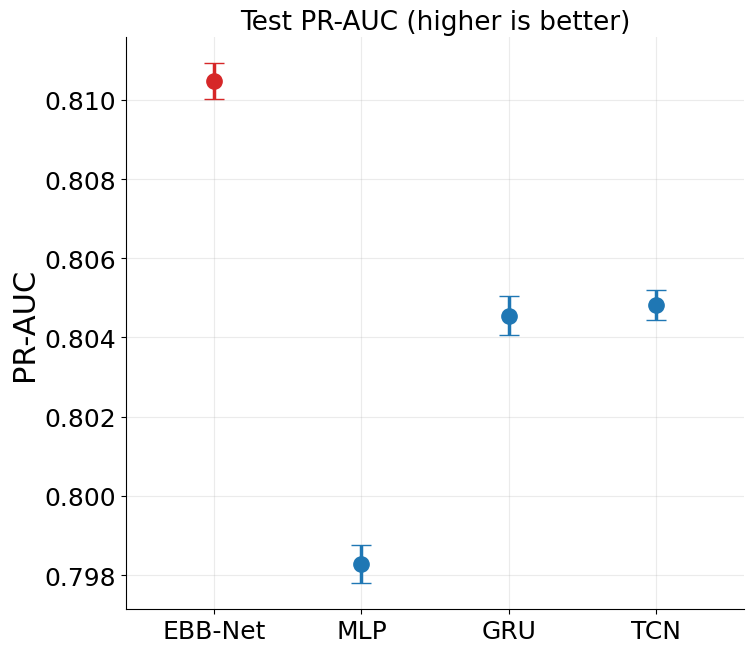

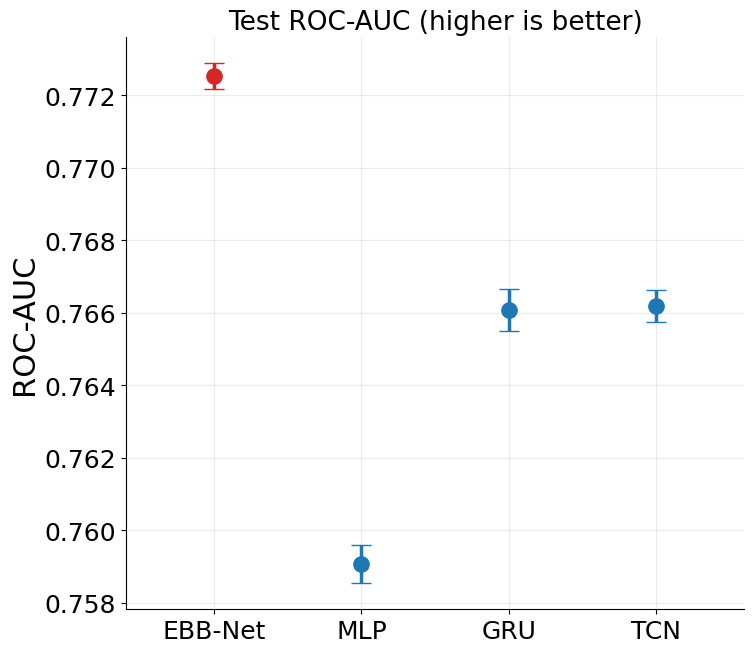

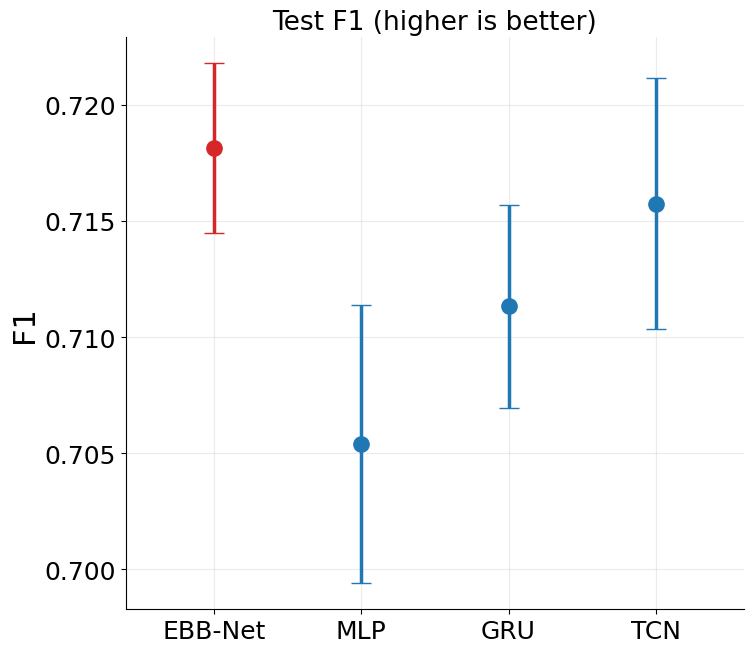

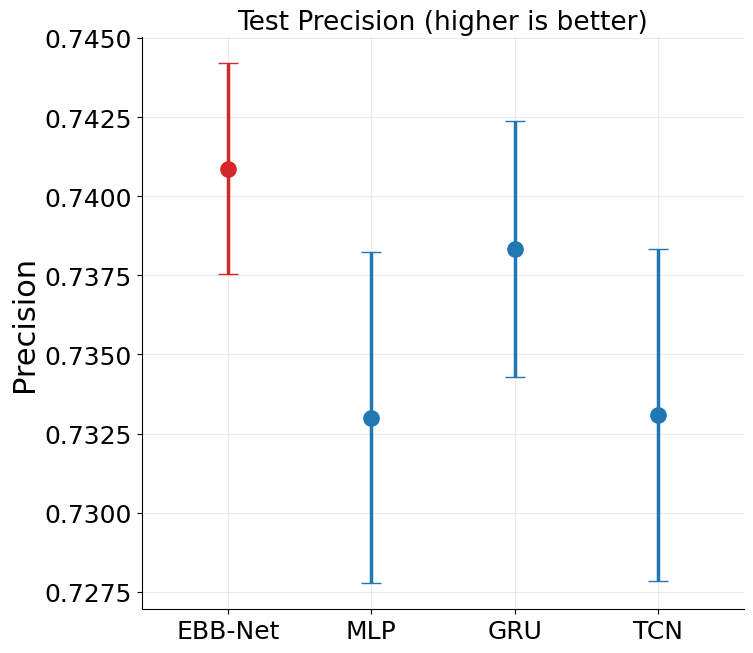

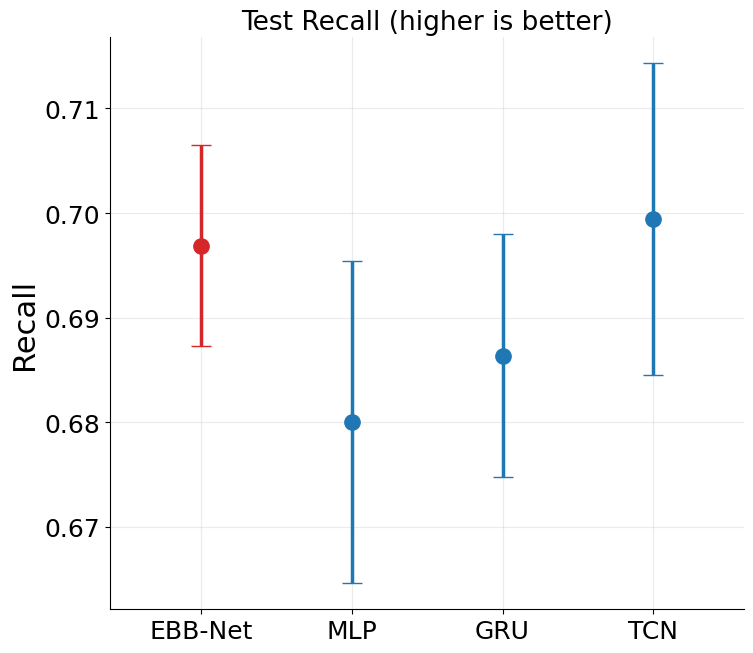

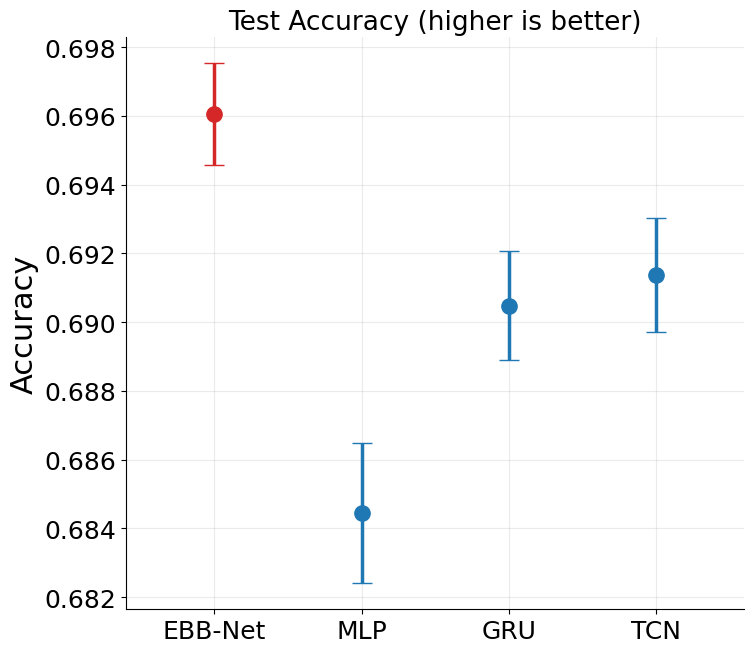

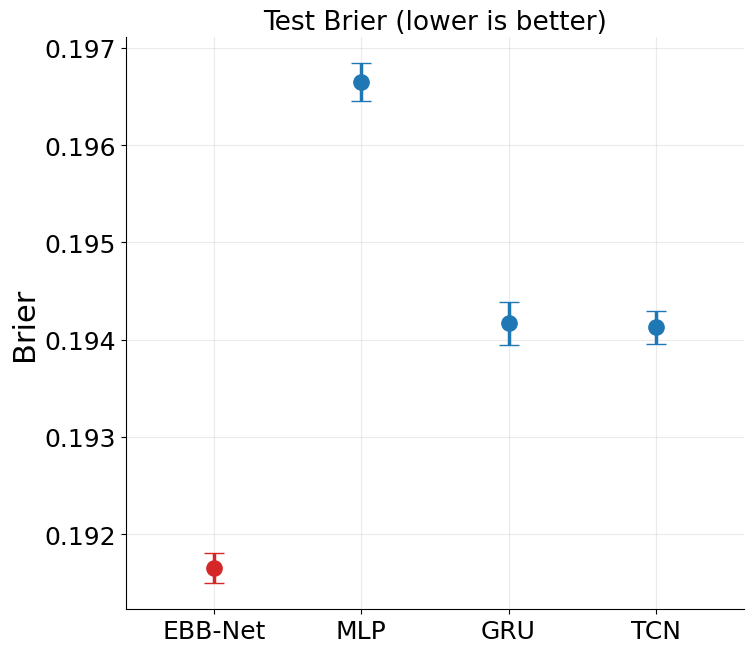

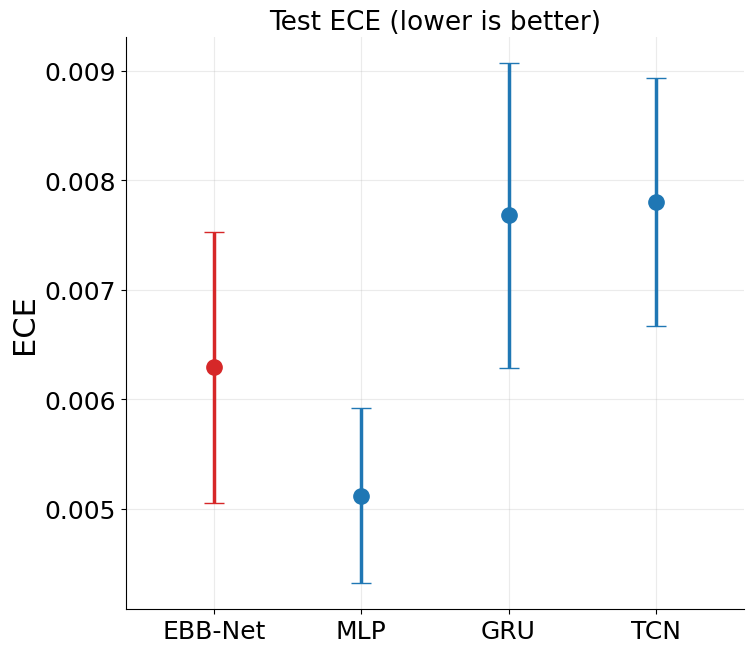

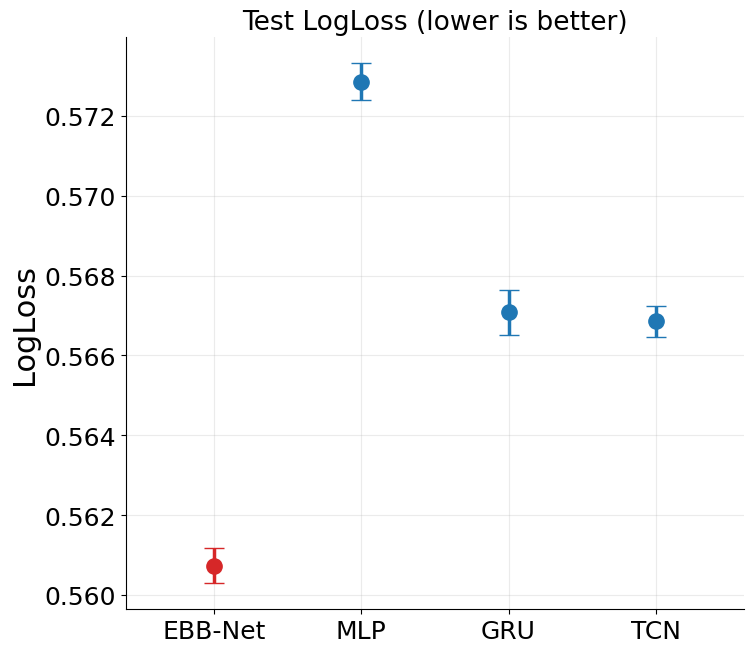

In [54]:
# Test comparison: EBB-Net vs SOTA models, one figure per metric
plot_compare([PROPOSED] + [r for r in SOTA if r in ORDER], "sota_vs_proposed")

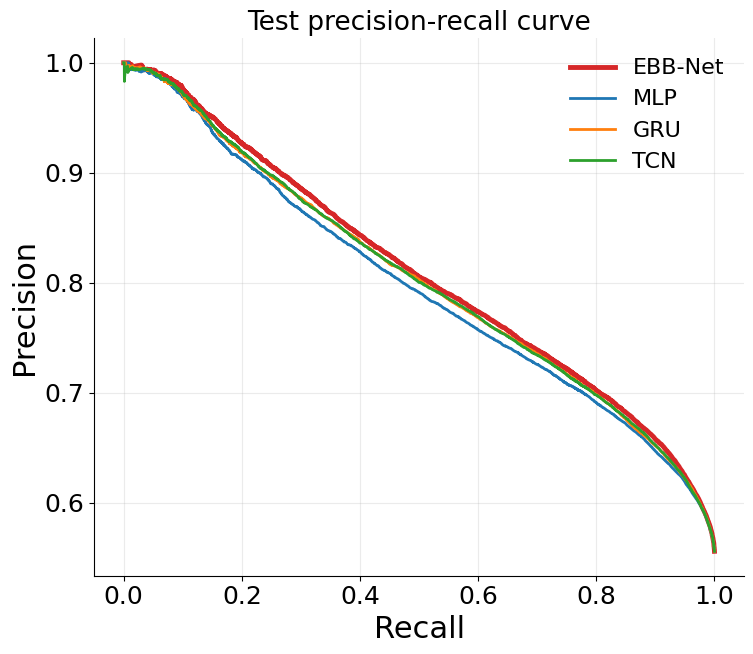

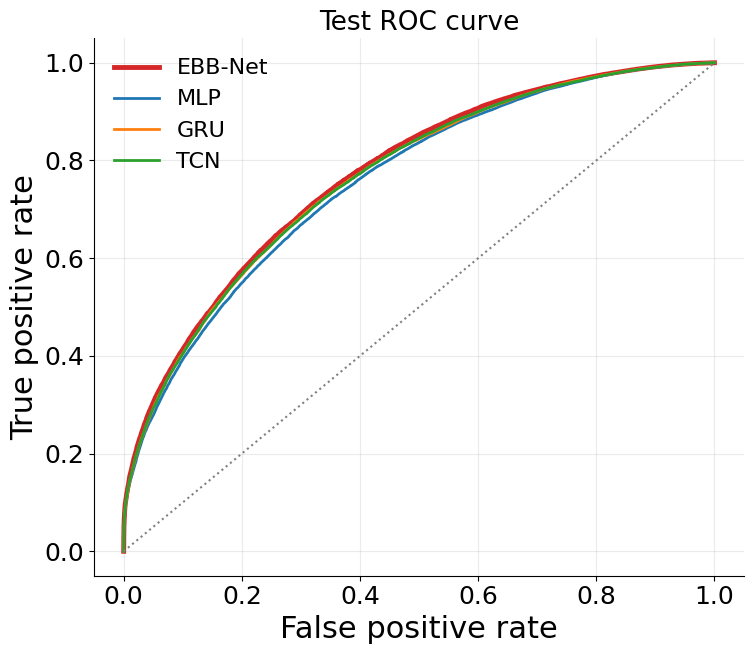

In [55]:
# Test precision-recall and ROC curves: EBB-Net vs SOTA models
plot_curves([PROPOSED] + [r for r in SOTA if r in ORDER], "sota_vs_proposed")

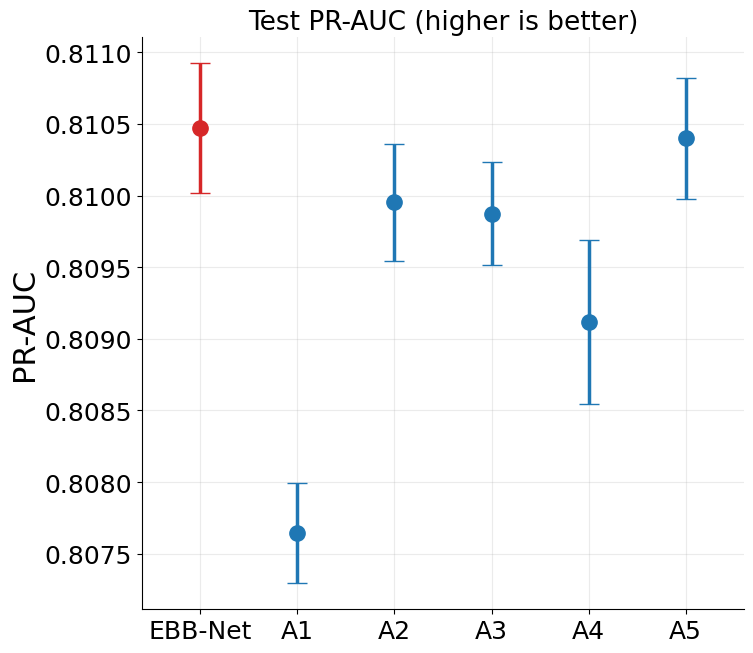

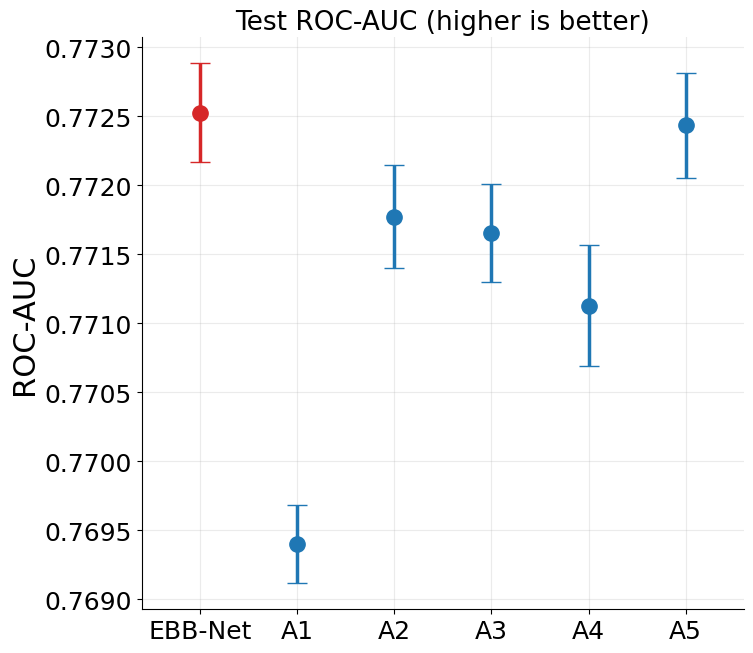

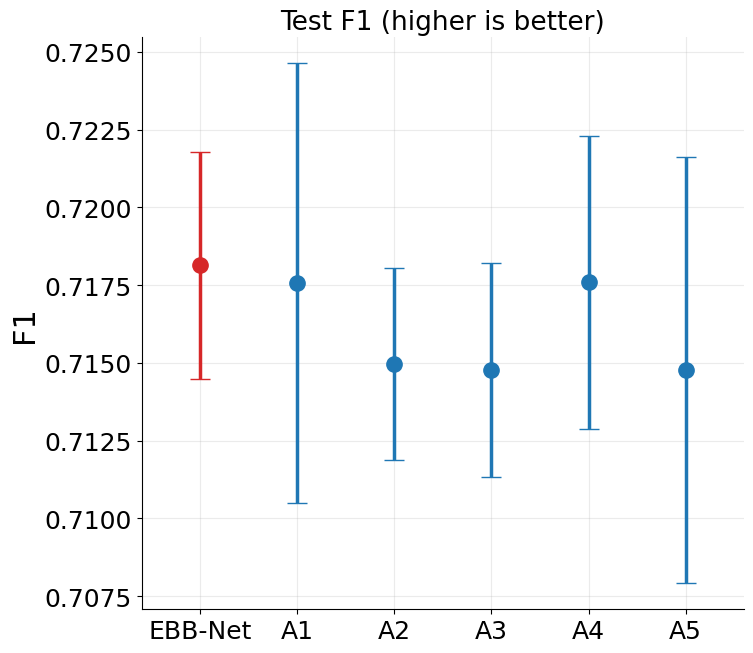

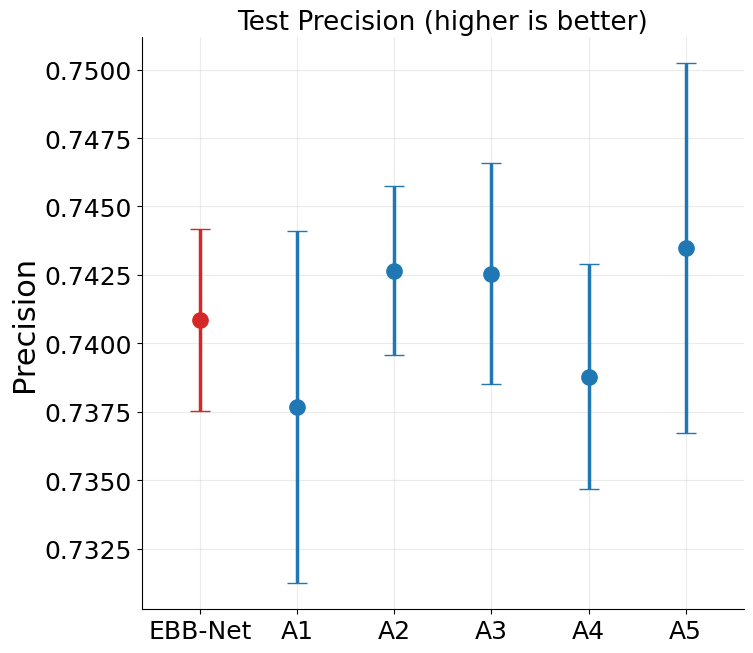

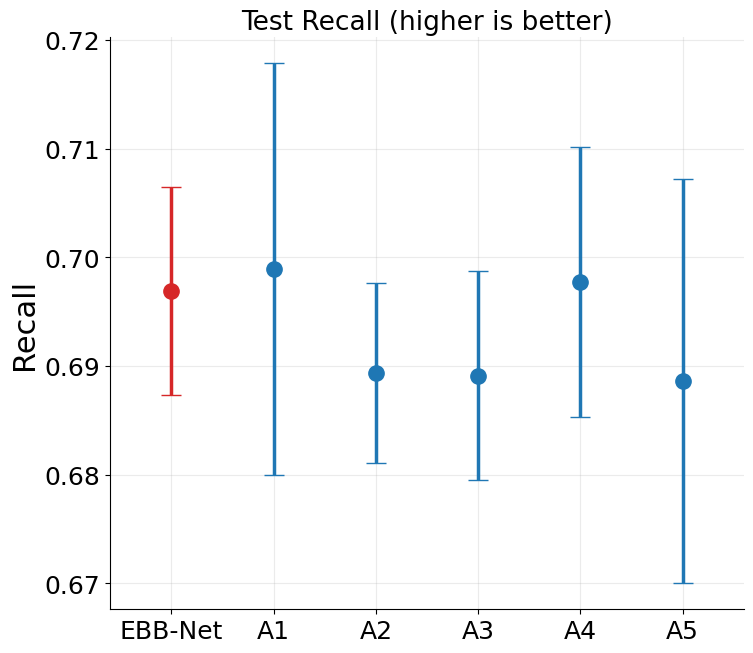

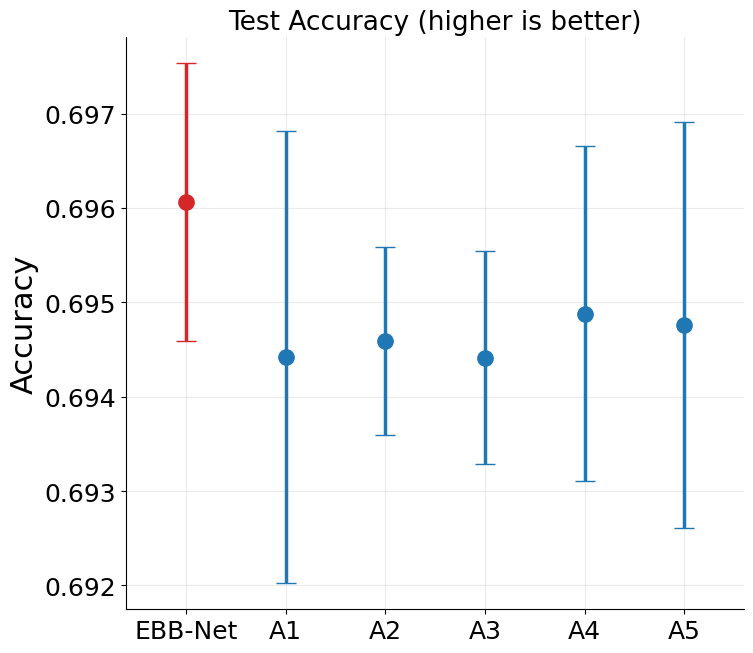

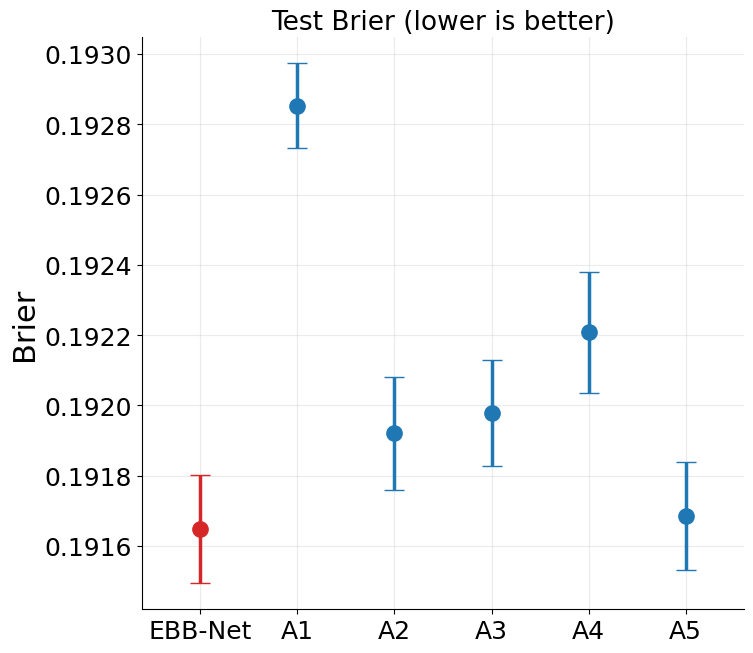

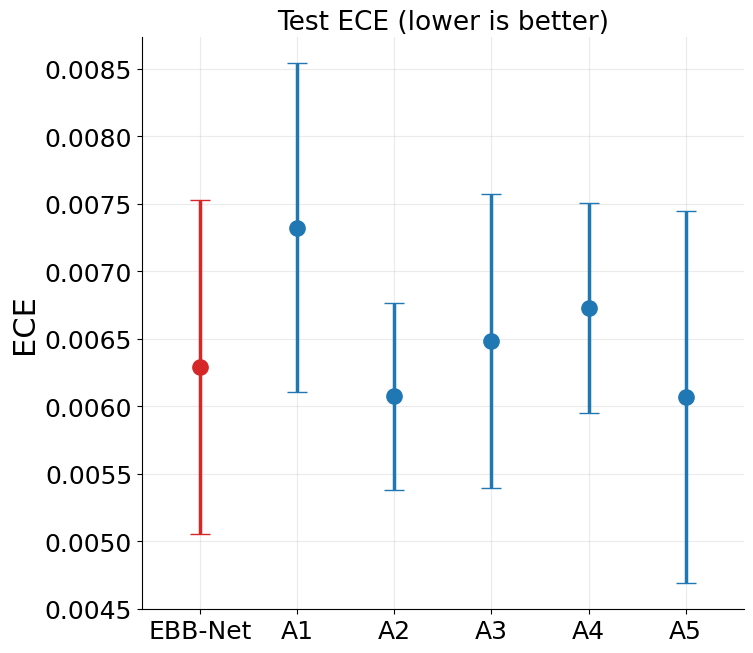

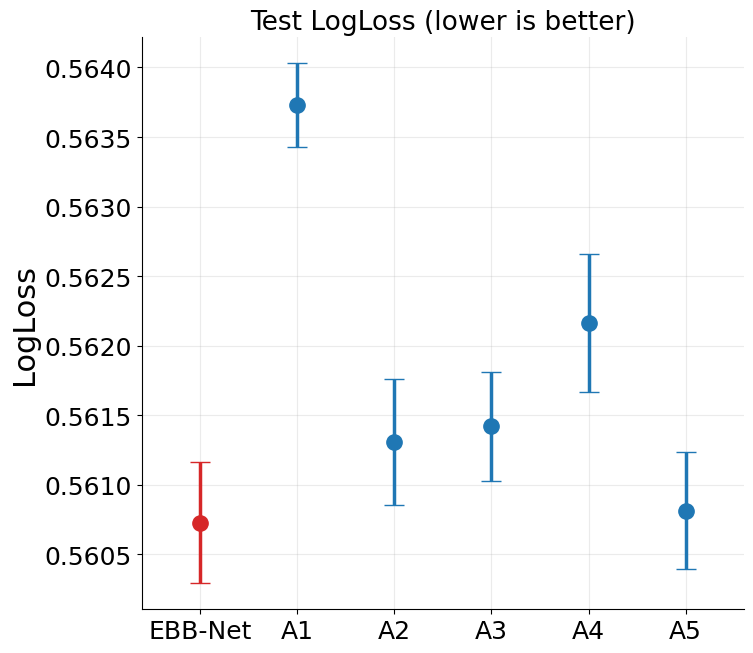

In [56]:
# Test comparison: EBB-Net vs ablations A1-A5, one figure per metric
plot_compare([PROPOSED] + [r for r in ABLATIONS if r in ORDER], "ablations_vs_proposed")

In [ ]:
# Test precision-recall and ROC curves: EBB-Net vs ablations
plot_curves([PROPOSED] + [r for r in ABLATIONS if r in ORDER], "ablations_vs_proposed")

# Calibration, Uncertainty and Confidence Intervals (EBB-Net)

In [58]:
# Seed ensemble with per-history-bucket temperature scaling and conformal sets (fitted on validation only), uncertainty, student-level bootstrap CI
def history_bucket_arr(w): w = np.asarray(w); return np.select([w <= 4, w <= 8, w <= 16], ["3-4", "5-8", "9-16"], default="17+")
def fit_temperature(y, p):
    y = np.asarray(y, float); p = np.clip(np.asarray(p), 1e-6, 1 - 1e-6); z = np.log(p / (1 - p)); best_t, best = 1.0, 1e9
    for t in np.exp(np.linspace(np.log(.25), np.log(5), 121)):
        q = np.clip(1 / (1 + np.exp(-z / t)), 1e-9, 1 - 1e-9); l = -(y * np.log(q) + (1 - y) * np.log(1 - q)).mean()
        if l < best: best, best_t = l, float(t)
    return best_t
def apply_temperature(p, t): p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); return 1 / (1 + np.exp(-np.log(p / (1 - p)) / np.asarray(t, float)))
def ent(p): p = np.clip(p, 1e-8, 1 - 1e-8); return -(p * np.log(p) + (1 - p) * np.log(1 - p))
def student_bootstrap_ci(y, p, students, n_boot=500, seed=42):
    codes, _ = pd.factorize(np.asarray(students)); ns = codes.max() + 1; rs = np.random.RandomState(seed); vals = []
    for _ in range(n_boot):
        w = np.bincount(rs.randint(0, ns, ns), minlength=ns)[codes]
        if w.sum() and len(np.unique(y[w > 0])) == 2: vals.append(average_precision_score(y, p, sample_weight=w))
    return np.percentile(vals, [2.5, 50, 97.5])

def build_ensemble(run_name, seeds, alpha=0.10):
    Ld = lambda s, sp: np.load(RUN_ROOT / run_name / f"seed_{s}" / f"preds_{sp}.npz")
    pv, pt = np.stack([Ld(s, "val")["p"] for s in seeds], 1), np.stack([Ld(s, "test")["p"] for s in seeds], 1)
    yv, yt = Ld(seeds[0], "val")["y"], Ld(seeds[0], "test")["y"]; mv, mt = DATA["val"]["meta"], DATA["test"]["meta"]
    bv, bt = history_bucket_arr(mv["weeks_observed"]), history_bucket_arr(mt["weeks_observed"]); vm, tm = pv.mean(1), pt.mean(1)
    temps = {b: (fit_temperature(yv[bv == b], vm[bv == b]) if (bv == b).sum() >= 20 and len(np.unique(yv[bv == b])) == 2 else 1.0) for b in np.unique(bv)}
    vc, tc = apply_temperature(vm, np.array([temps.get(b, 1.0) for b in bv])), apply_temperature(tm, np.array([temps.get(b, 1.0) for b in bt]))
    scores = np.where(yv == 1, 1 - vc, vc); n = len(scores); k = min(max(int(np.ceil((n + 1) * (1 - alpha))) - 1, 0), n - 1); q = float(np.sort(scores)[k])
    inc1, inc0 = (1 - tc) <= q, tc <= q; size = inc0.astype(int) + inc1.astype(int); covered = np.where(yt == 1, inc1, inc0); thr = find_threshold(yv, vc)
    met = binary_metrics(yt, tc, thr); met.update(threshold=thr, conformal_q=q, conformal_coverage=float(covered.mean()), conformal_mean_set_size=float(size.mean()))
    out = mt.copy(); out["y_true"] = yt; out["p_raw_ensemble"] = tm; out["p_calibrated"] = tc; out["epistemic_mi"] = ent(tc) - ent(pt).mean(1); out["aleatoric_entropy"] = ent(pt).mean(1)
    out["conformal_set"] = np.select([size == 2, (size == 1) & inc1, (size == 1) & inc0], ["{0,1}", "{1}", "{0}"], default="{}"); out["pred_label"] = (tc >= thr).astype(int)
    d = RUN_ROOT / run_name / "ensemble"; d.mkdir(exist_ok=True); out.to_csv(d / "test_predictions_ensemble.csv", index=False)
    ci = student_bootstrap_ci(yt, tc, mt["id_student"].to_numpy())
    save_json({"temperatures": temps, "conformal_q": q, "metrics": met, "seeds": list(seeds), "pr_auc_bootstrap_ci95": ci.tolist()}, d / "ensemble_config.json")
    return met, temps, ci

done_seeds = [s for s in SEEDS if (RUN_ROOT / PROPOSED / f"seed_{s}" / "preds_test.npz").exists()]
if len(done_seeds) >= 2:
    ens_met, ens_temps, ens_ci = build_ensemble(PROPOSED, done_seeds)
    print(f"EBB-Net ensemble of {len(done_seeds)} seeds (test)"); display(pd.DataFrame([ens_met]).T.rename(columns={0: "value"}))
    print("temperature per history bucket:", ens_temps, "| PR-AUC 95% student-bootstrap CI (2.5 / 50 / 97.5):", np.round(ens_ci, 4))
    dfe = pd.read_csv(RUN_ROOT / PROPOSED / "ensemble" / "test_predictions_ensemble.csv", float_precision="round_trip"); dfe["history"] = history_bucket_arr(dfe["weeks_observed"])
    bt_ = pd.DataFrame([{"history (weeks)": b_, "n": len(g), "positive rate": g["y_true"].mean(), "PR-AUC": average_precision_score(g["y_true"], g["p_calibrated"]),
                         "ROC-AUC": roc_auc_score(g["y_true"], g["p_calibrated"])} for b_, g in dfe.groupby("history") if g["y_true"].nunique() == 2]).set_index("history (weeks)")
    display(bt_.round(4)); bt_.to_csv(RUN_ROOT / PROPOSED / "ensemble" / "performance_by_history.csv")
else: print("The ensemble needs at least 2 finished EBB-Net seeds.")
push(RUN_ROOT / PROPOSED)

EBB-Net ensemble of 10 seeds (test)


,value
pr_auc,0.813236
roc_auc,0.775669
f1,0.723117
precision,0.741883
recall,0.705276
accuracy,0.699859
brier,0.190391
ece,0.006002
logloss,0.557580
threshold,0.550000


temperature per history bucket: {np.str_('17+'): 1.0117829111758085, np.str_('3-4'): 0.9868369977195095, np.str_('5-8'): 1.0635824763180661, np.str_('9-16'): 1.0117829111758085} | PR-AUC 95% student-bootstrap CI (2.5 / 50 / 97.5): [0.8099 0.8132 0.8166]


,n,positive rate,PR-AUC,ROC-AUC
history (weeks),,,,
17+,44631,0.5503,0.8328,0.7935
3-4,7139,0.5700,0.7459,0.7102
5-8,13232,0.5897,0.7783,0.7233
9-16,21284,0.5411,0.8012,0.7829


# Explainability (EBB-Net): SHAP and LIME

In [ ]:
# Load the best EBB-Net seed and prepare the flattened input (6 weeks x dynamic features + static features + mask) for SHAP and LIME
def load_best_model(run_name=PROPOSED):
    rows = [(json.load(open(p))["best_val_select_metric"], int(p.parent.name.split("_")[1])) for p in (RUN_ROOT / run_name).glob("seed_*/best_summary.json")]
    seed = max(rows)[1]; ck = torch.load(RUN_ROOT / run_name / f"seed_{seed}" / "best_model.pt", map_location=DEVICE, weights_only=False)
    m = build_from_cfg(ck["config"]).to(DEVICE); m.load_state_dict(ck["model_state_dict"]); m.eval(); return m, ck["config"], seed, float(ck["best_threshold"])
xai_model, xai_cfg, xai_seed, xai_thr = load_best_model()
print("explaining EBB-Net seed", xai_seed, "| threshold", round(xai_thr, 3))
NT, ND, NS = SEQ_LEN, len(DYN_FEATURES), len(STATIC_FEATURES)
FLAT_NAMES = [f"{f} (t{'-' + str(NT - 1 - w) if w < NT - 1 else ''})" for w in range(NT) for f in DYN_FEATURES] + list(STATIC_FEATURES)
class FlatWrapper(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, flat):
        x = flat[:, :NT * ND].reshape(-1, NT, ND); s = flat[:, NT * ND:NT * ND + NS]; mk = flat[:, NT * ND + NS:] > 0.5
        return self.m(x, mk, s)["logit"].unsqueeze(-1)
def flat_from(split, idx):
    d = T[split]; i = torch.as_tensor(idx, device=DEVICE); return torch.cat([d["X"][i].reshape(len(idx), -1), d["S"][i], d["M"][i].float()], 1)
rng_x = np.random.RandomState(0); N_EXPLAIN, N_BG = (40, 40) if QUICK_TEST else (300, 200)
idx_test = rng_x.choice(len(DATA["test"]["y"]), min(N_EXPLAIN, len(DATA["test"]["y"])), replace=False)
idx_bg = rng_x.choice(len(DATA["train"]["y"]), min(N_BG, len(DATA["train"]["y"])), replace=False)
Xe, Xb = flat_from("test", idx_test), flat_from("train", idx_bg); wrapper = FlatWrapper(xai_model).eval()
XAI_DIR = RUN_ROOT / PROPOSED / "xai"; XAI_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# SHAP: importance by feature, feature group and week, and a beeswarm of the top features
import shap
def grad_x_input(w, Xe_, Xb_):
    X = Xe_.clone().requires_grad_(True); w(X).sum().backward(); return (X.grad * (Xe_ - Xb_.mean(0, keepdim=True))).detach().cpu().numpy()
try:
    sv = shap.GradientExplainer(wrapper, Xb).shap_values(Xe)
    if isinstance(sv, list): sv = sv[0]
    sv = np.asarray(sv); sv = sv[..., 0] if sv.ndim == 3 else sv; method = "SHAP GradientExplainer"
except Exception as e:
    print("GradientExplainer failed (", type(e).__name__, str(e)[:100], ") -> gradient x input fallback"); sv = grad_x_input(wrapper, Xe, Xb); method = "gradient x input (fallback)"
sv = sv[:, :NT * ND + NS]; Xn = Xe[:, :NT * ND + NS].cpu().numpy(); print("method:", method, "| array:", sv.shape)
sv_seq, sv_sta = sv[:, :NT * ND].reshape(-1, NT, ND), sv[:, NT * ND:]
feat_imp, sta_imp, week_imp = np.abs(sv_seq).mean(0).sum(0), np.abs(sv_sta).mean(0), np.abs(sv_seq).mean(0).sum(1)
grp_imp = {g: float(np.abs(sv_seq[:, :, [i for i, f in enumerate(DYN_FEATURES) if gmap[f] == g]]).mean(0).sum()) for g in GROUP_NAMES}; grp_imp["static context"] = float(sta_imp.sum())
imp_df = pd.concat([pd.DataFrame({"feature": DYN_FEATURES, "type": "dynamic", "mean_abs_shap": feat_imp}), pd.DataFrame({"feature": STATIC_FEATURES, "type": "static", "mean_abs_shap": sta_imp})]).sort_values("mean_abs_shap", ascending=False)
imp_df.to_csv(XAI_DIR / "shap_feature_importance.csv", index=False); pd.Series(grp_imp).sort_values(ascending=False).to_csv(XAI_DIR / "shap_group_importance.csv")
def barh(names, vals, title, fn, top=20):
    o = np.argsort(vals)[::-1][:top][::-1]
    with plt.rc_context({"font.size": 16}):
        fig, ax = plt.subplots(figsize=(10, 8)); ax.barh(np.array(names)[o], np.array(vals)[o], color=BLUE); ax.set_xlabel("mean |SHAP| (log-odds)"); ax.set_title(title); tidy(ax)
        fig.tight_layout(); fig.savefig(XAI_DIR / fn, dpi=PLOT_DPI, bbox_inches="tight"); plt.show(); plt.close(fig)
barh(imp_df.feature.tolist(), imp_df.mean_abs_shap.tolist(), "Top features (all weeks summed)", "shap_top_features.png")
barh(list(grp_imp), list(grp_imp.values()), "Importance by feature group", "shap_groups.png")
with plt.rc_context({"font.size": 16}):
    fig, ax = plt.subplots(figsize=(8, 6)); ax.bar([f"t-{NT - 1 - w}" if w < NT - 1 else "t" for w in range(NT)], week_imp, color=BLUE)
    ax.set_xlabel("Week"); ax.set_ylabel("mean |SHAP|"); ax.set_title("Importance by week"); tidy(ax)
    fig.tight_layout(); fig.savefig(XAI_DIR / "shap_weeks.png", dpi=PLOT_DPI, bbox_inches="tight"); plt.show(); plt.close(fig)
plt.figure(); shap.summary_plot(sv, Xn, feature_names=FLAT_NAMES, max_display=20, show=False); plt.gcf().set_size_inches(11, 8)
plt.savefig(XAI_DIR / "shap_beeswarm.png", dpi=PLOT_DPI, bbox_inches="tight"); plt.show()
display(imp_df.head(15))

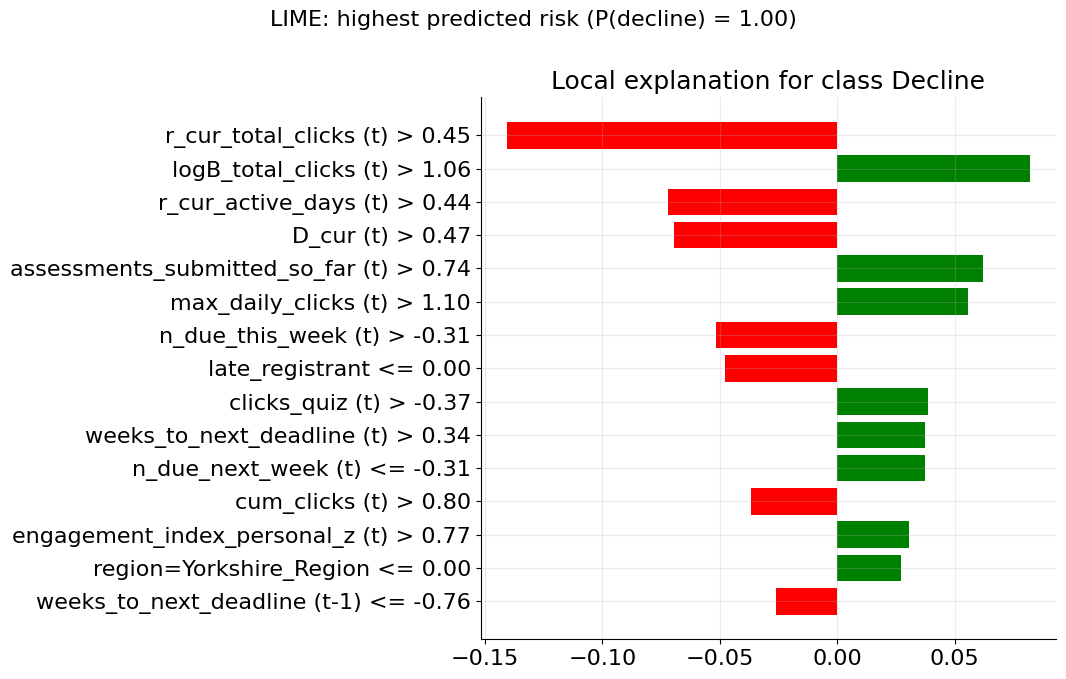

,condition,weight
0,r_cur_total_clicks (t) > 0.45,-0.140643
1,logB_total_clicks (t) > 1.06,0.081947
2,r_cur_active_days (t) > 0.44,-0.071899
3,D_cur (t) > 0.47,-0.069623
4,assessments_submitted_so_far (t) > 0.74,0.062028
5,max_daily_clicks (t) > 1.10,0.055712
6,n_due_this_week (t) > -0.31,-0.051585
7,late_registrant <= 0.00,-0.047777
8,clicks_quiz (t) > -0.37,0.038628
9,weeks_to_next_deadline (t) > 0.34,0.037373


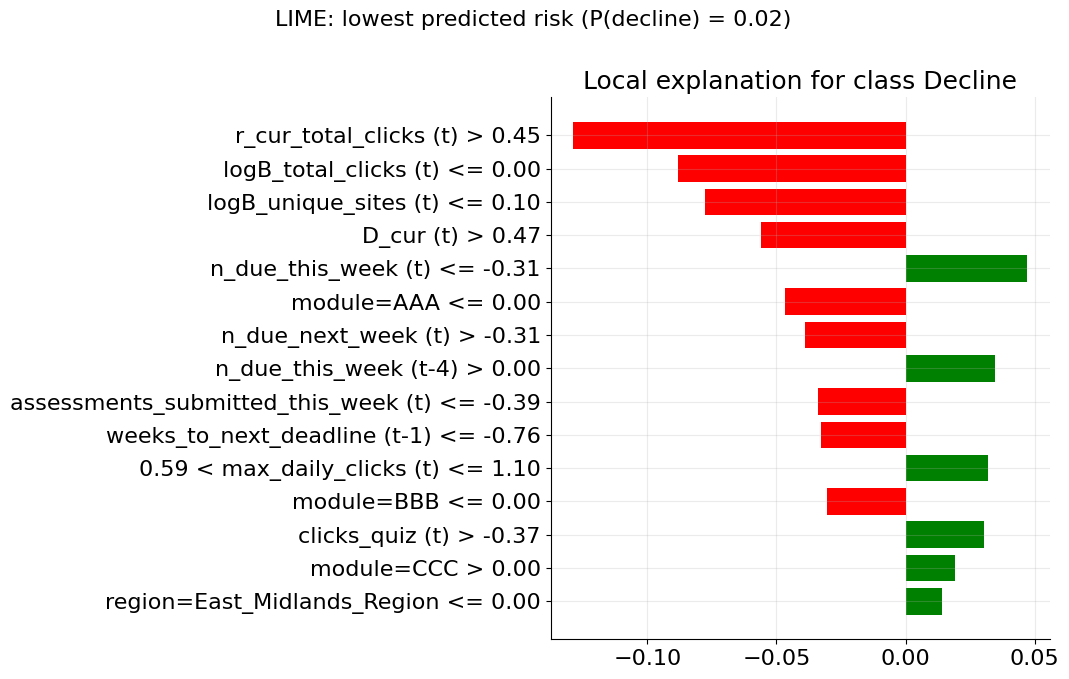

,condition,weight
0,r_cur_total_clicks (t) > 0.45,-0.128669
1,logB_total_clicks (t) <= 0.00,-0.087962
2,logB_unique_sites (t) <= 0.10,-0.077605
3,D_cur (t) > 0.47,-0.056174
4,n_due_this_week (t) <= -0.31,0.047082
5,module=AAA <= 0.00,-0.046718
6,n_due_next_week (t) > -0.31,-0.039086
7,n_due_this_week (t-4) > 0.00,0.034725
8,assessments_submitted_this_week (t) <= -0.39,-0.033895
9,weeks_to_next_deadline (t-1) <= -0.76,-0.032860


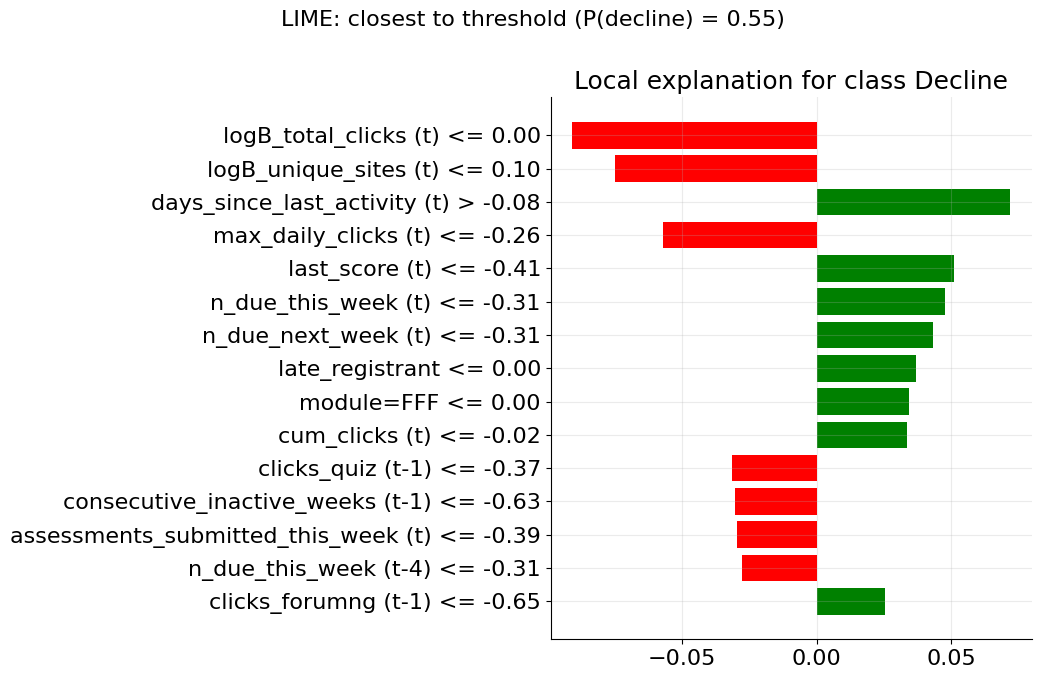

,condition,weight
0,logB_total_clicks (t) <= 0.00,-0.090775
1,logB_unique_sites (t) <= 0.10,-0.074784
2,days_since_last_activity (t) > -0.08,0.072063
3,max_daily_clicks (t) <= -0.26,-0.056986
4,last_score (t) <= -0.41,0.051009
5,n_due_this_week (t) <= -0.31,0.047617
6,n_due_next_week (t) <= -0.31,0.043333
7,late_registrant <= 0.00,0.037176
8,module=FFF <= 0.00,0.034295
9,cum_clicks (t) <= -0.02,0.033526


In [61]:
# LIME: local explanations for the highest-risk, lowest-risk and closest-to-threshold test samples
from lime.lime_tabular import LimeTabularExplainer
bg_np = flat_from("train", rng_x.choice(len(DATA["train"]["y"]), min(2000, len(DATA["train"]["y"])), replace=False))[:, :NT * ND + NS].cpu().numpy()
ex_flat = Xe.cpu().numpy()
with torch.no_grad(): p_ex = torch.sigmoid(wrapper(Xe)).squeeze(-1).cpu().numpy()
pick = {"highest predicted risk": int(np.argmax(p_ex)), "lowest predicted risk": int(np.argmin(p_ex)), "closest to threshold": int(np.argmin(np.abs(p_ex - xai_thr)))}
lime_exp = LimeTabularExplainer(bg_np, feature_names=FLAT_NAMES, class_names=["No decline", "Decline"], mode="classification", discretize_continuous=True, random_state=42)
for title, i in pick.items():
    mask_i = torch.tensor(ex_flat[i, NT * ND + NS:], device=DEVICE) > 0.5
    def predict_fn(a, mask_i=mask_i):
        out = []
        for j in range(0, len(a), 1024):
            z = torch.tensor(a[j:j + 1024], dtype=torch.float32, device=DEVICE); n = len(z)
            with torch.no_grad(): lg = xai_model(z[:, :NT * ND].reshape(n, NT, ND), mask_i.unsqueeze(0).expand(n, -1), z[:, NT * ND:])["logit"]
            out.append(torch.sigmoid(lg).cpu().numpy())
        p = np.concatenate(out); return np.stack([1 - p, p], 1)
    exp = lime_exp.explain_instance(ex_flat[i, :NT * ND + NS], predict_fn, num_features=15, num_samples=500 if QUICK_TEST else 3000)
    tag = title.replace(" ", "_"); exp.save_to_file(str(XAI_DIR / f"lime_{tag}.html"))
    fig = exp.as_pyplot_figure(); fig.set_size_inches(11, 7); fig.suptitle(f"LIME: {title} (P(decline) = {p_ex[i]:.2f})", fontsize=16); fig.tight_layout()
    fig.savefig(XAI_DIR / f"lime_{tag}.png", dpi=PLOT_DPI, bbox_inches="tight"); plt.show(); plt.close(fig)
    display(pd.DataFrame(exp.as_list(), columns=["condition", "weight"]).head(10))
push(XAI_DIR)

# Training and Inference Time

In [ ]:
# Training and inference time, for every model (neural + tabular), addressing the "time not profiled" limitation.
# Neural models: training seconds come straight from each run's epoch_log.csv ("seconds" column, written every epoch
# by train_run() already -- nothing new to measure there). Tabular models: from tabular_baselines_train_time.csv
# (written by the tabular-baselines cell). Inference latency is measured here for EBB-Net directly: a batched pass
# over the test split and a single-row (batch size 1) pass, using the best saved EBB-Net checkpoint.
# Run this cell after the Explainability section (it reuses xai_model / xai_cfg loaded there); if you haven't run
# that section, call load_best_model(PROPOSED) yourself first.

rows_time = []
for run_name in list(RUNS):
    if RUNS[run_name]["kind"] in ("ebb", "sota"):
        for sd in sorted((RUN_ROOT / run_name).glob("seed_*")):
            log_p = sd / "epoch_log.csv"
            if log_p.exists():
                df_log = pd.read_csv(log_p)
                rows_time.append({"run": run_name, "seed": int(sd.name.split("_")[1]),
                                   "train_seconds_total": float(df_log["seconds"].sum()), "epochs_run": len(df_log)})

tab_time_p = RUN_ROOT / "tabular_baselines_train_time.csv"
if tab_time_p.exists():
    tt = pd.read_csv(tab_time_p)
    for _, r in tt.iterrows():
        rows_time.append({"run": r["run"], "seed": int(r["seed"]), "train_seconds_total": float(r["train_seconds"]),
                           "epochs_run": np.nan})

TIME_DF = pd.DataFrame(rows_time)
if len(TIME_DF):
    TIME_SUMMARY = TIME_DF.groupby("run")["train_seconds_total"].agg(["mean", "std", "count"]) \
        .rename(columns={"mean": "train_s_mean", "std": "train_s_sd", "count": "n_seeds"})
    TIME_SUMMARY.index = [RUNS[r]["label"] for r in TIME_SUMMARY.index]
    display(TIME_SUMMARY.round(2))
    TIME_SUMMARY.to_csv(RUN_ROOT / "table_training_time.csv")
else:
    print("No epoch_log.csv / tabular_baselines_train_time.csv found yet -- run the training cells first.")

@torch.no_grad()
def inference_latency(model, split="test", n_warmup=3, n_repeat=10):
    model.eval(); d = T[split]

    def timed_batched_pass(bs):
        times = []
        for _ in range(n_warmup + n_repeat):
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            t0 = time.time()
            for x, m, s, y, de in batches(split, bs):
                _ = model(x, m, s)
            if DEVICE.type == "cuda": torch.cuda.synchronize()
            times.append(time.time() - t0)
        return np.array(times[n_warmup:])

    full = timed_batched_pass(EVAL_BATCH_SIZE)
    n_single = min(500, len(d["y"]))
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for i in range(n_single):
        _ = model(d["X"][i:i + 1], d["M"][i:i + 1], d["S"][i:i + 1])
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    single_total = time.time() - t0
    return {"batch_size": EVAL_BATCH_SIZE, "full_pass_seconds_mean": float(full.mean()),
            "full_pass_seconds_sd": float(full.std()), "rows_per_second_batched": len(d["y"]) / float(full.mean()),
            "single_sample_ms_mean": 1000 * single_total / n_single, "n_single_samples": n_single}

if "xai_model" not in dir():
    xai_model, xai_cfg, xai_seed, xai_thr = load_best_model(PROPOSED)

lat = inference_latency(xai_model)
print(f"EBB-Net inference (seed {xai_seed}): batched {lat['rows_per_second_batched']:.0f} rows/s "
      f"(batch={lat['batch_size']}) | single-sample latency {lat['single_sample_ms_mean']:.3f} ms/row "
      f"(n={lat['n_single_samples']})")
save_json(lat, RUN_ROOT / PROPOSED / "inference_latency.json")


# Inference with Saved EBB-Net Models

In [ ]:
# Predict with the EBB-Net seed ensemble (calibrated) on any folder in the prepared-data format; the default is the test split
INFERENCE_DATA = PREP_DIR / "test"      # folder with X_seq.npy, X_static.npy [, mask.npy, meta.csv, y.npy]
INFERENCE_OUT = RUN_ROOT / PROPOSED / "inference"; INFERENCE_OUT.mkdir(parents=True, exist_ok=True)
ckpts = sorted((RUN_ROOT / PROPOSED).glob("seed_*/best_model.pt")); assert ckpts, "no EBB-Net checkpoints found"
dp = Path(INFERENCE_DATA); Xi, Si = np.load(dp / "X_seq.npy"), np.load(dp / "X_static.npy")
Mi = np.load(dp / "mask.npy") if (dp / "mask.npy").exists() else np.ones((len(Xi), SEQ_LEN), dtype=bool)
Yi = np.load(dp / "y.npy") if (dp / "y.npy").exists() else None; metai = pd.read_csv(dp / "meta.csv") if (dp / "meta.csv").exists() else None
if QUICK_TEST: Xi, Si, Mi = Xi[:2000], Si[:2000], Mi[:2000]; Yi = Yi[:2000] if Yi is not None else None; metai = metai.iloc[:2000] if metai is not None else None
assert Xi.shape[1:] == (SEQ_LEN, len(DYN_FEATURES)) and Si.shape[1] == len(STATIC_FEATURES) and Mi[:, -1].all() and np.isfinite(Xi).all() and np.isfinite(Si).all()
Nn, Pm = len(Xi), []
with torch.no_grad():
    for c in ckpts:
        ck = torch.load(c, map_location=DEVICE, weights_only=False); m = build_from_cfg(ck["config"]).to(DEVICE); m.load_state_dict(ck["model_state_dict"]); m.eval(); ps = []
        for i in range(0, Nn, 4096):
            o = m(torch.as_tensor(Xi[i:i + 4096], dtype=torch.float32, device=DEVICE), torch.as_tensor(Mi[i:i + 4096].astype(bool), device=DEVICE), torch.as_tensor(Si[i:i + 4096], dtype=torch.float32, device=DEVICE))
            ps.append(torch.sigmoid(o["logit"].float()).cpu().numpy())
        Pm.append(np.concatenate(ps))
Pm = np.stack(Pm, 1); p_raw = Pm.mean(1); p_final, thr_i = p_raw.copy(), float(np.mean([torch.load(c, map_location="cpu", weights_only=False)["best_threshold"] for c in ckpts]))
cj = RUN_ROOT / PROPOSED / "ensemble" / "ensemble_config.json"
if cj.exists() and len(ckpts) > 1 and metai is not None and "weeks_observed" in metai:
    ec = json.load(open(cj)); tt = np.array([ec["temperatures"].get(b, 1.0) for b in history_bucket_arr(metai["weeks_observed"])]); p_final = apply_temperature(p_raw, tt); thr_i = float(ec["metrics"]["threshold"]); print("applied validation-fitted calibration")
risk = np.where(p_final >= thr_i, "HIGH", np.where(p_final >= 0.6 * thr_i, "MEDIUM", "LOW"))
resi = pd.DataFrame({"decline_probability_%": np.round(100 * p_final, 1), "risk_level": risk, "model_agreement": np.where(Pm.std(1) < 0.03, "high", np.where(Pm.std(1) < 0.08, "medium", "low")), "predicted_label": (p_final >= thr_i).astype(int)})
if metai is not None:
    for c_ in ["id_student", "code_module", "code_presentation", "t_week", "weeks_observed"]:
        if c_ in metai: resi.insert(0, c_, metai[c_].to_numpy())
resi = resi.sort_values("decline_probability_%", ascending=False); resi.to_csv(INFERENCE_OUT / "predictions.csv", index=False)
print(f"{Nn} student-weeks | models: {len(ckpts)} | decision threshold {thr_i:.3f}"); print(resi["risk_level"].value_counts().reindex(["HIGH", "MEDIUM", "LOW"]).fillna(0).astype(int).to_string())
display(resi.head(15))
if Yi is not None: print({NICE[k]: round(v, 4) for k, v in binary_metrics(Yi, p_final, thr_i).items()})
push(INFERENCE_OUT)

*To score new data, run the same preprocessing on the new records with the saved `scaler_params.json` and point `INFERENCE_DATA` to the resulting folder.*

# Final Backup

In [64]:
# Final synchronisation of every output to Drive and a list of the main result files
push(RUN_ROOT)
print("Local outputs :", RUN_ROOT); print("Drive outputs :", DRIVE_OUT if BACKUP else "(Drive backup unavailable)")
for f in ["results_tables.md", "table_test_mean_sd.csv", "table_paired_delta_vs_EBB-Net.csv", "best_hparams.json", "model_parameters.csv"]:
    print(("  ok  " if (RUN_ROOT / f).exists() else " miss "), f)
print("folders:", sorted(p.name for p in RUN_ROOT.iterdir() if p.is_dir()))

Local outputs : /content/EBB-Net_Outputs
Drive outputs : /content/drive/MyDrive/hari/EBB-NET-REWORK/EBB-Net_Outputs
  ok   results_tables.md
  ok   table_test_mean_sd.csv
  ok   table_paired_delta_vs_EBB-Net.csv
  ok   best_hparams.json
  ok   model_parameters.csv
folders: ['A1_no_group_tokens', 'A2_no_film', 'A3_no_temporal_tcn', 'A4_binary_only', 'A5_no_delta_regression', 'EBB-Net', 'GRU', 'LightGBM', 'MLP', 'RandomForest', 'RidgeLogReg', 'TCN', 'XGBoost', 'comparison_plots', 'eda', 'prepared_data', 'tuning']
